In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/README.md
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/label/train_6.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/label/train_7.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/label/train_9.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/label/train_5.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/label/train_1.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/label/train_10.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/label/train_3.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/label/train_2.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/label/t

In [2]:

import os
import sys
import shutil
import platform
import torch
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 65)
print("STEP 1: ENVIRONMENT AND PROJECT STATUS")
print("=" * 65)

# 1. System information
print("\n[1] SYSTEM")
print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

# 2. GPU information
print("\n[2] GPU")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1e9,
            2
        )
    )
else:
    print("No GPU detected. Do not start model training yet.")

# 3. Disk space
print("\n[3] DISK SPACE")
for path in ["/kaggle/working", "/kaggle/input"]:
    if os.path.exists(path):
        total, used, free = shutil.disk_usage(path)
        print(
            path,
            "| Total:", round(total / 1e9, 2), "GB",
            "| Free:", round(free / 1e9, 2), "GB"
        )

# 4. LEVIR-CD dataset
print("\n[4] LEVIR-CD DATASET")

DATA_DIR = Path(
    "/kaggle/input/datasets/simranmaniyar/"
    "levir-cd-change-detection/LEVIR-CD+"
)

print("Expected dataset path:", DATA_DIR)
print("Dataset path exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    print("Top-level entries:", sorted(os.listdir(DATA_DIR)))

    for split in ["train", "test", "small_train"]:
        split_path = DATA_DIR / split
        if split_path.exists():
            print(f"\n{split}/")
            for subfolder in ["A", "B", "label"]:
                folder = split_path / subfolder
                if folder.exists():
                    files = [
                        f for f in folder.iterdir()
                        if f.is_file()
                    ]
                    print(f"  {subfolder}: {len(files)} files")
                else:
                    print(f"  {subfolder}: NOT FOUND")

# 5. Existing checkpoint and previous results
print("\n[5] EXISTING PROJECT FILES")

check_paths = [
    "/kaggle/working/levir_unet_best.pth",
    "/kaggle/working/LEVIR_uncertainty_validation_results.zip",
    "/kaggle/working/LEVIR_uncertainty_validation_results_updated.zip",
    "/kaggle/working/uncertainty_validation_results"
]

for path in check_paths:
    p = Path(path)
    print(path, "->", "FOUND" if p.exists() else "NOT FOUND")

# 6. S2Looking availability
print("\n[6] S2LOOKING INPUT SEARCH")

input_root = Path("/kaggle/input")
found = []

if input_root.exists():
    for root, dirs, files in os.walk(input_root):
        folder_name = os.path.basename(root).lower()
        if "s2looking" in folder_name:
            found.append(root)

print("Matching folders:", found if found else "None found yet")

print("\n" + "=" * 65)
print("STEP 1 CHECK COMPLETE")
print("Copy the complete output back to ChatGPT.")
print("=" * 65)


STEP 1: ENVIRONMENT AND PROJECT STATUS

[1] SYSTEM
Python version: 3.13.15
Platform: Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch version: 2.11.0+cu128
NumPy version: 2.1.3
Pandas version: 2.3.3

[2] GPU
CUDA available: True
GPU name: Tesla T4
CUDA version: 12.8
GPU memory (GB): 15.64

[3] DISK SPACE
/kaggle/working | Total: 20.96 GB | Free: 20.94 GB
/kaggle/input | Total: 20.96 GB | Free: 20.94 GB

[4] LEVIR-CD DATASET
Expected dataset path: /kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+
Dataset path exists: True
Top-level entries: ['README.md', 'small_train', 'test', 'train']

train/
  A: 637 files
  B: 637 files
  label: 637 files

test/
  A: 348 files
  B: 348 files
  label: 348 files

small_train/
  A: 10 files
  B: 10 files
  label: 10 files

[5] EXISTING PROJECT FILES
/kaggle/working/levir_unet_best.pth -> NOT FOUND
/kaggle/working/LEVIR_uncertainty_validation_results.zip -> NOT FOUND
/kaggle/working/LEVIR_uncertainty_validation_results_updated.zip -> N

In [3]:

import os
from pathlib import Path
from collections import Counter

S2_ROOT = Path(
    "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"
)

print("=" * 60)
print("STEP 2A: S2LOOKING DIRECTORY STRUCTURE")
print("=" * 60)

if not S2_ROOT.exists():
    print("ERROR: S2Looking path not found:", S2_ROOT)
else:
    print("Dataset path:", S2_ROOT)

    for root, dirs, files in os.walk(S2_ROOT):
        relative = Path(root).relative_to(S2_ROOT)
        depth = len(relative.parts)

        # Show folders only up to depth 4
        if depth > 4:
            dirs[:] = []
            continue

        print(f"\n{relative if str(relative) != '.' else 'S2Looking'}/")
        for name in sorted(files)[:8]:
            p = Path(root) / name
            print(f"  {name} ({p.stat().st_size / 1e6:.2f} MB)")

        if len(files) > 8:
            print(f"  ... and {len(files) - 8} more files")

print("\n" + "=" * 60)
print("STEP 2B: FILE TYPES IN S2LOOKING")
print("=" * 60)

if S2_ROOT.exists():
    extensions = Counter()
    total_files = 0

    for root, dirs, files in os.walk(S2_ROOT):
        for name in files:
            total_files += 1
            extensions[Path(name).suffix.lower() or "[no extension]"] += 1

    print("Total files:", total_files)
    print("File extensions:", extensions.most_common(15))

print("\n" + "=" * 60)
print("STEP 2C: SEARCH FOR SAVED MODEL CHECKPOINTS")
print("=" * 60)

search_roots = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

checkpoint_extensions = {".pth", ".pt", ".ckpt"}
checkpoint_files = []

for search_root in search_roots:
    if not search_root.exists():
        continue

    for root, dirs, files in os.walk(search_root):
        # Skip hidden folders and common cache folders
        dirs[:] = [
            d for d in dirs
            if not d.startswith(".") and d != "__pycache__"
        ]

        for name in files:
            p = Path(root) / name
            if p.suffix.lower() in checkpoint_extensions:
                checkpoint_files.append(p)

if checkpoint_files:
    for p in checkpoint_files:
        print(f"FOUND: {p} | {p.stat().st_size / 1e6:.2f} MB")
else:
    print("No .pth, .pt, or .ckpt files found.")

print("\nSTEP 2 COMPLETE")
print("Paste the full output here before we proceed.")


STEP 2A: S2LOOKING DIRECTORY STRUCTURE
Dataset path: /kaggle/input/datasets/simranmaniyar/s-looking/S2Looking

S2Looking/

val/

val/label/
  1001.png (0.00 MB)
  1016.png (0.00 MB)
  1020.png (0.00 MB)
  1045.png (0.00 MB)
  1054.png (0.00 MB)
  1056.png (0.00 MB)
  1057.png (0.00 MB)
  1064.png (0.00 MB)
  ... and 492 more files

val/label1/
  1001.png (0.01 MB)
  1016.png (0.01 MB)
  1020.png (0.01 MB)
  1045.png (0.00 MB)
  1054.png (0.00 MB)
  1056.png (0.00 MB)
  1057.png (0.01 MB)
  1064.png (0.01 MB)
  ... and 492 more files

val/label2/
  1001.png (0.01 MB)
  1016.png (0.00 MB)
  1020.png (0.01 MB)
  1045.png (0.01 MB)
  1054.png (0.01 MB)
  1056.png (0.01 MB)
  1057.png (0.00 MB)
  1064.png (0.00 MB)
  ... and 492 more files

val/Image1/
  1001.png (1.25 MB)
  1016.png (1.34 MB)
  1020.png (0.93 MB)
  1045.png (1.03 MB)
  1054.png (0.91 MB)
  1056.png (1.43 MB)
  1057.png (1.20 MB)
  1064.png (1.25 MB)
  ... and 492 more files

val/Image2/
  1001.png (1.00 MB)
  1016.png (0.8

STEP 3A: VERIFY IMAGE AND MASK FILE MATCHING

TRAIN
  Image1: 3500 files
  Image2: 3500 files
  label: 3500 files
  label1: 3500 files
  label2: 3500 files
  Image1 vs Image2: missing=0, extra=0
  Image1 vs label: missing=0, extra=0
  Image1 vs label1: missing=0, extra=0
  Image1 vs label2: missing=0, extra=0

VAL
  Image1: 500 files
  Image2: 500 files
  label: 500 files
  label1: 500 files
  label2: 500 files
  Image1 vs Image2: missing=0, extra=0
  Image1 vs label: missing=0, extra=0
  Image1 vs label1: missing=0, extra=0
  Image1 vs label2: missing=0, extra=0

TEST
  Image1: 1000 files
  Image2: 1000 files
  label: 1000 files
  label1: 1000 files
  label2: 1000 files
  Image1 vs Image2: missing=0, extra=0
  Image1 vs label: missing=0, extra=0
  Image1 vs label1: missing=0, extra=0
  Image1 vs label2: missing=0, extra=0

STEP 3B: INSPECT SAMPLE IMAGE AND MASK PROPERTIES

TRAIN sample: 1.png
  Image1: shape=(1024, 1024, 3), dtype=uint8, min=1, max=205, unique_values=[ 1  2  3  4  5  

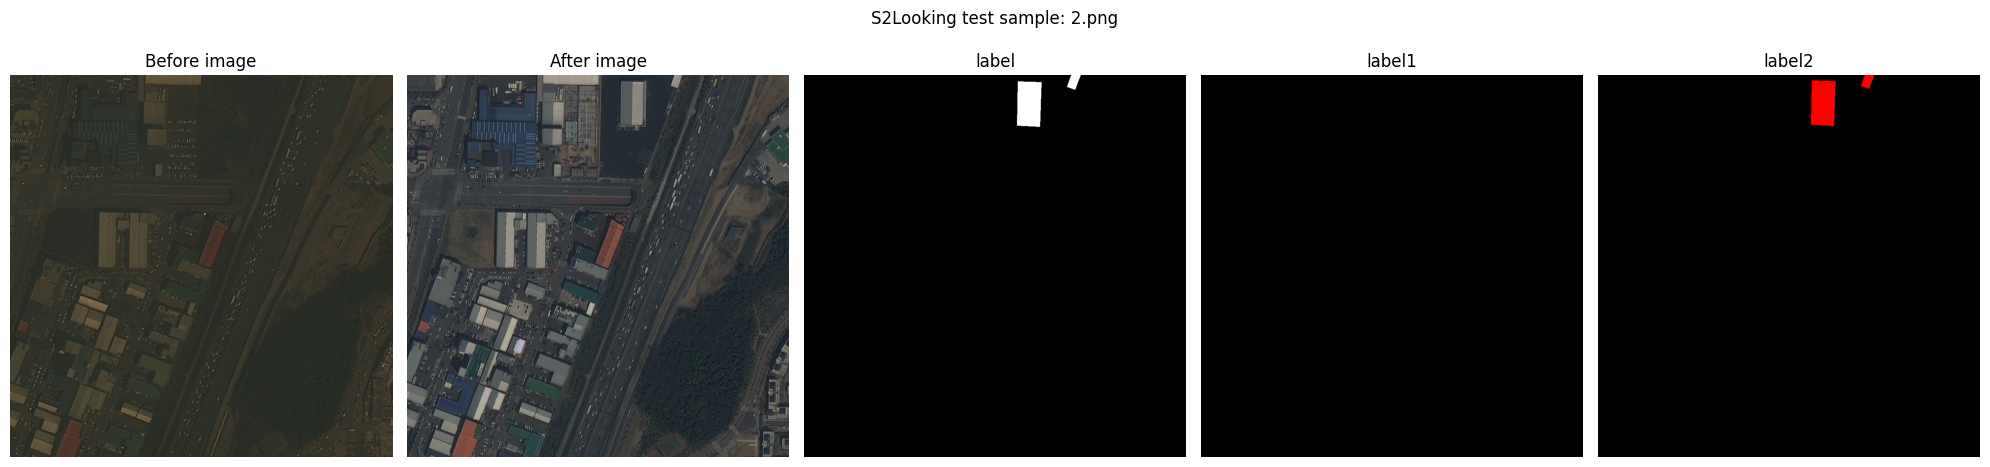


STEP 3 COMPLETE
Paste the printed output here and describe what you observe.


In [4]:

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

S2_ROOT = Path(
    "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"
)

def numeric_sort(filename):
    try:
        return (0, int(Path(filename).stem))
    except ValueError:
        return (1, filename)

print("=" * 65)
print("STEP 3A: VERIFY IMAGE AND MASK FILE MATCHING")
print("=" * 65)

for split in ["train", "val", "test"]:
    split_dir = S2_ROOT / split

    folders = ["Image1", "Image2", "label", "label1", "label2"]
    folder_files = {}

    for folder_name in folders:
        folder = split_dir / folder_name

        if not folder.exists():
            folder_files[folder_name] = set()
        else:
            folder_files[folder_name] = {
                p.name for p in folder.glob("*.png")
            }

    print(f"\n{split.upper()}")

    for folder_name in folders:
        print(f"  {folder_name}: {len(folder_files[folder_name])} files")

    reference = folder_files["Image1"]

    for folder_name in folders[1:]:
        missing = reference - folder_files[folder_name]
        extra = folder_files[folder_name] - reference

        print(
            f"  Image1 vs {folder_name}: "
            f"missing={len(missing)}, extra={len(extra)}"
        )

print("\n" + "=" * 65)
print("STEP 3B: INSPECT SAMPLE IMAGE AND MASK PROPERTIES")
print("=" * 65)

sample_ids = {}

for split in ["train", "val", "test"]:
    files = sorted(
        (S2_ROOT / split / "Image1").glob("*.png"),
        key=lambda p: numeric_sort(p.name)
    )

    if files:
        sample_ids[split] = files[0].name

for split, filename in sample_ids.items():
    print(f"\n{split.upper()} sample: {filename}")

    for folder_name in ["Image1", "Image2", "label", "label1", "label2"]:
        path = S2_ROOT / split / folder_name / filename

        if not path.exists():
            print(f"  {folder_name}: MISSING")
            continue

        with Image.open(path) as image:
            array = np.array(image)

        print(
            f"  {folder_name}: "
            f"shape={array.shape}, dtype={array.dtype}, "
            f"min={array.min()}, max={array.max()}, "
            f"unique_values={np.unique(array)[:12]}"
        )

print("\n" + "=" * 65)
print("STEP 3C: VISUALIZE ONE TEST EXAMPLE")
print("=" * 65)

split = "test"
filename = sample_ids.get(split)

if filename:
    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    folders = ["Image1", "Image2", "label", "label1", "label2"]
    titles = [
        "Before image",
        "After image",
        "label",
        "label1",
        "label2"
    ]

    for ax, folder_name, title in zip(axes, folders, titles):
        path = S2_ROOT / split / folder_name / filename

        if path.exists():
            with Image.open(path) as image:
                array = np.array(image)

            if array.ndim == 2:
                ax.imshow(array, cmap="gray")
            else:
                ax.imshow(array)

            ax.set_title(title)
        else:
            ax.set_title(title + "\nMISSING")

        ax.axis("off")

    plt.suptitle(f"S2Looking test sample: {filename}")
    plt.tight_layout()
    plt.show()

print("\nSTEP 3 COMPLETE")
print("Paste the printed output here and describe what you observe.")


In [5]:

from pathlib import Path
from PIL import Image
import numpy as np

S2_ROOT = Path(
    "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"
)

def read_binary_mask(path):
    """Convert a grayscale or RGB mask into a binary mask."""
    with Image.open(path) as im:
        arr = np.array(im)

    if arr.ndim == 3:
        # A pixel is positive if any color channel is nonzero
        binary = np.any(arr > 0, axis=2)
    else:
        binary = arr > 0

    return binary

print("=" * 65)
print("STEP 4: MASK RELATIONSHIP ANALYSIS")
print("=" * 65)

for split in ["train", "val", "test"]:
    folder = S2_ROOT / split / "label"
    files = sorted(folder.glob("*.png"), key=lambda p: int(p.stem))

    # Inspect up to 20 examples per split
    files = files[:20]

    exact_union_matches = 0
    exact_label1_matches = 0
    exact_label2_matches = 0
    results = []

    for label_path in files:
        name = label_path.name

        label = read_binary_mask(
            S2_ROOT / split / "label" / name
        )
        label1 = read_binary_mask(
            S2_ROOT / split / "label1" / name
        )
        label2 = read_binary_mask(
            S2_ROOT / split / "label2" / name
        )

        # Candidate interpretation: label is the union of label1 and label2
        union = label1 | label2

        exact_union_matches += int(np.array_equal(label, union))
        exact_label1_matches += int(np.array_equal(label, label1))
        exact_label2_matches += int(np.array_equal(label, label2))

        intersection = np.logical_and(label1, label2).sum()
        union_pixels = union.sum()

        results.append({
            "file": name,
            "label_pixels": int(label.sum()),
            "label1_pixels": int(label1.sum()),
            "label2_pixels": int(label2.sum()),
            "union_pixels": int(union_pixels),
            "label_equals_union": bool(np.array_equal(label, union)),
            "intersection_pixels": int(intersection)
        })

    print(f"\n{split.upper()} — inspected {len(files)} images")
    print("label exactly equals label1 OR label2:",
          f"{exact_union_matches}/{len(files)}")
    print("label exactly equals label1:",
          f"{exact_label1_matches}/{len(files)}")
    print("label exactly equals label2:",
          f"{exact_label2_matches}/{len(files)}")

    for row in results[:5]:
        print(row)

print("\nSTEP 4 COMPLETE")
print("Paste the output here before we proceed.")


STEP 4: MASK RELATIONSHIP ANALYSIS

TRAIN — inspected 20 images
label exactly equals label1 OR label2: 20/20
label exactly equals label1: 6/20
label exactly equals label2: 6/20
{'file': '1.png', 'label_pixels': 1143, 'label1_pixels': 215, 'label2_pixels': 928, 'union_pixels': 1143, 'label_equals_union': True, 'intersection_pixels': 0}
{'file': '3.png', 'label_pixels': 9455, 'label1_pixels': 0, 'label2_pixels': 9455, 'union_pixels': 9455, 'label_equals_union': True, 'intersection_pixels': 0}
{'file': '4.png', 'label_pixels': 543, 'label1_pixels': 543, 'label2_pixels': 0, 'union_pixels': 543, 'label_equals_union': True, 'intersection_pixels': 0}
{'file': '8.png', 'label_pixels': 6235, 'label1_pixels': 923, 'label2_pixels': 5312, 'union_pixels': 6235, 'label_equals_union': True, 'intersection_pixels': 0}
{'file': '9.png', 'label_pixels': 3234, 'label1_pixels': 2692, 'label2_pixels': 1095, 'union_pixels': 3234, 'label_equals_union': True, 'intersection_pixels': 553}

VAL — inspected 20 ima

In [6]:

from pathlib import Path
from PIL import Image
import numpy as np
import os

LEVIR_ROOT = Path(
    "/kaggle/input/datasets/simranmaniyar/"
    "levir-cd-change-detection/LEVIR-CD+"
)

print("=" * 65)
print("STEP 5A: LEVIR-CD README")
print("=" * 65)

readme = LEVIR_ROOT / "README.md"

if readme.exists():
    text = readme.read_text(encoding="utf-8", errors="replace")
    print(text[:8000])
else:
    print("README.md not found.")

print("\n" + "=" * 65)
print("STEP 5B: SOURCE DATASET FILE MATCHING")
print("=" * 65)

for split in ["train", "test"]:
    split_dir = LEVIR_ROOT / split

    folders = ["A", "B", "label"]
    file_sets = {}

    for folder_name in folders:
        folder = split_dir / folder_name
        file_sets[folder_name] = (
            {p.name for p in folder.iterdir() if p.is_file()}
            if folder.exists() else set()
        )
        print(f"{split}/{folder_name}: {len(file_sets[folder_name])}")

    reference = file_sets["A"]

    for folder_name in ["B", "label"]:
        print(
            f"{split}: A vs {folder_name} "
            f"missing={len(reference - file_sets[folder_name])}, "
            f"extra={len(file_sets[folder_name] - reference)}"
        )

print("\n" + "=" * 65)
print("STEP 5C: SAMPLE DIMENSIONS AND MASK VALUES")
print("=" * 65)

sample_path = next((LEVIR_ROOT / "train" / "A").glob("*"), None)

if sample_path is not None:
    filename = sample_path.name

    for folder_name in ["A", "B", "label"]:
        path = LEVIR_ROOT / "train" / folder_name / filename

        if not path.exists():
            print(folder_name, "MISSING:", filename)
            continue

        with Image.open(path) as image:
            arr = np.array(image)

        print(
            folder_name,
            "| file:", filename,
            "| shape:", arr.shape,
            "| dtype:", arr.dtype,
            "| min:", int(arr.min()),
            "| max:", int(arr.max()),
            "| unique values:", np.unique(arr)[:12]
        )

print("\nSTEP 5 COMPLETE")
print("Paste the output here before we proceed.")


STEP 5A: LEVIR-CD README
https://chenhao.in/LEVIR/

STEP 5B: SOURCE DATASET FILE MATCHING
train/A: 637
train/B: 637
train/label: 637
train: A vs B missing=0, extra=0
train: A vs label missing=0, extra=0
test/A: 348
test/B: 348
test/label: 348
test: A vs B missing=0, extra=0
test: A vs label missing=0, extra=0

STEP 5C: SAMPLE DIMENSIONS AND MASK VALUES
A | file: train_429.png | shape: (1024, 1024, 3) | dtype: uint8 | min: 4 | max: 221 | unique values: [ 4  5  6  7  9 10 11 12 13 14 15 16]
B | file: train_429.png | shape: (1024, 1024, 3) | dtype: uint8 | min: 0 | max: 255 | unique values: [ 0  1  2  3  4  5  6  7  8  9 10 11]
label | file: train_429.png | shape: (1024, 1024) | dtype: uint8 | min: 0 | max: 255 | unique values: [  0 255]

STEP 5 COMPLETE
Paste the output here before we proceed.


In [7]:

from pathlib import Path
import random
import pandas as pd
import numpy as np
from PIL import Image

LEVIR_ROOT = Path(
    "/kaggle/input/datasets/simranmaniyar/"
    "levir-cd-change-detection/LEVIR-CD+"
)

OUTPUT_DIR = Path("/kaggle/working/uncertainty_change_detection")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
VALIDATION_FRACTION = 0.15

train_a = LEVIR_ROOT / "train" / "A"
train_b = LEVIR_ROOT / "train" / "B"
train_label = LEVIR_ROOT / "train" / "label"

# Use only filenames that have all three corresponding files.
filenames = sorted(
    p.name for p in train_a.iterdir()
    if p.is_file()
    and (train_b / p.name).is_file()
    and (train_label / p.name).is_file()
)

# Confirm that no source files were silently omitted.
count_a = sum(p.is_file() for p in train_a.iterdir())
count_b = sum(p.is_file() for p in train_b.iterdir())
count_label = sum(p.is_file() for p in train_label.iterdir())

print("Source counts:", count_a, count_b, count_label)
print("Complete image-mask pairs:", len(filenames))

assert count_a == count_b == count_label == len(filenames), (
    "Mismatch in source file counts. Stop and investigate."
)

# Reproducible shuffled split
rng = random.Random(SEED)
shuffled = filenames.copy()
rng.shuffle(shuffled)

n_val = int(np.ceil(len(shuffled) * VALIDATION_FRACTION))
val_files = set(shuffled[:n_val])
train_files = set(shuffled[n_val:])

assert train_files.isdisjoint(val_files)
assert len(train_files) + len(val_files) == len(filenames)

# Save manifest
records = []

for name in filenames:
    records.append({
        "filename": name,
        "split": "validation" if name in val_files else "train",
        "image_before": str(train_a / name),
        "image_after": str(train_b / name),
        "mask": str(train_label / name)
    })

manifest = pd.DataFrame(records)
manifest_path = OUTPUT_DIR / "levir_split_manifest.csv"
manifest.to_csv(manifest_path, index=False)

# Estimate change-pixel prevalence from the source masks.
# This reads masks only; it does not train or tune the model.
stats = []

for name in filenames:
    with Image.open(train_label / name) as im:
        mask = np.asarray(im)

    positive = mask > 0
    stats.append({
        "filename": name,
        "split": "validation" if name in val_files else "train",
        "change_pixel_fraction": float(positive.mean()),
        "has_change": bool(positive.any())
    })

stats_df = pd.DataFrame(stats)
stats_path = OUTPUT_DIR / "levir_mask_statistics.csv"
stats_df.to_csv(stats_path, index=False)

print("\nSTEP 6 RESULTS")
print("Seed:", SEED)
print("Validation fraction:", VALIDATION_FRACTION)
print("Training pairs:", len(train_files))
print("Validation pairs:", len(val_files))
print("Overlap between splits:", len(train_files & val_files))

print("\nChange-pixel statistics:")
print(
    stats_df.groupby("split")["change_pixel_fraction"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(5)
)

print("\nImages with at least one change pixel:")
print(stats_df.groupby("split")["has_change"].sum())

print("\nSaved files:")
print(manifest_path)
print(stats_path)

print("\nSTEP 6 COMPLETE")
print("Paste the complete output here before proceeding.")


Source counts: 637 637 637
Complete image-mask pairs: 637

STEP 6 RESULTS
Seed: 42
Validation fraction: 0.15
Training pairs: 541
Validation pairs: 96
Overlap between splits: 0

Change-pixel statistics:
            count     mean   median  min      max
split                                            
train         541  0.04600  0.02911  0.0  0.25132
validation     96  0.04937  0.02648  0.0  0.21807

Images with at least one change pixel:
split
train         484
validation     88
Name: has_change, dtype: int64

Saved files:
/kaggle/working/uncertainty_change_detection/levir_split_manifest.csv
/kaggle/working/uncertainty_change_detection/levir_mask_statistics.csv

STEP 6 COMPLETE
Paste the complete output here before proceeding.


In [8]:

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/kaggle/working/uncertainty_change_detection"
)

manifest_path = OUTPUT_DIR / "levir_split_manifest.csv"
stats_path = OUTPUT_DIR / "levir_mask_statistics.csv"

print("=" * 60)
print("STEP 7: VERIFY SAVED SPLIT FILES")
print("=" * 60)

if not manifest_path.exists():
    print("ERROR: Split manifest not found:", manifest_path)
else:
    manifest = pd.read_csv(manifest_path)

    print("\nManifest shape:", manifest.shape)
    print("Manifest columns:", manifest.columns.tolist())
    print("\nFirst 5 rows:")
    print(manifest.head().to_string(index=False))

    print("\nRows per split:")
    for column in manifest.columns:
        values = manifest[column].astype(str).str.lower()
        if values.isin(["train", "validation", "val"]).any():
            print(values.value_counts().to_string())
            break

if stats_path.exists():
    stats = pd.read_csv(stats_path)
    print("\nMask statistics shape:", stats.shape)
    print("Statistics columns:", stats.columns.tolist())
    print(stats.head().to_string(index=False))
else:
    print("\nMask statistics file not found.")

print("\nSTEP 7 COMPLETE")
print("Paste the output here.")


STEP 7: VERIFY SAVED SPLIT FILES

Manifest shape: (637, 5)
Manifest columns: ['filename', 'split', 'image_before', 'image_after', 'mask']

First 5 rows:
     filename split                                                                                   image_before                                                                                    image_after                                                                                               mask
  train_1.png train   /kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/train/A/train_1.png   /kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/train/B/train_1.png   /kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/train/label/train_1.png
 train_10.png train  /kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/train/A/train_10.png  /kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/train/B/train_10.png  /kaggle/input/data

In [9]:

from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path(
    "/kaggle/working/uncertainty_change_detection"
)
manifest_path = OUTPUT_DIR / "levir_split_manifest.csv"

manifest = pd.read_csv(manifest_path)

print("=" * 60)
print("STEP 8: VERIFY ALL MANIFEST PATHS")
print("=" * 60)

path_columns = ["image_before", "image_after", "mask"]
missing_counts = {}

for column in path_columns:
    exists = manifest[column].map(lambda p: Path(p).is_file())
    missing_counts[column] = int((~exists).sum())

    print(f"\n{column}")
    print("Existing files:", int(exists.sum()))
    print("Missing files:", int((~exists).sum()))

    if (~exists).any():
        print("Examples of missing paths:")
        print(manifest.loc[~exists, column].head(5).to_list())

print("\nRows per split:")
print(manifest["split"].value_counts().to_string())

print("\nAll paths valid:", all(v == 0 for v in missing_counts.values()))

if all(v == 0 for v in missing_counts.values()):
    print("\nSUCCESS: Manifest is ready for the training pipeline.")
else:
    print("\nSTOP: We must correct the manifest paths before training.")

print("\nSTEP 8 COMPLETE")


STEP 8: VERIFY ALL MANIFEST PATHS

image_before
Existing files: 637
Missing files: 0

image_after
Existing files: 637
Missing files: 0

mask
Existing files: 637
Missing files: 0

Rows per split:
split
train         541
validation     96

All paths valid: True

SUCCESS: Manifest is ready for the training pipeline.

STEP 8 COMPLETE


In [10]:

import os, json, random, time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# 1. Reproducibility and paths
# --------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 10
LEARNING_RATE = 1e-3

OUT_DIR = Path("/kaggle/working/uncertainty_change_detection")
OUT_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(OUT_DIR / "levir_split_manifest.csv")
train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
val_df = manifest[manifest["split"] == "validation"].reset_index(drop=True)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Training pairs:", len(train_df))
print("Validation pairs:", len(val_df))

# --------------------------------------------------
# 2. Dataset loader
# --------------------------------------------------
class LEVIRDataset(Dataset):
    def __init__(self, dataframe, image_size=256):
        self.df = dataframe
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        before = Image.open(row["image_before"]).convert("RGB")
        after = Image.open(row["image_after"]).convert("RGB")
        mask = Image.open(row["mask"]).convert("L")

        before = before.resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )
        after = after.resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (self.image_size, self.image_size),
            Image.Resampling.NEAREST
        )

        before = np.asarray(before, dtype=np.float32) / 255.0
        after = np.asarray(after, dtype=np.float32) / 255.0
        mask = (np.asarray(mask, dtype=np.uint8) > 0).astype(np.float32)

        # HWC -> CHW; concatenate before and after RGB
        image = np.concatenate([before, after], axis=2)
        image = torch.from_numpy(image.transpose(2, 0, 1).copy())
        mask = torch.from_numpy(mask[None, :, :].copy())

        return image, mask

train_ds = LEVIRDataset(train_df, IMAGE_SIZE)
val_ds = LEVIRDataset(val_df, IMAGE_SIZE)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=(DEVICE.type == "cuda")
)

# Verify tensor shapes and mask values before training
images, masks = next(iter(train_loader))
print("Input tensor shape:", tuple(images.shape))
print("Mask tensor shape:", tuple(masks.shape))
print("Mask values:", torch.unique(masks).tolist())

assert images.shape[1] == 6, "Expected six input channels"
assert masks.ndim == 4 and masks.shape[1] == 1
assert set(torch.unique(masks).tolist()).issubset({0.0, 1.0})

del images, masks

# --------------------------------------------------
# 3. Six-channel U-Net
# --------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_channels=6, out_channels=1):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)
        self.out = nn.Conv2d(32, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)

# --------------------------------------------------
# 4. Loss and metrics
# --------------------------------------------------
def combined_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * targets).sum(dim=dims)
    denominator = probs.sum(dim=dims) + targets.sum(dim=dims)
    dice = (2 * intersection + 1e-6) / (denominator + 1e-6)
    return bce + (1 - dice).mean()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    tp = fp = fn = 0

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss = combined_loss(logits, y)
        total_loss += loss.item() * x.size(0)

        pred = torch.sigmoid(logits) >= 0.5
        target = y >= 0.5
        tp += int((pred & target).sum().item())
        fp += int((pred & ~target).sum().item())
        fn += int((~pred & target).sum().item())

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    return {
        "loss": total_loss / len(loader.dataset),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou
    }

# --------------------------------------------------
# 5. Train and save the best checkpoint
# --------------------------------------------------
model = UNet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

best_f1 = -1.0
history = []
checkpoint_path = OUT_DIR / "levir_unet_best.pth"
history_path = OUT_DIR / "training_history.csv"

config = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "train_pairs": len(train_ds),
    "validation_pairs": len(val_ds),
    "loss": "BCEWithLogits + soft Dice",
    "validation_threshold_for_checkpoint_selection": 0.5,
    "device": str(DEVICE)
}

(OUT_DIR / "training_config.json").write_text(
    json.dumps(config, indent=2)
)

print("\nStarting training...")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0

    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = combined_loss(logits, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)

    train_loss = running_loss / len(train_ds)
    val_metrics = evaluate(model, val_loader)

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "val_iou": val_metrics["iou"]
    }
    history.append(record)
    pd.DataFrame(history).to_csv(history_path, index=False)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_metrics['loss']:.4f} | "
        f"P={val_metrics['precision']:.4f} | "
        f"R={val_metrics['recall']:.4f} | "
        f"F1={val_metrics['f1']:.4f} | "
        f"IoU={val_metrics['iou']:.4f}"
    )

    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]
        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch,
            "val_f1": best_f1,
            "config": config
        }, checkpoint_path)
        print("  Saved new best checkpoint.")

elapsed = time.time() - start_time

summary = {
    "best_validation_f1_at_threshold_0.5": best_f1,
    "training_seconds": elapsed,
    "checkpoint": str(checkpoint_path),
    "history_csv": str(history_path)
}
(OUT_DIR / "training_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("\nTRAINING COMPLETE")
print(json.dumps(summary, indent=2))
print("\nFiles saved:")
for p in [checkpoint_path, history_path,
          OUT_DIR / "training_config.json",
          OUT_DIR / "training_summary.json"]:
    print(p, "| exists:", p.exists(),
          "| size MB:", round(p.stat().st_size / 1e6, 2) if p.exists() else "N/A")


Device: cuda
GPU: Tesla T4
Training pairs: 541
Validation pairs: 96
Input tensor shape: (8, 6, 256, 256)
Mask tensor shape: (8, 1, 256, 256)
Mask values: [0.0, 1.0]

Starting training...
Epoch 01/10 | train_loss=1.3359 | val_loss=1.1884 | P=0.3656 | R=0.8662 | F1=0.5142 | IoU=0.3461
  Saved new best checkpoint.
Epoch 02/10 | train_loss=1.0267 | val_loss=0.9154 | P=0.6640 | R=0.6688 | F1=0.6664 | IoU=0.4997
  Saved new best checkpoint.
Epoch 03/10 | train_loss=0.8256 | val_loss=0.7444 | P=0.7755 | R=0.6461 | F1=0.7049 | IoU=0.5443
  Saved new best checkpoint.
Epoch 04/10 | train_loss=0.6979 | val_loss=1.2415 | P=0.1687 | R=0.7385 | F1=0.2746 | IoU=0.1592
Epoch 05/10 | train_loss=0.6082 | val_loss=0.5226 | P=0.7649 | R=0.7695 | F1=0.7672 | IoU=0.6223
  Saved new best checkpoint.
Epoch 06/10 | train_loss=0.5648 | val_loss=0.6471 | P=0.5398 | R=0.9155 | F1=0.6791 | IoU=0.5142
Epoch 07/10 | train_loss=0.5180 | val_loss=0.4764 | P=0.8359 | R=0.7263 | F1=0.7773 | IoU=0.6357
  Saved new best c

Checkpoint epoch: 9
Saved validation F1: 0.8039417332081568
Validation images: 96
Total validation pixels: 6291456
Ground-truth change-pixel fraction: 0.049377

Threshold results:
 threshold  precision  recall     f1    iou
    0.1000     0.7416  0.8612 0.7969 0.6624
    0.1500     0.7621  0.8470 0.8023 0.6699
    0.2000     0.7767  0.8353 0.8050 0.6736
    0.2500     0.7882  0.8251 0.8062 0.6754
    0.3000     0.7977  0.8157 0.8066 0.6759
    0.3500     0.8062  0.8067 0.8064 0.6757
    0.4000     0.8141  0.7977 0.8058 0.6748
    0.4500     0.8217  0.7888 0.8049 0.6735
    0.5000     0.8293  0.7801 0.8039 0.6722
    0.5500     0.8363  0.7707 0.8022 0.6697
    0.6000     0.8434  0.7607 0.7999 0.6665
    0.6500     0.8511  0.7494 0.7970 0.6625
    0.7000     0.8593  0.7366 0.7932 0.6573
    0.7500     0.8686  0.7216 0.7883 0.6506
    0.8000     0.8792  0.7034 0.7815 0.6414
    0.8500     0.8924  0.6788 0.7711 0.6275
    0.9000     0.9102  0.6399 0.7515 0.6019

Selected operating threshol

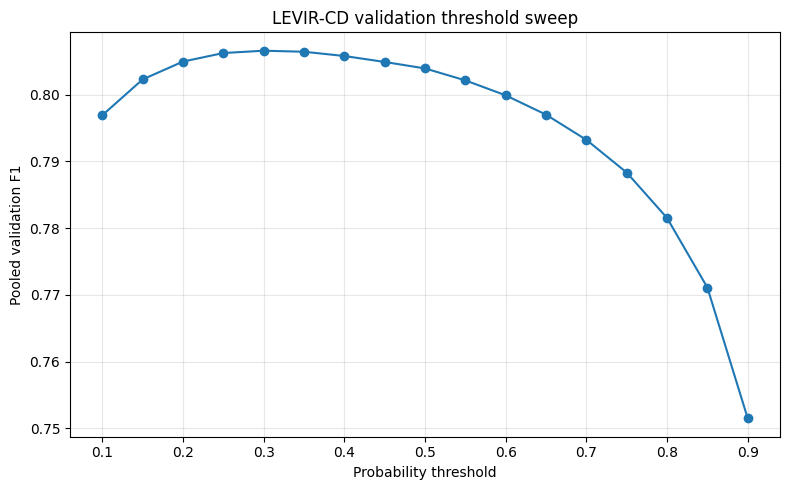


Saved threshold_sweep.csv
Saved threshold_selection_summary.json
Saved threshold_sweep_f1.png


In [11]:

import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader

OUT_DIR = Path("/kaggle/working/uncertainty_change_detection")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reuse UNet, LEVIRDataset, and val_ds from Step 9.
# If the Kaggle session was restarted, tell me before running this cell.

checkpoint_path = OUT_DIR / "levir_unet_best.pth"
assert checkpoint_path.exists(), f"Checkpoint missing: {checkpoint_path}"

checkpoint = torch.load(
    checkpoint_path, map_location=DEVICE, weights_only=False
)

model = UNet().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint epoch:", checkpoint["epoch"])
print("Saved validation F1:", checkpoint["val_f1"])

val_loader = DataLoader(
    val_ds, batch_size=8, shuffle=False,
    num_workers=2, pin_memory=(DEVICE.type == "cuda")
)

# Collect probability maps and ground truth once
all_probs = []
all_masks = []

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(DEVICE)
        probs = torch.sigmoid(model(x)).cpu().numpy()
        all_probs.append(probs)
        all_masks.append(y.numpy())

probs = np.concatenate(all_probs, axis=0).reshape(-1)
targets = np.concatenate(all_masks, axis=0).reshape(-1).astype(bool)

assert len(probs) == len(targets)
print("Validation images:", len(val_ds))
print("Total validation pixels:", len(targets))
print("Ground-truth change-pixel fraction:", round(float(targets.mean()), 6))

# Sweep thresholds using pooled pixel-level counts
thresholds = np.round(np.arange(0.10, 0.901, 0.05), 2)
rows = []

for threshold in thresholds:
    pred = probs >= threshold

    tp = int(np.logical_and(pred, targets).sum())
    fp = int(np.logical_and(pred, ~targets).sum())
    fn = int(np.logical_and(~pred, targets).sum())

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    rows.append({
        "threshold": float(threshold),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou
    })

threshold_df = pd.DataFrame(rows)
threshold_df.to_csv(OUT_DIR / "threshold_sweep.csv", index=False)

best_row = threshold_df.loc[threshold_df["f1"].idxmax()]
selected_threshold = float(best_row["threshold"])

summary = {
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "checkpoint_selection_f1_at_threshold_0.5": float(checkpoint["val_f1"]),
    "selected_threshold_by_pooled_validation_f1": selected_threshold,
    "validation_precision": float(best_row["precision"]),
    "validation_recall": float(best_row["recall"]),
    "validation_f1": float(best_row["f1"]),
    "validation_iou": float(best_row["iou"]),
    "selection_split": "LEVIR-CD validation",
    "cross_dataset_test_labels_used": False
}

(OUT_DIR / "threshold_selection_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("\nThreshold results:")
print(threshold_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nSelected operating threshold:")
print(json.dumps(summary, indent=2))

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["threshold"], threshold_df["f1"], marker="o")
plt.xlabel("Probability threshold")
plt.ylabel("Pooled validation F1")
plt.title("LEVIR-CD validation threshold sweep")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "threshold_sweep_f1.png", dpi=160)
plt.show()

print("\nSaved threshold_sweep.csv")
print("Saved threshold_selection_summary.json")
print("Saved threshold_sweep_f1.png")


Checkpoint epoch: 9
Fixed threshold: 0.35
Validation images: 96
Probability-map shape: (96, 256, 256)
Mean predictive entropy: 0.033895


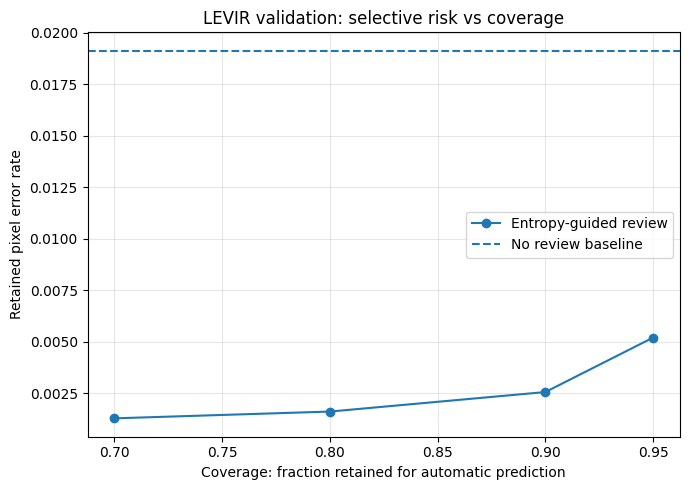


Pooled selective-review results:
 review_fraction  coverage  overall_pixel_error  reviewed_pixel_error  retained_pixel_error  relative_error_reduction
        0.050000  0.950000             0.019122              0.283588              0.005202                  0.727933
        0.100000  0.900000             0.019122              0.168166              0.002561                  0.866060
        0.200000  0.800000             0.019122              0.089151              0.001614                  0.915578
        0.300000  0.700000             0.019122              0.060740              0.001285                  0.932777

Per-image summary:
 review_fraction  mean_overall_error  mean_retained_error  median_retained_error  images_improved  image_count  fraction_images_improved
        0.050000            0.019122             0.008612               0.001919               92           96                  0.958333
        0.100000            0.019122             0.005184               0.000721  

In [12]:

import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader

# --------------------------------------------------
# Configuration
# --------------------------------------------------
OUT_DIR = Path("/kaggle/working/uncertainty_change_detection")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
THRESHOLD = 0.35
REVIEW_FRACTIONS = [0.05, 0.10, 0.20, 0.30]

checkpoint_path = OUT_DIR / "levir_unet_best.pth"
assert checkpoint_path.exists(), "Best checkpoint is missing."

checkpoint = torch.load(
    checkpoint_path, map_location=DEVICE, weights_only=False
)

# Uses the UNet and val_ds definitions from the training step.
model = UNet().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

val_loader = DataLoader(
    val_ds,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

print("Checkpoint epoch:", checkpoint["epoch"])
print("Fixed threshold:", THRESHOLD)
print("Validation images:", len(val_ds))

# --------------------------------------------------
# 1. Generate probabilities and uncertainty maps
# --------------------------------------------------
probability_batches = []
mask_batches = []

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(DEVICE)
        probabilities = torch.sigmoid(model(images)).cpu().numpy()

        probability_batches.append(probabilities[:, 0])
        mask_batches.append(masks.numpy()[:, 0])

prob_maps = np.concatenate(probability_batches, axis=0)
gt_maps = np.concatenate(mask_batches, axis=0) >= 0.5

# Numerical clipping avoids log(0).
p = np.clip(prob_maps, 1e-7, 1 - 1e-7)

# Normalized binary predictive entropy: range [0, 1].
entropy_maps = -(
    p * np.log(p) + (1 - p) * np.log(1 - p)
) / np.log(2)

pred_maps = prob_maps >= THRESHOLD
error_maps = pred_maps != gt_maps

assert prob_maps.shape == gt_maps.shape == entropy_maps.shape
print("Probability-map shape:", prob_maps.shape)
print("Mean predictive entropy:", round(float(entropy_maps.mean()), 6))

# --------------------------------------------------
# 2. Pooled selective-review analysis
# --------------------------------------------------
uncertainty = entropy_maps.reshape(-1)
errors = error_maps.reshape(-1).astype(bool)

baseline_error = float(errors.mean())
order = np.argsort(uncertainty)[::-1]

pooled_rows = []

for fraction in REVIEW_FRACTIONS:
    n_review = max(1, int(round(fraction * len(order))))
    reviewed_indices = order[:n_review]
    retained_indices = order[n_review:]

    reviewed_error = float(errors[reviewed_indices].mean())
    retained_error = (
        float(errors[retained_indices].mean())
        if len(retained_indices) else float("nan")
    )

    pooled_rows.append({
        "review_fraction": fraction,
        "coverage": 1 - fraction,
        "overall_pixel_error": baseline_error,
        "reviewed_pixel_error": reviewed_error,
        "retained_pixel_error": retained_error,
        "relative_error_reduction": (
            1 - retained_error / baseline_error
            if baseline_error > 0 else float("nan")
        )
    })

pooled_df = pd.DataFrame(pooled_rows)
pooled_df.to_csv(OUT_DIR / "selective_review_pooled.csv", index=False)

# --------------------------------------------------
# 3. Per-image analysis
# --------------------------------------------------
per_image_rows = []

for i in range(len(prob_maps)):
    image_uncertainty = entropy_maps[i].reshape(-1)
    image_errors = error_maps[i].reshape(-1).astype(bool)

    image_order = np.argsort(image_uncertainty)[::-1]
    image_baseline = float(image_errors.mean())

    for fraction in REVIEW_FRACTIONS:
        n_review = max(1, int(round(fraction * len(image_order))))
        retained = image_order[n_review:]

        retained_error = (
            float(image_errors[retained].mean())
            if len(retained) else float("nan")
        )

        per_image_rows.append({
            "image_index": i,
            "review_fraction": fraction,
            "coverage": 1 - fraction,
            "overall_error": image_baseline,
            "retained_error": retained_error
        })

per_image_df = pd.DataFrame(per_image_rows)
per_image_df.to_csv(
    OUT_DIR / "selective_review_per_image.csv", index=False
)

per_image_summary = (
    per_image_df.groupby("review_fraction")
    .agg(
        mean_overall_error=("overall_error", "mean"),
        mean_retained_error=("retained_error", "mean"),
        median_retained_error=("retained_error", "median"),
        images_improved=(
            "retained_error",
            lambda s: int(
                (s.to_numpy() <
                 per_image_df.loc[s.index, "overall_error"].to_numpy()).sum()
            )
        ),
        image_count=("image_index", "nunique")
    )
    .reset_index()
)

per_image_summary["fraction_images_improved"] = (
    per_image_summary["images_improved"] /
    per_image_summary["image_count"]
)

per_image_summary.to_csv(
    OUT_DIR / "selective_review_per_image_summary.csv",
    index=False
)

# --------------------------------------------------
# 4. Save reusable arrays and experiment summary
# --------------------------------------------------
np.savez_compressed(
    OUT_DIR / "lev​​ir_validation_uncertainty_arrays.npz".replace("\u200b", ""),
    probabilities=prob_maps.astype(np.float32),
    ground_truth=gt_maps.astype(np.uint8),
    entropy=entropy_maps.astype(np.float32),
    predictions=pred_maps.astype(np.uint8)
)

summary = {
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "operating_threshold": THRESHOLD,
    "validation_images": int(len(prob_maps)),
    "image_size": list(prob_maps.shape[1:]),
    "pooled_pixel_error": baseline_error,
    "mean_entropy": float(entropy_maps.mean()),
    "interpretation": (
        "Entropy-based selective-review analysis on LEVIR validation; "
        "not evidence of cross-dataset performance or calibrated uncertainty."
    )
}

(OUT_DIR / "uncertainty_analysis_summary.json").write_text(
    json.dumps(summary, indent=2)
)

# --------------------------------------------------
# 5. Plot and display results
# --------------------------------------------------
plt.figure(figsize=(7, 5))
plt.plot(
    pooled_df["coverage"],
    pooled_df["retained_pixel_error"],
    marker="o",
    label="Entropy-guided review"
)
plt.axhline(
    baseline_error,
    linestyle="--",
    label="No review baseline"
)
plt.xlabel("Coverage: fraction retained for automatic prediction")
plt.ylabel("Retained pixel error rate")
plt.title("LEVIR validation: selective risk vs coverage")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "selective_risk_coverage.png", dpi=160)
plt.show()

print("\nPooled selective-review results:")
print(pooled_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

print("\nPer-image summary:")
print(per_image_summary.to_string(
    index=False, float_format=lambda x: f"{x:.6f}"
))

print("\nSaved outputs in:", OUT_DIR)
for filename in [
    "selective_review_pooled.csv",
    "selective_review_per_image.csv",
    "selective_review_per_image_summary.csv",
    "uncertainty_analysis_summary.json",
    "selective_risk_coverage.png"
]:
    path = OUT_DIR / filename
    print(filename, "->", path.exists())

print("\nSTEP 11 COMPLETE")


In [13]:

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# 1. Fixed experiment configuration
# --------------------------------------------------
OUT_DIR = Path("/kaggle/working/uncertainty_change_detection")
S2_ROOT = Path(
    "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"
)
CHECKPOINT_PATH = OUT_DIR / "levir_unet_best.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 256

# Fixed using LEVIR validation only. Do not change on S2Looking.
THRESHOLD = 0.35
REVIEW_FRACTIONS = [0.05, 0.10, 0.20, 0.30]

assert CHECKPOINT_PATH.exists(), "Checkpoint not found."
assert (S2_ROOT / "test" / "Image1").exists(), "S2Looking test folder not found."

# --------------------------------------------------
# 2. Load S2Looking test data
# --------------------------------------------------
class S2LookingTestDataset(Dataset):
    def __init__(self, root, image_size=256):
        self.root = Path(root)
        self.image_size = image_size

        self.image_dir1 = self.root / "Image1"
        self.image_dir2 = self.root / "Image2"
        self.mask_dir = self.root / "label"

        names1 = {p.name for p in self.image_dir1.glob("*.png")}
        names2 = {p.name for p in self.image_dir2.glob("*.png")}
        names_mask = {p.name for p in self.mask_dir.glob("*.png")}

        assert names1 == names2 == names_mask, (
            "Image/mask filenames do not match."
        )

        self.names = sorted(names1, key=lambda x: int(Path(x).stem))

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]

        with Image.open(self.image_dir1 / name) as im:
            before = im.convert("RGB").resize(
                (self.image_size, self.image_size),
                Image.Resampling.BILINEAR
            )

        with Image.open(self.image_dir2 / name) as im:
            after = im.convert("RGB").resize(
                (self.image_size, self.image_size),
                Image.Resampling.BILINEAR
            )

        with Image.open(self.mask_dir / name) as im:
            mask = im.convert("L").resize(
                (self.image_size, self.image_size),
                Image.Resampling.NEAREST
            )

        before = np.asarray(before, dtype=np.float32) / 255.0
        after = np.asarray(after, dtype=np.float32) / 255.0
        mask = (np.asarray(mask) > 0).astype(np.uint8)

        image = np.concatenate([before, after], axis=2)
        image = torch.from_numpy(image.transpose(2, 0, 1).copy())
        mask = torch.from_numpy(mask.copy())

        return image, mask, name

test_ds = S2LookingTestDataset(
    S2_ROOT / "test",
    image_size=IMAGE_SIZE
)

test_loader = DataLoader(
    test_ds,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

print("Device:", DEVICE)
print("S2Looking test pairs:", len(test_ds))
print("Input size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Fixed threshold:", THRESHOLD)

# --------------------------------------------------
# 3. Load the exact LEVIR-trained checkpoint
# --------------------------------------------------
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model = UNet().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint epoch:", checkpoint["epoch"])
print("Saved LEVIR validation F1:", checkpoint["val_f1"])

# --------------------------------------------------
# 4. Evaluate without tuning on S2Looking
# --------------------------------------------------
start_time = time.time()

all_probabilities = []
all_masks = []
per_image_rows = []

with torch.no_grad():
    for batch_number, (images, masks, names) in enumerate(test_loader, 1):
        images = images.to(DEVICE)
        logits = model(images)
        probs = torch.sigmoid(logits).cpu().numpy()[:, 0]
        gt = masks.numpy() >= 1

        for i, name in enumerate(names):
            pred = probs[i] >= THRESHOLD
            target = gt[i]

            tp = int(np.logical_and(pred, target).sum())
            fp = int(np.logical_and(pred, ~target).sum())
            fn = int(np.logical_and(~pred, target).sum())

            precision = tp / (tp + fp) if tp + fp else 0.0
            recall = tp / (tp + fn) if tp + fn else 0.0
            f1 = (
                2 * precision * recall / (precision + recall)
                if precision + recall else 0.0
            )
            iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

            per_image_rows.append({
                "filename": name,
                "precision": precision,
                "recall": recall,
                "f1": f1,
                "iou": iou,
                "gt_change_fraction": float(target.mean()),
                "pred_change_fraction": float(pred.mean()),
                "pixel_error": float(np.mean(pred != target))
            })

        # Store compact arrays to limit memory usage.
        all_probabilities.append(probs.astype(np.float16))
        all_masks.append(gt.astype(np.uint8))

        if batch_number % 25 == 0:
            print(
                f"Processed {min(batch_number * 8, len(test_ds))}"
                f"/{len(test_ds)} image pairs"
            )

prob_maps = np.concatenate(all_probabilities, axis=0)
gt_maps = np.concatenate(all_masks, axis=0).astype(bool)

del all_probabilities, all_masks

# --------------------------------------------------
# 5. Pooled change-detection metrics
# --------------------------------------------------
pred_maps = prob_maps >= THRESHOLD

tp = int(np.logical_and(pred_maps, gt_maps).sum())
fp = int(np.logical_and(pred_maps, ~gt_maps).sum())
fn = int(np.logical_and(~pred_maps, gt_maps).sum())

precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)
iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

per_image_df = pd.DataFrame(per_image_rows)
per_image_df.to_csv(OUT_DIR / "s2looking_test_per_image.csv", index=False)

# --------------------------------------------------
# 6. Entropy and selective review
# --------------------------------------------------
p = np.clip(prob_maps.astype(np.float32), 1e-7, 1 - 1e-7)

entropy_maps = -(
    p * np.log(p) + (1 - p) * np.log(1 - p)
) / np.log(2)

error_maps = pred_maps != gt_maps

uncertainty = entropy_maps.reshape(-1)
errors = error_maps.reshape(-1).astype(bool)

baseline_error = float(errors.mean())
review_rows = []

# Exact top-k review per budget. Argpartition avoids a full sort.
for fraction in REVIEW_FRACTIONS:
    n_review = int(round(fraction * len(uncertainty)))
    n_review = max(1, min(n_review, len(uncertainty) - 1))

    top_indices = np.argpartition(
        uncertainty, len(uncertainty) - n_review
    )[-n_review:]

    review_mask = np.zeros(len(uncertainty), dtype=bool)
    review_mask[top_indices] = True

    reviewed_error = float(errors[review_mask].mean())
    retained_error = float(errors[~review_mask].mean())

    review_rows.append({
        "review_fraction": fraction,
        "coverage": 1 - fraction,
        "overall_pixel_error": baseline_error,
        "reviewed_pixel_error": reviewed_error,
        "retained_pixel_error": retained_error,
        "relative_error_reduction": (
            1 - retained_error / baseline_error
            if baseline_error > 0 else float("nan")
        )
    })

review_df = pd.DataFrame(review_rows)
review_df.to_csv(OUT_DIR / "s2looking_selective_review.csv", index=False)

# --------------------------------------------------
# 7. Save arrays and experiment summary
# --------------------------------------------------
np.savez_compressed(
    OUT_DIR / "s2looking_test_arrays.npz",
    probabilities=prob_maps,
    ground_truth=gt_maps.astype(np.uint8),
    entropy=entropy_maps.astype(np.float16),
    predictions=pred_maps.astype(np.uint8)
)

summary = {
    "dataset": "S2Looking test",
    "test_pairs": len(test_ds),
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "operating_threshold": THRESHOLD,
    "threshold_selected_on": "LEVIR-CD validation",
    "s2looking_test_labels_used_for_tuning": False,
    "pooled_precision": precision,
    "pooled_recall": recall,
    "pooled_f1": f1,
    "pooled_iou": iou,
    "pooled_pixel_error": baseline_error,
    "mean_entropy": float(entropy_maps.mean()),
    "mean_per_image_f1": float(per_image_df["f1"].mean()),
    "median_per_image_f1": float(per_image_df["f1"].median()),
    "mean_per_image_iou": float(per_image_df["iou"].mean()),
    "elapsed_seconds": time.time() - start_time
}

(OUT_DIR / "s2looking_test_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("\n" + "=" * 65)
print("STEP 12: CROSS-DATASET RESULTS")
print("=" * 65)
print(json.dumps(summary, indent=2))

print("\nSelective-review results:")
print(review_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

print("\nPer-image F1 distribution:")
print(per_image_df["f1"].describe().to_string())

print("\nSaved outputs:")
for filename in [
    "s2looking_test_summary.json",
    "s2looking_test_per_image.csv",
    "s2looking_selective_review.csv",
    "s2looking_test_arrays.npz"
]:
    path = OUT_DIR / filename
    print(filename, "exists:", path.exists(),
          "size MB:", round(path.stat().st_size / 1e6, 2)
          if path.exists() else "N/A")

print("\nSTEP 12 COMPLETE")


Device: cuda
S2Looking test pairs: 1000
Input size: 256 x 256
Fixed threshold: 0.35
Checkpoint epoch: 9
Saved LEVIR validation F1: 0.8039417332081568
Processed 200/1000 image pairs
Processed 400/1000 image pairs
Processed 600/1000 image pairs
Processed 800/1000 image pairs
Processed 1000/1000 image pairs

STEP 12: CROSS-DATASET RESULTS
{
  "dataset": "S2Looking test",
  "test_pairs": 1000,
  "checkpoint_epoch": 9,
  "operating_threshold": 0.35,
  "threshold_selected_on": "LEVIR-CD validation",
  "s2looking_test_labels_used_for_tuning": false,
  "pooled_precision": 0.10487579235908857,
  "pooled_recall": 0.019293390904220113,
  "pooled_f1": 0.032591172869083744,
  "pooled_iou": 0.016565531484684676,
  "pooled_pixel_error": 0.013863250732421875,
  "mean_entropy": 0.015158387909666326,
  "mean_per_image_f1": 0.022660968146629094,
  "median_per_image_f1": 0.0,
  "mean_per_image_iou": 0.01367243264456101,
  "elapsed_seconds": 75.95642280578613
}

Selective-review results:
 review_fraction  

STEP 13A: VERIFY CURRENT CHECKPOINT ON LEVIR VALIDATION
Checkpoint metadata epoch: 9
Checkpoint metadata F1: 0.8039417332081568
 threshold  precision   recall       f1      iou  gt_change_fraction  pred_change_fraction
      0.35   0.806152 0.806731 0.806441 0.675661            0.049377              0.049413
      0.50   0.829290 0.780097 0.803942 0.672159            0.049377              0.046448

STEP 13B: COMPARE S2LOOKING PROBABILITIES AND LABELS

LEVIR validation probabilities
  min: 1.4628218991674657e-07
  max: 0.9999942779541016
  mean: 0.046926289796829224
  quantiles [0, 25, 50, 75, 90, 99, 100]%:
[0.00000e+00 3.36000e-04 5.51000e-04 9.93000e-04 3.26900e-03 9.96135e-01
 9.99994e-01]

S2Looking test probabilities
  min: 1.9609928131103516e-05
  max: 1.0
  mean: 0.003120505716651678
  quantiles [0, 25, 50, 75, 90, 99, 100]%:
[2.000e-05 5.720e-04 7.580e-04 1.225e-03 2.073e-03 1.210e-02 1.000e+00]

S2Looking ground-truth change fraction: 0.012103652954101563
S2Looking predicted c

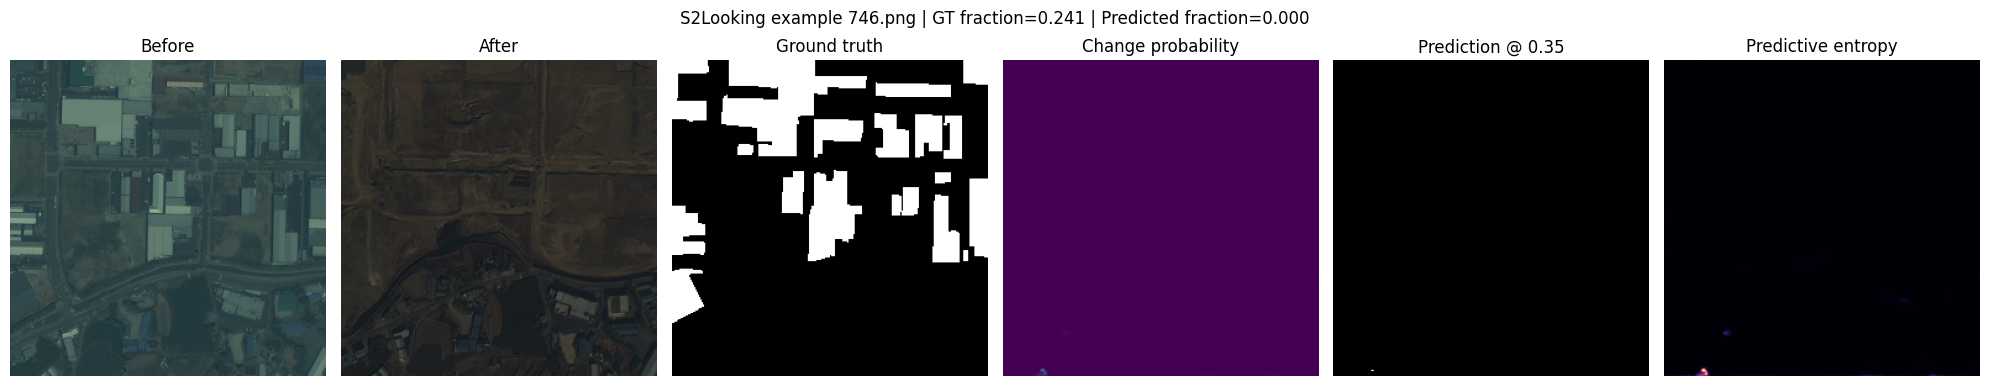

Diagnostic image saved.

STEP 13 COMPLETE


In [14]:

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR = Path("/kaggle/working/uncertainty_change_detection")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 65)
print("STEP 13A: VERIFY CURRENT CHECKPOINT ON LEVIR VALIDATION")
print("=" * 65)

# Reuse model, val_ds, and checkpoint from earlier steps.
model.eval()
val_loader_diag = DataLoader(
    val_ds, batch_size=8, shuffle=False, num_workers=2
)

val_probs_list = []
val_masks_list = []

with torch.no_grad():
    for x, y in val_loader_diag:
        p = torch.sigmoid(model(x.to(DEVICE))).cpu().numpy()[:, 0]
        val_probs_list.append(p)
        val_masks_list.append(y.numpy()[:, 0])

vp = np.concatenate(val_probs_list, axis=0)
vy = np.concatenate(val_masks_list, axis=0) >= 0.5

def binary_metrics(probabilities, targets, threshold):
    pred = probabilities >= threshold
    tp = np.logical_and(pred, targets).sum()
    fp = np.logical_and(pred, ~targets).sum()
    fn = np.logical_and(~pred, targets).sum()

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    return {
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "gt_change_fraction": float(targets.mean()),
        "pred_change_fraction": float(pred.mean())
    }

val_rows = [
    binary_metrics(vp, vy, t) for t in [0.35, 0.50]
]
print("Checkpoint metadata epoch:", checkpoint["epoch"])
print("Checkpoint metadata F1:", checkpoint.get("val_f1"))
print(pd.DataFrame(val_rows).to_string(index=False))

print("\n" + "=" * 65)
print("STEP 13B: COMPARE S2LOOKING PROBABILITIES AND LABELS")
print("=" * 65)

# Use the arrays generated by Step 12.
sp = prob_maps.astype(np.float32)
sy = gt_maps.astype(bool)
spred = sp >= 0.35

for name, arr in [
    ("LEVIR validation probabilities", vp),
    ("S2Looking test probabilities", sp)
]:
    print(f"\n{name}")
    print("  min:", float(arr.min()))
    print("  max:", float(arr.max()))
    print("  mean:", float(arr.mean()))
    print("  quantiles [0, 25, 50, 75, 90, 99, 100]%:")
    print(np.percentile(arr, [0, 25, 50, 75, 90, 99, 100]).round(6))

print("\nS2Looking ground-truth change fraction:", float(sy.mean()))
print("S2Looking predicted change fraction:", float(spred.mean()))
print("S2Looking mean GT change fraction per image:",
      float(sy.mean(axis=(1, 2)).mean()))
print("S2Looking mean predicted fraction per image:",
      float(spred.mean(axis=(1, 2)).mean()))

print("\n" + "=" * 65)
print("STEP 13C: VISUALIZE A HIGH-CHANGE S2LOOKING EXAMPLE")
print("=" * 65)

# Choose an example with substantial ground-truth change,
# to make it easier to inspect whether the model detects it.
gt_fractions = sy.mean(axis=(1, 2))
sample_idx = int(np.argmax(gt_fractions))
image_tensor, mask_tensor, sample_name = test_ds[sample_idx]

with torch.no_grad():
    sample_prob = torch.sigmoid(
        model(image_tensor.unsqueeze(0).to(DEVICE))
    )[0, 0].cpu().numpy()

sample_pred = sample_prob >= 0.35
sample_gt = mask_tensor.numpy().astype(bool)

pclip = np.clip(sample_prob, 1e-7, 1 - 1e-7)
sample_entropy = -(
    pclip * np.log(pclip) + (1 - pclip) * np.log(1 - pclip)
) / np.log(2)

# Recover RGB views for display.
before_path = S2_ROOT / "test" / "Image1" / sample_name
after_path = S2_ROOT / "test" / "Image2" / sample_name

from PIL import Image
with Image.open(before_path) as im:
    before_view = im.convert("RGB").resize((256, 256))
with Image.open(after_path) as im:
    after_view = im.convert("RGB").resize((256, 256))

fig, axes = plt.subplots(1, 6, figsize=(20, 4))

axes[0].imshow(before_view)
axes[0].set_title("Before")

axes[1].imshow(after_view)
axes[1].set_title("After")

axes[2].imshow(sample_gt, cmap="gray")
axes[2].set_title("Ground truth")

axes[3].imshow(sample_prob, cmap="viridis", vmin=0, vmax=1)
axes[3].set_title("Change probability")

axes[4].imshow(sample_pred, cmap="gray")
axes[4].set_title("Prediction @ 0.35")

axes[5].imshow(sample_entropy, cmap="magma", vmin=0, vmax=1)
axes[5].set_title("Predictive entropy")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"S2Looking example {sample_name} | "
    f"GT fraction={sample_gt.mean():.3f} | "
    f"Predicted fraction={sample_pred.mean():.3f}"
)
plt.tight_layout()
plt.savefig(OUT_DIR / "s2looking_diagnostic_example.png", dpi=160)
plt.show()

print("Diagnostic image saved.")
print("\nSTEP 13 COMPLETE")


STEP 14: IMAGE DISTRIBUTION COMPARISON

Summary statistics:
                      before_mean                   after_mean                   before_std                   after_std                   before_r_mean                   before_g_mean                   before_b_mean                   after_r_mean                   after_g_mean                   after_b_mean                   mean_absolute_before_after_difference                  
                             mean      std   median       mean      std   median       mean      std   median      mean      std   median          mean      std   median          mean      std   median          mean      std   median         mean      std   median         mean      std   median         mean      std   median                                  mean      std   median
dataset                                                                                                                                                                       

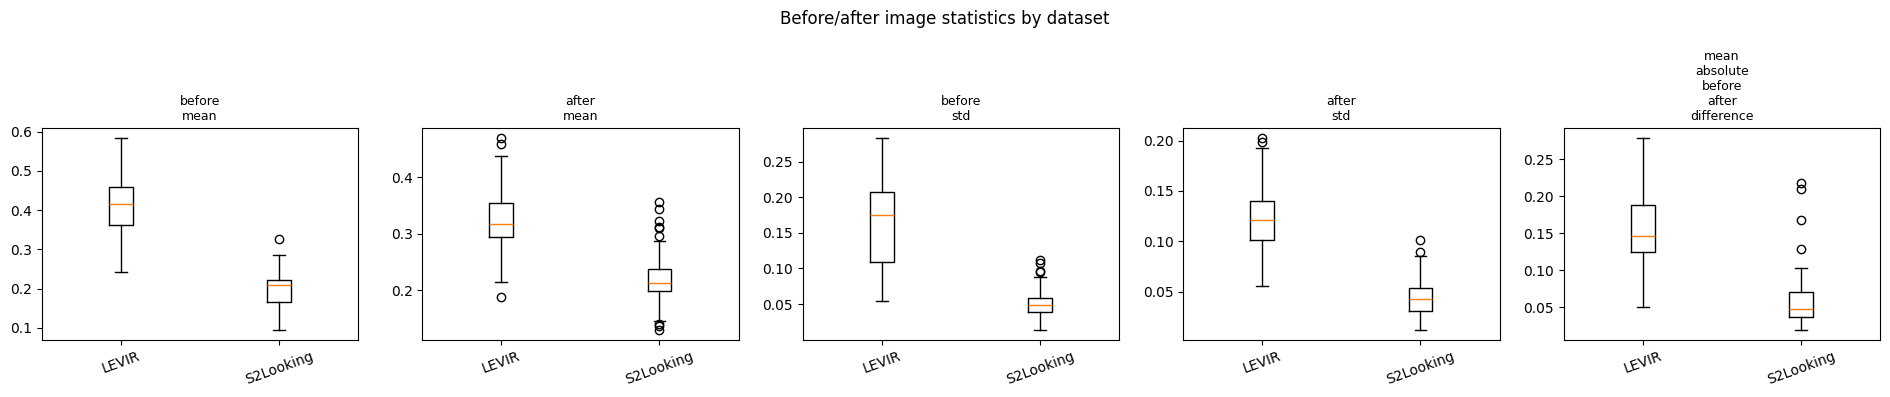


STEP 14 COMPLETE
Paste the summary statistics here.


In [15]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = Path("/kaggle/working/uncertainty_change_detection")
IMAGE_SIZE = 256
S2_ROOT = Path(
    "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"
)

def load_rgb_float(path):
    with Image.open(path) as im:
        im = im.convert("RGB").resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )
        return np.asarray(im, dtype=np.float32) / 255.0

def image_pair_stats(name, before_path, after_path, dataset):
    before = load_rgb_float(before_path)
    after = load_rgb_float(after_path)

    row = {
        "dataset": dataset,
        "filename": name,
        "before_mean": float(before.mean()),
        "after_mean": float(after.mean()),
        "before_std": float(before.std()),
        "after_std": float(after.std()),
        "before_r_mean": float(before[:, :, 0].mean()),
        "before_g_mean": float(before[:, :, 1].mean()),
        "before_b_mean": float(before[:, :, 2].mean()),
        "after_r_mean": float(after[:, :, 0].mean()),
        "after_g_mean": float(after[:, :, 1].mean()),
        "after_b_mean": float(after[:, :, 2].mean()),
        "mean_absolute_before_after_difference": float(
            np.abs(before - after).mean()
        )
    }
    return row

print("=" * 65)
print("STEP 14: IMAGE DISTRIBUTION COMPARISON")
print("=" * 65)

rows = []

# Use the complete source validation split.
for _, row in val_df.iterrows():
    rows.append(
        image_pair_stats(
            row["filename"],
            row["image_before"],
            row["image_after"],
            "LEVIR_validation"
        )
    )

# Use a deterministic sample of 100 S2Looking test image pairs.
# This is descriptive analysis only; no labels are accessed.
s2_image_dir = S2_ROOT / "test" / "Image1"
s2_names = sorted(
    [p.name for p in s2_image_dir.glob("*.png")],
    key=lambda x: int(Path(x).stem)
)

sample_indices = np.linspace(
    0, len(s2_names) - 1, min(100, len(s2_names)), dtype=int
)
s2_sample_names = [s2_names[i] for i in sample_indices]

for name in s2_sample_names:
    rows.append(
        image_pair_stats(
            name,
            S2_ROOT / "test" / "Image1" / name,
            S2_ROOT / "test" / "Image2" / name,
            "S2Looking_test_sample"
        )
    )

stats_df = pd.DataFrame(rows)
stats_path = OUT_DIR / "image_distribution_comparison.csv"
stats_df.to_csv(stats_path, index=False)

numeric_columns = [
    c for c in stats_df.columns
    if c not in ["dataset", "filename"]
]

summary = stats_df.groupby("dataset")[numeric_columns].agg(
    ["mean", "std", "median"]
)

print("\nSummary statistics:")
print(summary.round(5).to_string())

print("\nSaved:", stats_path)

# Visualize selected image-level features.
features = [
    "before_mean",
    "after_mean",
    "before_std",
    "after_std",
    "mean_absolute_before_after_difference"
]

fig, axes = plt.subplots(1, len(features), figsize=(19, 4))

for ax, feature in zip(axes, features):
    values = [
        stats_df.loc[
            stats_df["dataset"] == dataset, feature
        ].values
        for dataset in ["LEVIR_validation", "S2Looking_test_sample"]
    ]
    ax.boxplot(values, tick_labels=["LEVIR", "S2Looking"])
    ax.set_title(feature.replace("_", "\n"), fontsize=9)
    ax.tick_params(axis="x", rotation=20)

plt.suptitle("Before/after image statistics by dataset")
plt.tight_layout()
plt.savefig(OUT_DIR / "image_distribution_comparison.png", dpi=160)
plt.show()

print("\nSTEP 14 COMPLETE")
print("Paste the summary statistics here.")


STEP 15: ENTROPY REVIEW VS RANDOM REVIEW

Overall S2Looking pixel error: 0.013863

Comparison table:
        method  review_fraction  coverage  overall_error  reviewed_error  retained_error  relative_error_reduction  random_reviewed_error_mean  random_reviewed_error_std  random_retained_error_mean  random_retained_error_std  random_error_reduction_mean  random_error_reduction_std  retained_error_advantage_vs_random
Entropy-guided         0.050000  0.950000       0.013863        0.058132        0.011533                  0.168066                    0.013890                   0.000048                    0.013862                   0.000003                     0.000101                    0.000180                            0.002329
Entropy-guided         0.100000  0.900000       0.013863        0.034330        0.011589                  0.164039                    0.013882                   0.000032                    0.013861                   0.000004                     0.000149          

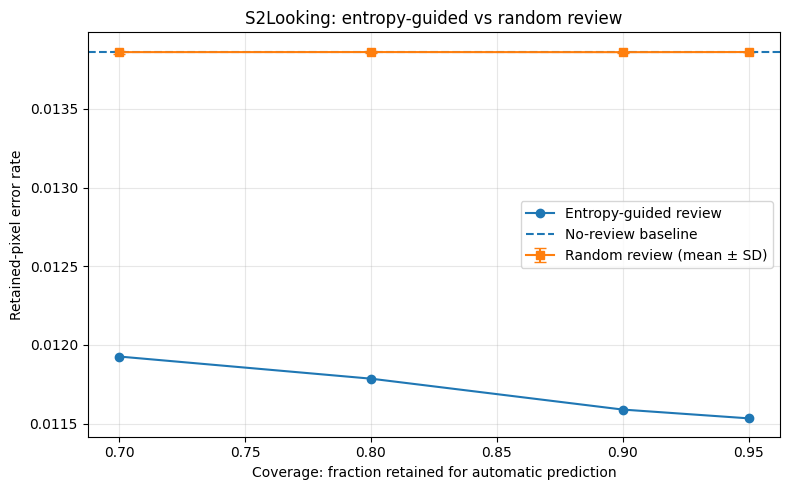


Saved:
s2_entropy_review_baseline.csv -> True
s2_random_review_runs.csv -> True
s2_entropy_vs_random_comparison.csv -> True
s2_uncertainty_distribution_summary.json -> True
s2_entropy_vs_random_review.png -> True

STEP 15 COMPLETE


In [16]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR = Path("/kaggle/working/uncertainty_change_detection")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the existing Step 12/13 arrays and fixed threshold.
# prob_maps: S2Looking probabilities, shape (1000, 256, 256)
# gt_maps: S2Looking ground-truth binary masks
# entropy_maps: binary predictive entropy maps
THRESHOLD = 0.35
REVIEW_FRACTIONS = [0.05, 0.10, 0.20, 0.30]
RANDOM_SEEDS = range(20)

pred_maps = prob_maps >= THRESHOLD
errors = (pred_maps != gt_maps).reshape(-1).astype(bool)
uncertainty = entropy_maps.reshape(-1)

assert len(errors) == len(uncertainty)
n_pixels = len(errors)
baseline_error = float(errors.mean())

# Entropy-guided ranking
n_review_rows = []
entropy_order = np.argsort(uncertainty)[::-1]

for fraction in REVIEW_FRACTIONS:
    n_review = max(1, int(round(fraction * n_pixels)))
    reviewed = entropy_order[:n_review]
    retained = entropy_order[n_review:]

    n_review_rows.append({
        "method": "Entropy-guided",
        "review_fraction": fraction,
        "coverage": 1 - fraction,
        "overall_error": baseline_error,
        "reviewed_error": float(errors[reviewed].mean()),
        "retained_error": float(errors[retained].mean()),
        "relative_error_reduction": (
            1 - float(errors[retained].mean()) / baseline_error
            if baseline_error > 0 else np.nan
        )
    })

entropy_df = pd.DataFrame(n_review_rows)

# Random-review baseline, repeated with 20 seeds
random_rows = []

for fraction in REVIEW_FRACTIONS:
    n_review = max(1, int(round(fraction * n_pixels)))

    for seed in RANDOM_SEEDS:
        rng = np.random.default_rng(seed)
        order = rng.permutation(n_pixels)

        reviewed = order[:n_review]
        retained = order[n_review:]

        reviewed_error = float(errors[reviewed].mean())
        retained_error = float(errors[retained].mean())

        random_rows.append({
            "method": "Random",
            "seed": seed,
            "review_fraction": fraction,
            "coverage": 1 - fraction,
            "overall_error": baseline_error,
            "reviewed_error": reviewed_error,
            "retained_error": retained_error,
            "relative_error_reduction": (
                1 - retained_error / baseline_error
                if baseline_error > 0 else np.nan
            )
        })

random_df = pd.DataFrame(random_rows)

# Summarize random baseline across seeds
random_summary = (
    random_df.groupby("review_fraction")
    .agg(
        random_reviewed_error_mean=("reviewed_error", "mean"),
        random_reviewed_error_std=("reviewed_error", "std"),
        random_retained_error_mean=("retained_error", "mean"),
        random_retained_error_std=("retained_error", "std"),
        random_error_reduction_mean=("relative_error_reduction", "mean"),
        random_error_reduction_std=("relative_error_reduction", "std")
    )
    .reset_index()
)

comparison = entropy_df.merge(random_summary, on="review_fraction")
comparison["retained_error_advantage_vs_random"] = (
    comparison["random_retained_error_mean"]
    - comparison["retained_error"]
)

entropy_df.to_csv(OUT_DIR / "s2_entropy_review_baseline.csv", index=False)
random_df.to_csv(OUT_DIR / "s2_random_review_runs.csv", index=False)
comparison.to_csv(OUT_DIR / "s2_entropy_vs_random_comparison.csv", index=False)

# Save a summary of the uncertainty distribution
uncertainty_summary = {
    "dataset": "S2Looking test",
    "threshold": THRESHOLD,
    "overall_pixel_error": baseline_error,
    "mean_entropy": float(uncertainty.mean()),
    "median_entropy": float(np.median(uncertainty)),
    "entropy_quantiles": {
        str(q): float(np.quantile(uncertainty, q))
        for q in [0, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0]
    },
    "random_review_seeds": len(list(RANDOM_SEEDS)),
    "note": (
        "Test-set results are for evaluation only. "
        "Do not use them to tune the operating threshold."
    )
}
(OUT_DIR / "s2_uncertainty_distribution_summary.json").write_text(
    json.dumps(uncertainty_summary, indent=2)
)

print("=" * 65)
print("STEP 15: ENTROPY REVIEW VS RANDOM REVIEW")
print("=" * 65)
print("\nOverall S2Looking pixel error:", round(baseline_error, 6))
print("\nComparison table:")
print(comparison.to_string(
    index=False, float_format=lambda x: f"{x:.6f}"
))

# Plot retained-pixel error against coverage
plt.figure(figsize=(8, 5))
plt.plot(
    comparison["coverage"],
    comparison["retained_error"],
    marker="o",
    label="Entropy-guided review"
)
plt.errorbar(
    comparison["coverage"],
    comparison["random_retained_error_mean"],
    yerr=comparison["random_retained_error_std"],
    marker="s",
    capsize=4,
    label="Random review (mean ± SD)"
)
plt.axhline(
    baseline_error, linestyle="--", label="No-review baseline"
)
plt.xlabel("Coverage: fraction retained for automatic prediction")
plt.ylabel("Retained-pixel error rate")
plt.title("S2Looking: entropy-guided vs random review")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "s2_entropy_vs_random_review.png", dpi=160)
plt.show()

print("\nSaved:")
for filename in [
    "s2_entropy_review_baseline.csv",
    "s2_random_review_runs.csv",
    "s2_entropy_vs_random_comparison.csv",
    "s2_uncertainty_distribution_summary.json",
    "s2_entropy_vs_random_review.png"
]:
    path = OUT_DIR / filename
    print(filename, "->", path.exists())

print("\nSTEP 15 COMPLETE")


In [17]:
import os
import json
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

print("=" * 65)
print("STEP 16: EXPERIMENT ARTIFACT AND REPRODUCIBILITY CHECK")
print("=" * 65)

files_to_check = [
    "levir_unet_best.pth",
    "training_history.csv",
    "training_config.json",
    "training_summary.json",
    "threshold_sweep.csv",
    "threshold_selection_summary.json",
    "s2looking_test_summary.json",
    "s2_entropy_vs_random_comparison.csv",
    "s2_random_review_runs.csv",
]

for name in files_to_check:
    path = os.path.join(OUT_DIR, name)
    print(f"{name}: {'EXISTS' if os.path.exists(path) else 'MISSING'}")

for name in [
    "training_summary.json",
    "threshold_selection_summary.json",
    "s2looking_test_summary.json",
]:
    path = os.path.join(OUT_DIR, name)
    if os.path.exists(path):
        print(f"\n--- {name} ---")
        with open(path, "r") as f:
            print(json.dumps(json.load(f), indent=2))

history_path = os.path.join(OUT_DIR, "training_history.csv")
if os.path.exists(history_path):
    print("\n--- Training history (last 5 rows) ---")
    print(pd.read_csv(history_path).tail().to_string(index=False))

sweep_path = os.path.join(OUT_DIR, "threshold_sweep.csv")
if os.path.exists(sweep_path):
    print("\n--- Threshold sweep ---")
    print(pd.read_csv(sweep_path).to_string(index=False))

STEP 16: EXPERIMENT ARTIFACT AND REPRODUCIBILITY CHECK
levir_unet_best.pth: EXISTS
training_history.csv: EXISTS
training_config.json: EXISTS
training_summary.json: EXISTS
threshold_sweep.csv: EXISTS
threshold_selection_summary.json: EXISTS
s2looking_test_summary.json: EXISTS
s2_entropy_vs_random_comparison.csv: EXISTS
s2_random_review_runs.csv: EXISTS

--- training_summary.json ---
{
  "best_validation_f1_at_threshold_0.5": 0.8039417332081568,
  "training_seconds": 344.16950368881226,
  "checkpoint": "/kaggle/working/uncertainty_change_detection/levir_unet_best.pth",
  "history_csv": "/kaggle/working/uncertainty_change_detection/training_history.csv"
}

--- threshold_selection_summary.json ---
{
  "checkpoint_epoch": 9,
  "checkpoint_selection_f1_at_threshold_0.5": 0.8039417332081568,
  "selected_threshold_by_pooled_validation_f1": 0.3,
  "validation_precision": 0.7976543835517267,
  "validation_recall": 0.8157409344771531,
  "validation_f1": 0.806596281713811,
  "validation_iou": 0.67

In [18]:

import os
import json
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
ARRAY_PATH = os.path.join(OUT_DIR, "s2looking_test_arrays.npz")

print("=" * 65)
print("STEP 17: THRESHOLD CONSISTENCY CHECK")
print("=" * 65)

if not os.path.exists(ARRAY_PATH):
    print("ERROR: Prediction array file not found:", ARRAY_PATH)
    print("Please paste the filenames in the output directory.")
else:
    data = np.load(ARRAY_PATH)
    print("Saved array keys:", data.files)

    for key in data.files:
        arr = data[key]
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

    print("\nNo metrics recalculated yet.")
    print("We need to identify the probability and ground-truth array keys first.")


STEP 17: THRESHOLD CONSISTENCY CHECK
Saved array keys: ['probabilities', 'ground_truth', 'entropy', 'predictions']
probabilities: shape=(1000, 256, 256), dtype=float16
ground_truth: shape=(1000, 256, 256), dtype=uint8
entropy: shape=(1000, 256, 256), dtype=float16
predictions: shape=(1000, 256, 256), dtype=uint8

No metrics recalculated yet.
We need to identify the probability and ground-truth array keys first.


In [19]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
ARRAY_PATH = os.path.join(OUT_DIR, "s2looking_test_arrays.npz")

data = np.load(ARRAY_PATH)
probabilities = data["probabilities"].astype(np.float32)
ground_truth = data["ground_truth"].astype(bool)

print("=" * 65)
print("STEP 18: S2LOOKING THRESHOLD COMPARISON")
print("=" * 65)

results = []

for threshold in [0.35, 0.40, 0.50]:
    predictions = probabilities >= threshold

    tp = np.logical_and(predictions, ground_truth).sum()
    fp = np.logical_and(predictions, ~ground_truth).sum()
    fn = np.logical_and(~predictions, ground_truth).sum()
    errors = np.not_equal(predictions, ground_truth).sum()
    total = ground_truth.size

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "pixel_error": errors / total,
        "predicted_change_fraction": predictions.mean(),
        "ground_truth_change_fraction": ground_truth.mean()
    })

results_df = pd.DataFrame(results)
print(results_df.round(6).to_string(index=False))

save_path = os.path.join(
    OUT_DIR, "s2looking_threshold_comparison.csv"
)
results_df.to_csv(save_path, index=False)
print("\nSaved:", save_path)


STEP 18: S2LOOKING THRESHOLD COMPARISON
 threshold  precision   recall       f1      iou  pixel_error  predicted_change_fraction  ground_truth_change_fraction
      0.35   0.104876 0.019293 0.032591 0.016566     0.013863                   0.002227                      0.012104
      0.40   0.105897 0.018615 0.031664 0.016087     0.013781                   0.002128                      0.012104
      0.50   0.108086 0.017329 0.029870 0.015161     0.013625                   0.001941                      0.012104

Saved: /kaggle/working/uncertainty_change_detection/s2looking_threshold_comparison.csv


In [20]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
data = np.load(os.path.join(OUT_DIR, "s2looking_test_arrays.npz"))

prob = data["probabilities"].astype(np.float32)
gt = data["ground_truth"].astype(np.uint8)
entropy = data["entropy"].astype(np.float32)

# Use the original saved operating threshold for this diagnostic.
threshold = 0.35
pred = (prob >= threshold).astype(np.uint8)
error = (pred != gt).astype(np.uint8)

# Flatten all pixels. Sample deterministically to limit memory use.
rng = np.random.default_rng(42)
max_pixels = 2_000_000
total = error.size
indices = rng.choice(total, size=min(max_pixels, total), replace=False)

y_error = error.reshape(-1)[indices]
y_entropy = entropy.reshape(-1)[indices]

print("=" * 65)
print("STEP 19: ENTROPY AS AN ERROR-RANKING SIGNAL")
print("=" * 65)
print("Sampled pixels:", len(indices))
print("Sampled error fraction:", round(float(y_error.mean()), 6))
print("Mean entropy on incorrect pixels:",
      round(float(y_entropy[y_error == 1].mean()), 6))
print("Mean entropy on correct pixels:",
      round(float(y_entropy[y_error == 0].mean()), 6))

if len(np.unique(y_error)) == 2:
    auroc = roc_auc_score(y_error, y_entropy)
    average_precision = average_precision_score(y_error, y_entropy)
    print("Error-detection AUROC:", round(float(auroc), 6))
    print("Error-detection average precision:", round(float(average_precision), 6))
else:
    print("AUROC/AP unavailable: sampled pixels contain only one error class.")

corr = np.corrcoef(y_entropy, y_error)[0, 1]
print("Entropy-error Pearson correlation:", round(float(corr), 6))

summary = pd.DataFrame([{
    "threshold": threshold,
    "sampled_pixels": len(indices),
    "sampled_error_fraction": float(y_error.mean()),
    "mean_entropy_error": float(y_entropy[y_error == 1].mean()),
    "mean_entropy_correct": float(y_entropy[y_error == 0].mean()),
    "error_detection_auroc": (
        float(roc_auc_score(y_error, y_entropy))
        if len(np.unique(y_error)) == 2 else np.nan
    ),
    "error_detection_average_precision": (
        float(average_precision_score(y_error, y_entropy))
        if len(np.unique(y_error)) == 2 else np.nan
    ),
    "entropy_error_correlation": float(corr)
}])

save_path = os.path.join(OUT_DIR, "s2_entropy_error_detection_metrics.csv")
summary.to_csv(save_path, index=False)
print("Saved:", save_path)


STEP 19: ENTROPY AS AN ERROR-RANKING SIGNAL
Sampled pixels: 2000000
Sampled error fraction: 0.013894
Mean entropy on incorrect pixels: 0.121487
Mean entropy on correct pixels: 0.013668
Error-detection AUROC: 0.5631
Error-detection average precision: 0.136871
Entropy-error Pearson correlation: 0.282801
Saved: /kaggle/working/uncertainty_change_detection/s2_entropy_error_detection_metrics.csv


In [21]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
data = np.load(os.path.join(OUT_DIR, "s2looking_test_arrays.npz"))

prob = data["probabilities"].astype(np.float32)
gt = data["ground_truth"].astype(np.uint8)
threshold = 0.35

pred = (prob >= threshold).astype(np.uint8)
error = (pred != gt).astype(np.uint8)

# Binary confidence: lower confidence means greater uncertainty.
confidence_uncertainty = 1.0 - np.abs(2.0 * prob - 1.0)

rng = np.random.default_rng(42)
n = min(2_000_000, error.size)
idx = rng.choice(error.size, size=n, replace=False)

y = error.reshape(-1)[idx]
scores = {
    "Predictive entropy": data["entropy"].astype(np.float32).reshape(-1)[idx],
    "Max-probability uncertainty": confidence_uncertainty.reshape(-1)[idx],
}

print("=" * 65)
print("STEP 20: UNCERTAINTY BASELINE COMPARISON")
print("=" * 65)
print("Sampled error prevalence:", round(float(y.mean()), 6))

rows = []
for name, score in scores.items():
    auc = roc_auc_score(y, score)
    ap = average_precision_score(y, score)
    rows.append({
        "uncertainty_method": name,
        "error_detection_auroc": auc,
        "error_detection_average_precision": ap
    })
    print(
        f"{name}: AUROC={auc:.6f}, "
        f"Average Precision={ap:.6f}"
    )

df = pd.DataFrame(rows)
path = os.path.join(OUT_DIR, "uncertainty_baseline_comparison.csv")
df.to_csv(path, index=False)
print("Saved:", path)


STEP 20: UNCERTAINTY BASELINE COMPARISON
Sampled error prevalence: 0.013894
Predictive entropy: AUROC=0.563100, Average Precision=0.136871
Max-probability uncertainty: AUROC=0.563100, Average Precision=0.136846
Saved: /kaggle/working/uncertainty_change_detection/uncertainty_baseline_comparison.csv


In [22]:

import os
import json
import torch
import numpy as np

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
CHECKPOINT = os.path.join(OUT_DIR, "levir_unet_best.pth")
CONFIG = os.path.join(OUT_DIR, "training_config.json")

print("=" * 65)
print("STEP 21: CHECKPOINT AND INFERENCE CONFIGURATION")
print("=" * 65)

print("Checkpoint exists:", os.path.exists(CHECKPOINT))
print("Config exists:", os.path.exists(CONFIG))
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

if os.path.exists(CONFIG):
    with open(CONFIG, "r") as f:
        config = json.load(f)
    print("\nTraining configuration:")
    print(json.dumps(config, indent=2))

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint object type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, (str, int, float, bool)):
            print(f"{key}: {value}")
        elif isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
        elif torch.is_tensor(value):
            print(f"{key}: tensor shape {tuple(value.shape)}")


STEP 21: CHECKPOINT AND INFERENCE CONFIGURATION
Checkpoint exists: True
Config exists: True
CUDA available: True
GPU: Tesla T4

Training configuration:
{
  "seed": 42,
  "image_size": 256,
  "batch_size": 8,
  "epochs_requested": 10,
  "learning_rate": 0.001,
  "train_pairs": 541,
  "validation_pairs": 96,
  "loss": "BCEWithLogits + soft Dice",
  "validation_threshold_for_checkpoint_selection": 0.5,
  "device": "cuda"
}

Checkpoint object type: dict
Checkpoint keys: ['model_state_dict', 'epoch', 'val_f1', 'config']
model_state_dict: dictionary with 118 entries
epoch: 9
val_f1: 0.8039417332081568
config: dictionary with 10 entries


In [23]:

print("=" * 65)
print("STEP 22: CHECK INFERENCE COMPONENTS")
print("=" * 65)

for name in [
    "UNet",
    "ChangeDetectionDataset",
    "S2LookingDataset",
    "model",
    "s2_test_loader",
    "device",
]:
    exists = name in globals()
    print(f"{name}: {'AVAILABLE' if exists else 'NOT IN MEMORY'}")

if "model" in globals():
    print("Model class:", type(model).__name__)

if "device" in globals():
    print("Current device:", device)

if "s2_test_loader" in globals():
    print("Test loader batches:", len(s2_test_loader))


STEP 22: CHECK INFERENCE COMPONENTS
UNet: AVAILABLE
ChangeDetectionDataset: NOT IN MEMORY
S2LookingDataset: NOT IN MEMORY
model: AVAILABLE
s2_test_loader: NOT IN MEMORY
device: NOT IN MEMORY
Model class: UNet


In [24]:

import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
S2_ROOT = "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"
BATCH_SIZE = 8
IMAGE_SIZE = 256

class S2LookingInferenceDataset(Dataset):
    def __init__(self, root, split="test", image_size=256):
        self.root = os.path.join(root, split)
        self.image_dir = os.path.join(self.root, "Image1")
        self.image_size = image_size

        self.filenames = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
        ])

        for folder in ["Image2", "label"]:
            folder_path = os.path.join(self.root, folder)
            missing = [
                f for f in self.filenames
                if not os.path.exists(os.path.join(folder_path, f))
            ]
            if missing:
                raise FileNotFoundError(
                    f"{len(missing)} files missing in {folder}; "
                    f"first examples: {missing[:5]}"
                )

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]

        before = Image.open(
            os.path.join(self.root, "Image1", filename)
        ).convert("RGB")
        after = Image.open(
            os.path.join(self.root, "Image2", filename)
        ).convert("RGB")
        mask = Image.open(
            os.path.join(self.root, "label", filename)
        ).convert("L")

        before = before.resize(
            (self.image_size, self.image_size), Image.Resampling.BILINEAR
        )
        after = after.resize(
            (self.image_size, self.image_size), Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (self.image_size, self.image_size), Image.Resampling.NEAREST
        )

        before = np.asarray(before, dtype=np.float32) / 255.0
        after = np.asarray(after, dtype=np.float32) / 255.0
        mask = (np.asarray(mask) > 127).astype(np.float32)

        image = np.concatenate([before, after], axis=2)
        image = torch.from_numpy(image.transpose(2, 0, 1).copy())
        mask = torch.from_numpy(mask[None, :, :].copy())

        return image, mask, filename

s2_test_dataset = S2LookingInferenceDataset(
    S2_ROOT, split="test", image_size=IMAGE_SIZE
)

s2_test_loader = DataLoader(
    s2_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(DEVICE.type == "cuda")
)

print("Device:", DEVICE)
print("Test samples:", len(s2_test_dataset))
print("Test batches:", len(s2_test_loader))
print("First filenames:", s2_test_dataset.filenames[:5])

images, masks, filenames = next(iter(s2_test_loader))
print("Image batch shape:", tuple(images.shape))
print("Mask batch shape:", tuple(masks.shape))
print("Image value range:", float(images.min()), float(images.max()))
print("Mask values:", torch.unique(masks).tolist())


Device: cuda
Test samples: 1000
Test batches: 125
First filenames: ['1008.png', '1011.png', '1021.png', '1023.png', '1029.png']
Image batch shape: (8, 6, 256, 256)
Mask batch shape: (8, 1, 256, 256)
Image value range: 0.003921568859368563 0.6941176652908325
Mask values: [0.0, 1.0]


In [25]:

import os
import numpy as np
import pandas as pd
import torch

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
THRESHOLD = 0.35

# Load the exact saved checkpoint.
checkpoint = torch.load(
    os.path.join(OUT_DIR, "levir_unet_best.pth"),
    map_location=DEVICE,
    weights_only=False
)

model = UNet().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("=" * 65)
print("STEP 24: HORIZONTAL-FLIP CONSISTENCY TEST")
print("=" * 65)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint validation F1:", checkpoint["val_f1"])
print("Device:", DEVICE)

all_original = []
all_flipped = []
all_masks = []
all_names = []

with torch.no_grad():
    for batch_idx, (images, masks, filenames) in enumerate(s2_test_loader):
        images = images.to(DEVICE, non_blocking=True)

        # Original prediction.
        logits_original = model(images)
        prob_original = torch.sigmoid(logits_original)

        # Flip input horizontally, predict, then restore orientation.
        images_flipped = torch.flip(images, dims=[3])
        logits_flipped = model(images_flipped)
        prob_flipped = torch.flip(
            torch.sigmoid(logits_flipped), dims=[3]
        )

        all_original.append(prob_original.cpu().numpy())
        all_flipped.append(prob_flipped.cpu().numpy())
        all_masks.append(masks.numpy())
        all_names.extend(list(filenames))

        if (batch_idx + 1) % 25 == 0:
            print(f"Processed {batch_idx + 1}/{len(s2_test_loader)} batches")

p_original = np.concatenate(all_original, axis=0).squeeze(1)
p_flipped = np.concatenate(all_flipped, axis=0).squeeze(1)
gt = np.concatenate(all_masks, axis=0).squeeze(1).astype(bool)

# Compare the predictions after restoring the flipped orientation.
disagreement = np.abs(p_original - p_flipped)
mean_disagreement = float(disagreement.mean())
mean_absolute_error = float(np.abs(p_original - p_flipped).mean())
correlation = float(np.corrcoef(
    p_original.reshape(-1), p_flipped.reshape(-1)
)[0, 1])

p_average = (p_original + p_flipped) / 2.0

def calculate_metrics(probabilities, target, threshold=0.35):
    pred = probabilities >= threshold
    tp = np.logical_and(pred, target).sum()
    fp = np.logical_and(pred, ~target).sum()
    fn = np.logical_and(~pred, target).sum()

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "predicted_change_fraction": float(pred.mean())
    }

original_metrics = calculate_metrics(p_original, gt, THRESHOLD)
average_metrics = calculate_metrics(p_average, gt, THRESHOLD)

print("\nPrediction stability:")
print("Mean absolute probability disagreement:", mean_absolute_error)
print("Probability correlation:", correlation)
print("Pixels with binary prediction disagreement:",
      float(((p_original >= THRESHOLD) !=
             (p_flipped >= THRESHOLD)).mean()))

print("\nOriginal predictions:", original_metrics)
print("Flip-averaged predictions:", average_metrics)

summary = pd.DataFrame([
    {"method": "Original", **original_metrics},
    {"method": "Horizontal flip average", **average_metrics}
])
summary["threshold"] = THRESHOLD
summary["mean_probability_disagreement"] = mean_absolute_error
summary["probability_correlation"] = correlation

save_path = os.path.join(OUT_DIR, "horizontal_flip_consistency.csv")
summary.to_csv(save_path, index=False)

np.savez_compressed(
    os.path.join(OUT_DIR, "horizontal_flip_predictions.npz"),
    original=p_original.astype(np.float16),
    flipped_restored=p_flipped.astype(np.float16),
    averaged=p_average.astype(np.float16),
    ground_truth=gt.astype(np.uint8)
)

print("\nSaved:", save_path)
print("Saved horizontal_flip_predictions.npz")


STEP 24: HORIZONTAL-FLIP CONSISTENCY TEST
Checkpoint epoch: 9
Checkpoint validation F1: 0.8039417332081568
Device: cuda
Processed 25/125 batches
Processed 50/125 batches
Processed 75/125 batches
Processed 100/125 batches
Processed 125/125 batches

Prediction stability:
Mean absolute probability disagreement: 0.0008822481613606215
Probability correlation: 0.9178960785983027
Pixels with binary prediction disagreement: 0.0007245635986328125

Original predictions: {'precision': np.float64(0.10487722977186599), 'recall': np.float64(0.019293390904220113), 'f1': np.float64(0.03259124227491301), 'iou': np.float64(0.016565567346868086), 'predicted_change_fraction': 0.0022266082763671875}
Flip-averaged predictions: {'precision': np.float64(0.11029887180840536), 'recall': np.float64(0.021075987267168837), 'f1': np.float64(0.035389687710032335), 'iou': np.float64(0.01801359154466709), 'predicted_change_fraction': 0.002312774658203125}

Saved: /kaggle/working/uncertainty_change_detection/horizontal

In [26]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
path = os.path.join(OUT_DIR, "horizontal_flip_predictions.npz")

data = np.load(path)
p_original = data["original"].astype(np.float32)
p_flipped = data["flipped_restored"].astype(np.float32)
gt = data["ground_truth"].astype(bool)

threshold = 0.35

pred_original = p_original >= threshold
pred_flipped = p_flipped >= threshold

# A continuous disagreement score is more informative than
# binary disagreement alone.
disagreement = np.abs(p_original - p_flipped)

# Error target: whether the original prediction is incorrect.
error_original = pred_original != gt

# Deterministic sample to keep memory use bounded.
rng = np.random.default_rng(42)
n = min(2_000_000, error_original.size)
idx = rng.choice(error_original.size, size=n, replace=False)

y = error_original.reshape(-1)[idx].astype(np.uint8)
scores = disagreement.reshape(-1)[idx]

print("=" * 65)
print("STEP 25: FLIP DISAGREEMENT AS AN ERROR SIGNAL")
print("=" * 65)
print("Sampled error prevalence:", round(float(y.mean()), 6))
print("Mean disagreement on errors:",
      round(float(scores[y == 1].mean()), 8))
print("Mean disagreement on correct pixels:",
      round(float(scores[y == 0].mean()), 8))

if len(np.unique(y)) == 2:
    auc = roc_auc_score(y, scores)
    ap = average_precision_score(y, scores)
    print("Error-detection AUROC:", round(float(auc), 6))
    print("Error-detection average precision:", round(float(ap), 6))
else:
    auc, ap = np.nan, np.nan
    print("AUROC/AP unavailable: only one error class sampled.")

summary = pd.DataFrame([{
    "threshold": threshold,
    "sampled_pixels": n,
    "error_prevalence": float(y.mean()),
    "mean_disagreement_on_errors": float(scores[y == 1].mean()),
    "mean_disagreement_on_correct_pixels": float(scores[y == 0].mean()),
    "error_detection_auroc": auc,
    "error_detection_average_precision": ap
}])

save_path = os.path.join(OUT_DIR, "flip_disagreement_error_metrics.csv")
summary.to_csv(save_path, index=False)
print("Saved:", save_path)


STEP 25: FLIP DISAGREEMENT AS AN ERROR SIGNAL
Sampled error prevalence: 0.01384
Mean disagreement on errors: 0.02220283
Mean disagreement on correct pixels: 0.00056956
Error-detection AUROC: 0.63903
Error-detection average precision: 0.095154
Saved: /kaggle/working/uncertainty_change_detection/flip_disagreement_error_metrics.csv


In [27]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

arrays = np.load(os.path.join(OUT_DIR, "s2looking_test_arrays.npz"))
flip_data = np.load(os.path.join(OUT_DIR, "horizontal_flip_predictions.npz"))

prob = arrays["probabilities"].astype(np.float32)
entropy = arrays["entropy"].astype(np.float32)
gt = arrays["ground_truth"].astype(bool)

p_original = flip_data["original"].astype(np.float32)
p_flipped = flip_data["flipped_restored"].astype(np.float32)

threshold = 0.35
error = ((prob >= threshold) != gt).reshape(-1).astype(np.uint8)

entropy_score = entropy.reshape(-1)
flip_score = np.abs(p_original - p_flipped).reshape(-1)

# Use the same deterministic sample for all methods.
rng = np.random.default_rng(42)
n = min(2_000_000, len(error))
idx = rng.choice(len(error), size=n, replace=False)

y = error[idx]
e = entropy_score[idx]
f = flip_score[idx]

# Standardize each score on the same sample before combining.
e_std = (e - e.mean()) / (e.std() + 1e-12)
f_std = (f - f.mean()) / (f.std() + 1e-12)
combined = (e_std + f_std) / 2.0

scores = {
    "Predictive entropy": e,
    "Flip disagreement": f,
    "Combined standardized score": combined,
}

rows = []
print("=" * 65)
print("STEP 26: UNCERTAINTY SCORE COMPARISON")
print("=" * 65)
print("Sampled pixels:", n)
print("Error prevalence:", round(float(y.mean()), 6))

for name, score in scores.items():
    auc = roc_auc_score(y, score)
    ap = average_precision_score(y, score)

    rows.append({
        "method": name,
        "error_detection_auroc": auc,
        "error_detection_average_precision": ap
    })

    print(f"\n{name}")
    print("AUROC:", round(float(auc), 6))
    print("Average precision:", round(float(ap), 6))

df = pd.DataFrame(rows)
save_path = os.path.join(OUT_DIR, "combined_uncertainty_comparison.csv")
df.to_csv(save_path, index=False)
print("\nSaved:", save_path)


STEP 26: UNCERTAINTY SCORE COMPARISON
Sampled pixels: 2000000
Error prevalence: 0.013894

Predictive entropy
AUROC: 0.5631
Average precision: 0.136871

Flip disagreement
AUROC: 0.490281
Average precision: 0.013548

Combined standardized score
AUROC: 0.564914
Average precision: 0.085136

Saved: /kaggle/working/uncertainty_change_detection/combined_uncertainty_comparison.csv


In [28]:

import os
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

a = np.load(os.path.join(OUT_DIR, "s2looking_test_arrays.npz"))
b = np.load(os.path.join(OUT_DIR, "horizontal_flip_predictions.npz"))

prob = a["probabilities"].astype(np.float32)
gt = a["ground_truth"].astype(bool)
entropy = a["entropy"].astype(np.float32)

p_original = b["original"].astype(np.float32)
p_flipped = b["flipped_restored"].astype(np.float32)

print("=" * 65)
print("STEP 27: REPRODUCE FLIP-DISAGREEMENT METRICS")
print("=" * 65)

print("Shapes:")
print("probabilities:", prob.shape)
print("ground truth:", gt.shape)
print("original flip-test probabilities:", p_original.shape)
print("restored flipped probabilities:", p_flipped.shape)

threshold = 0.35

# Use the original S2Looking probability array to define errors.
error = ((prob >= threshold) != gt).reshape(-1).astype(np.uint8)

# Flip disagreement from the saved flip-test arrays.
flip_score = np.abs(p_original - p_flipped).reshape(-1)

print("\nScore diagnostics:")
print("Error prevalence:", float(error.mean()))
print("Flip-score min/max:", float(flip_score.min()), float(flip_score.max()))
print("Flip-score mean:", float(flip_score.mean()))
print("Unique error labels:", np.unique(error, return_counts=True))

rng = np.random.default_rng(42)
n = min(2_000_000, len(error))
idx = rng.choice(len(error), size=n, replace=False)

y = error[idx]
score = flip_score[idx]

print("\nSample diagnostics:")
print("Sample size:", n)
print("Sample error prevalence:", float(y.mean()))
print("Sample score mean:", float(score.mean()))
print("Mean score on errors:", float(score[y == 1].mean()))
print("Mean score on correct pixels:", float(score[y == 0].mean()))

print("\nRecomputed AUROC:", float(roc_auc_score(y, score)))
print("Recomputed average precision:",
      float(average_precision_score(y, score)))


STEP 27: REPRODUCE FLIP-DISAGREEMENT METRICS
Shapes:
probabilities: (1000, 256, 256)
ground truth: (1000, 256, 256)
original flip-test probabilities: (1000, 256, 256)
restored flipped probabilities: (1000, 256, 256)

Score diagnostics:
Error prevalence: 0.013863250732421875
Flip-score min/max: 0.0 0.9928007125854492
Flip-score mean: 0.000882245774846524
Unique error labels: (array([0, 1], dtype=uint8), array([64627458,   908542]))

Sample diagnostics:
Sample size: 2000000
Sample error prevalence: 0.013894
Sample score mean: 0.0008689670357853174
Mean score on errors: 0.000919483311008662
Mean score on correct pixels: 0.0008682558545842767

Recomputed AUROC: 0.4902806027130968
Recomputed average precision: 0.013548130358898854


In [29]:

import os
import numpy as np

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

a = np.load(os.path.join(OUT_DIR, "s2looking_test_arrays.npz"))
b = np.load(os.path.join(OUT_DIR, "horizontal_flip_predictions.npz"))

p_saved = a["probabilities"].astype(np.float32)
p_fliptest = b["original"].astype(np.float32)
gt_saved = a["ground_truth"].astype(bool)
gt_fliptest = b["ground_truth"].astype(bool)

print("=" * 65)
print("STEP 28: VERIFY PREDICTION ARRAY ALIGNMENT")
print("=" * 65)

print("Same shapes:", p_saved.shape == p_fliptest.shape)
print("Ground truth exactly identical:", np.array_equal(gt_saved, gt_fliptest))

diff = np.abs(p_saved - p_fliptest)

print("Mean absolute probability difference:", float(diff.mean()))
print("Maximum absolute probability difference:", float(diff.max()))
print("Fraction of pixels with difference > 1e-3:",
      float((diff > 1e-3).mean()))
print("Fraction of pixels with difference > 1e-2:",
      float((diff > 1e-2).mean()))

print("\nSaved probabilities percentiles:")
print(np.percentile(p_saved, [0, 25, 50, 75, 90, 99, 99.9, 100]))

print("\nFlip-test original probabilities percentiles:")
print(np.percentile(p_fliptest, [0, 25, 50, 75, 90, 99, 99.9, 100]))


STEP 28: VERIFY PREDICTION ARRAY ALIGNMENT
Same shapes: True
Ground truth exactly identical: False
Mean absolute probability difference: 0.0048520853742957115
Maximum absolute probability difference: 0.9994907379150391
Fraction of pixels with difference > 1e-3: 0.24961390686035156
Fraction of pixels with difference > 1e-2: 0.021479644775390626

Saved probabilities percentiles:
[1.96099281e-05 5.71727753e-04 7.57694244e-04 1.22547150e-03
 2.07328796e-03 1.21002197e-02 7.93457031e-01 1.00000000e+00]

Flip-test original probabilities percentiles:
[1.96099281e-05 5.71727753e-04 7.57694244e-04 1.22547150e-03
 2.07328796e-03 1.21002197e-02 7.93457031e-01 1.00000000e+00]


In [30]:

import os
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

print("=" * 65)
print("STEP 29: CHECK PER-IMAGE FILE ORDER")
print("=" * 65)

for filename in [
    "s2looking_test_per_image.csv",
    "s2looking_test_summary.json",
    "s2_entropy_vs_random_comparison.csv",
]:
    path = os.path.join(OUT_DIR, filename)
    print(f"\n{filename}: {'EXISTS' if os.path.exists(path) else 'MISSING'}")

csv_path = os.path.join(OUT_DIR, "s2looking_test_per_image.csv")

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("\nPer-image CSV columns:", df.columns.tolist())
    print("Number of rows:", len(df))
    print("First 10 rows:")
    print(df.head(10).to_string(index=False))
else:
    print("\nPer-image CSV not found. We will use the dataset filenames directly.")
    
print("\nCurrent inference dataset first 10 filenames:")
print(s2_test_dataset.filenames[:10])


STEP 29: CHECK PER-IMAGE FILE ORDER

s2looking_test_per_image.csv: EXISTS

s2looking_test_summary.json: EXISTS

s2_entropy_vs_random_comparison.csv: EXISTS

Per-image CSV columns: ['filename', 'precision', 'recall', 'f1', 'iou', 'gt_change_fraction', 'pred_change_fraction', 'pixel_error']
Number of rows: 1000
First 10 rows:
filename  precision   recall       f1      iou  gt_change_fraction  pred_change_fraction  pixel_error
   2.png   0.018425 0.237094 0.034193 0.017394            0.007980              0.102692     0.106888
   5.png   0.000000 0.000000 0.000000 0.000000            0.009842              0.000000     0.009842
   7.png   0.000000 0.000000 0.000000 0.000000            0.002838              0.000000     0.002838
  23.png   0.000000 0.000000 0.000000 0.000000            0.020050              0.000000     0.020050
  25.png   0.000000 0.000000 0.000000 0.000000            0.013824              0.000000     0.013824
  31.png   0.000000 0.000000 0.000000 0.000000            0.00

In [31]:

import os
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
csv_path = os.path.join(OUT_DIR, "s2looking_test_per_image.csv")

df = pd.read_csv(csv_path)
csv_names = df["filename"].astype(str).tolist()
dataset_names = s2_test_dataset.filenames

csv_set = set(csv_names)
dataset_set = set(dataset_names)

print("=" * 65)
print("STEP 30: FILENAME ALIGNMENT AUDIT")
print("=" * 65)

print("CSV rows:", len(csv_names))
print("Current dataset samples:", len(dataset_names))
print("Unique CSV filenames:", len(csv_set))
print("Unique dataset filenames:", len(dataset_set))
print("Exact filename overlap:", len(csv_set & dataset_set))
print("CSV-only examples:", sorted(csv_set - dataset_set)[:15])
print("Dataset-only examples:", sorted(dataset_set - csv_set)[:15])

print("\nCSV first 10:", csv_names[:10])
print("Dataset first 10:", dataset_names[:10])

print("\nCSV filenames all match dataset:",
      csv_set == dataset_set)


STEP 30: FILENAME ALIGNMENT AUDIT
CSV rows: 1000
Current dataset samples: 1000
Unique CSV filenames: 1000
Unique dataset filenames: 1000
Exact filename overlap: 1000
CSV-only examples: []
Dataset-only examples: []

CSV first 10: ['2.png', '5.png', '7.png', '23.png', '25.png', '31.png', '36.png', '45.png', '47.png', '49.png']
Dataset first 10: ['1008.png', '1011.png', '1021.png', '1023.png', '1029.png', '1036.png', '1049.png', '1053.png', '1058.png', '1063.png']

CSV filenames all match dataset: True


In [32]:

import os
import json
import numpy as np
import pandas as pd
import torch

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    os.path.join(OUT_DIR, "levir_unet_best.pth"),
    map_location=DEVICE,
    weights_only=False
)

model = UNet().to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_probabilities = []
all_ground_truth = []
all_entropy = []
all_filenames = []

print("=" * 65)
print("STEP 31: REGENERATE ALIGNED S2LOOKING ARRAYS")
print("=" * 65)

with torch.no_grad():
    for batch_idx, (images, masks, filenames) in enumerate(s2_test_loader):
        images = images.to(DEVICE, non_blocking=True)

        probabilities = torch.sigmoid(model(images)).squeeze(1)

        # Binary predictive entropy; clamp to avoid log(0).
        p = probabilities.clamp(1e-7, 1 - 1e-7)
        entropy = -(p * torch.log(p) + (1 - p) * torch.log(1 - p))

        all_probabilities.append(probabilities.cpu().numpy())
        all_ground_truth.append(masks.squeeze(1).numpy().astype(np.uint8))
        all_entropy.append(entropy.cpu().numpy())
        all_filenames.extend(list(filenames))

        if (batch_idx + 1) % 25 == 0:
            print(f"Processed {batch_idx + 1}/{len(s2_test_loader)} batches")

probabilities = np.concatenate(all_probabilities).astype(np.float16)
ground_truth = np.concatenate(all_ground_truth).astype(np.uint8)
entropy = np.concatenate(all_entropy).astype(np.float16)
filenames = np.asarray(all_filenames)

# Save a canonical, filename-aligned artifact.
np.savez_compressed(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz"),
    probabilities=probabilities,
    ground_truth=ground_truth,
    entropy=entropy,
    filenames=filenames
)

pd.DataFrame({"filename": filenames}).to_csv(
    os.path.join(OUT_DIR, "s2looking_aligned_manifest.csv"),
    index=False
)

print("\nCheckpoint epoch:", checkpoint["epoch"])
print("Number of filenames:", len(filenames))
print("Unique filenames:", len(set(filenames.tolist())))
print("Probability shape:", probabilities.shape)
print("Ground-truth shape:", ground_truth.shape)
print("Entropy shape:", entropy.shape)
print("First 10 filenames:", filenames[:10].tolist())
print("Saved aligned arrays and filename manifest.")


STEP 31: REGENERATE ALIGNED S2LOOKING ARRAYS
Processed 25/125 batches
Processed 50/125 batches
Processed 75/125 batches
Processed 100/125 batches
Processed 125/125 batches

Checkpoint epoch: 9
Number of filenames: 1000
Unique filenames: 1000
Probability shape: (1000, 256, 256)
Ground-truth shape: (1000, 256, 256)
Entropy shape: (1000, 256, 256)
First 10 filenames: ['1008.png', '1011.png', '1021.png', '1023.png', '1029.png', '1036.png', '1049.png', '1053.png', '1058.png', '1063.png']
Saved aligned arrays and filename manifest.


In [33]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    jaccard_score,
    roc_auc_score,
    average_precision_score
)

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
data_path = os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")

data = np.load(data_path)

probabilities = data["probabilities"].astype(np.float32)
ground_truth = data["ground_truth"].astype(np.uint8)
entropy = data["entropy"].astype(np.float32)
filenames = data["filenames"].astype(str)

threshold = 0.40  # Selected using LEVIR validation, not S2 test labels.

predictions = (probabilities >= threshold).astype(np.uint8)
y_true = ground_truth.ravel()
y_pred = predictions.ravel()

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
iou = jaccard_score(y_true, y_pred, zero_division=0)
pixel_error = np.mean(y_true != y_pred)

# Sample pixels reproducibly to estimate how well entropy ranks errors.
rng = np.random.default_rng(42)
sample_size = min(2_000_000, len(y_true))
sample_indices = rng.choice(len(y_true), size=sample_size, replace=False)

sample_errors = (y_true[sample_indices] != y_pred[sample_indices]).astype(np.uint8)
sample_entropy = entropy.ravel()[sample_indices]

if len(np.unique(sample_errors)) == 2:
    error_auroc = roc_auc_score(sample_errors, sample_entropy)
    error_ap = average_precision_score(sample_errors, sample_entropy)
else:
    error_auroc = np.nan
    error_ap = np.nan

summary = {
    "threshold": threshold,
    "num_images": int(len(filenames)),
    "unique_filenames": int(len(set(filenames.tolist()))),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1),
    "iou": float(iou),
    "pixel_error": float(pixel_error),
    "ground_truth_change_fraction": float(ground_truth.mean()),
    "predicted_change_fraction": float(predictions.mean()),
    "entropy_error_detection_auroc_sampled": float(error_auroc),
    "entropy_error_detection_ap_sampled": float(error_ap),
    "sampled_pixel_count": int(sample_size)
}

with open(
    os.path.join(OUT_DIR, "s2looking_aligned_validation.json"), "w"
) as f:
    import json
    json.dump(summary, f, indent=2)

print("=" * 65)
print("STEP 32: ALIGNED CROSS-DATASET EVALUATION")
print("=" * 65)

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nFirst 10 aligned filenames:", filenames[:10].tolist())
print("All arrays have matching image counts:",
      len(probabilities) == len(ground_truth) == len(entropy) == len(filenames))


STEP 32: ALIGNED CROSS-DATASET EVALUATION
threshold: 0.4
num_images: 1000
unique_filenames: 1000
precision: 0.10589652748891981
recall: 0.018615147026379654
f1: 0.03166417023083364
iou: 0.016086772263118845
pixel_error: 0.013780685424804687
ground_truth_change_fraction: 0.012103652954101563
predicted_change_fraction: 0.002127655029296875
entropy_error_detection_auroc_sampled: 0.5613432410940347
entropy_error_detection_ap_sampled: 0.12209081469592664
sampled_pixel_count: 2000000

First 10 aligned filenames: ['1008.png', '1011.png', '1021.png', '1023.png', '1029.png', '1036.png', '1049.png', '1053.png', '1058.png', '1063.png']
All arrays have matching image counts: True


In [34]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
data = np.load(os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz"))

probabilities = data["probabilities"].astype(np.float32)
ground_truth = data["ground_truth"].astype(np.uint8)
entropy = data["entropy"].astype(np.float32)

threshold = 0.40
predictions = (probabilities >= threshold).astype(np.uint8)

errors = (predictions != ground_truth).ravel()
scores = entropy.ravel()

num_pixels = len(errors)
overall_error = float(errors.mean())
review_fractions = [0.05, 0.10, 0.20, 0.30]
num_random_runs = 20
rng = np.random.default_rng(42)

# Rank pixels from most uncertain to least uncertain.
entropy_order = np.argsort(scores)
entropy_order = entropy_order[::-1]

rows = []

for fraction in review_fractions:
    n_review = int(num_pixels * fraction)

    # Entropy-guided review
    entropy_reviewed = entropy_order[:n_review]
    entropy_keep = entropy_order[n_review:]

    entropy_review_error = float(errors[entropy_reviewed].mean())
    entropy_retained_error = float(errors[entropy_keep].mean())

    rows.append({
        "method": "Entropy-guided",
        "review_fraction": fraction,
        "coverage": 1 - fraction,
        "overall_error": overall_error,
        "reviewed_error": entropy_review_error,
        "retained_error": entropy_retained_error,
        "relative_retained_error_reduction": (
            (overall_error - entropy_retained_error) / overall_error
            if overall_error > 0 else 0
        )
    })

    # Random review: use exactly the same review fraction.
    random_retained_errors = []

    for seed in range(num_random_runs):
        random_rng = np.random.default_rng(1000 + seed)
        random_order = random_rng.permutation(num_pixels)
        random_reviewed = random_order[:n_review]
        random_keep = random_order[n_review:]

        random_retained_error = float(errors[random_keep].mean())
        random_retained_errors.append(random_retained_error)

        rows.append({
            "method": f"Random-{seed + 1}",
            "review_fraction": fraction,
            "coverage": 1 - fraction,
            "overall_error": overall_error,
            "reviewed_error": float(errors[random_reviewed].mean()),
            "retained_error": random_retained_error,
            "relative_retained_error_reduction": (
                (overall_error - random_retained_error) / overall_error
                if overall_error > 0 else 0
            )
        })

results = pd.DataFrame(rows)
results.to_csv(
    os.path.join(OUT_DIR, "step33_entropy_vs_random.csv"),
    index=False
)

summary_rows = []

for fraction in review_fractions:
    subset = results[results["review_fraction"] == fraction]
    entropy_row = subset[subset["method"] == "Entropy-guided"].iloc[0]
    random_rows = subset[subset["method"].str.startswith("Random-")]

    summary_rows.append({
        "review_fraction": fraction,
        "coverage": 1 - fraction,
        "entropy_retained_error": entropy_row["retained_error"],
        "random_retained_error_mean": random_rows["retained_error"].mean(),
        "random_retained_error_std": random_rows["retained_error"].std(),
        "entropy_relative_error_reduction":
            entropy_row["relative_retained_error_reduction"],
        "random_relative_error_reduction_mean":
            random_rows["relative_retained_error_reduction"].mean()
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(
    os.path.join(OUT_DIR, "step33_entropy_vs_random_summary.csv"),
    index=False
)

print("=" * 65)
print("STEP 33: ENTROPY-GUIDED VS RANDOM REVIEW")
print("=" * 65)
print("Threshold:", threshold)
print("Total pixels:", num_pixels)
print("Overall pixel error:", round(overall_error, 6))
print("\nSummary:")
print(summary.round(6).to_string(index=False))
print("\nSaved detailed and summary CSV files.")


STEP 33: ENTROPY-GUIDED VS RANDOM REVIEW
Threshold: 0.4
Total pixels: 65536000
Overall pixel error: 0.013781

Summary:
 review_fraction  coverage  entropy_retained_error  random_retained_error_mean  random_retained_error_std  entropy_relative_error_reduction  random_relative_error_reduction_mean
            0.05      0.95                0.011533                    0.013781                   0.000004                          0.163102                             -0.000033
            0.10      0.90                0.011589                    0.013781                   0.000004                          0.159051                             -0.000017
            0.20      0.80                0.011786                    0.013781                   0.000007                          0.144725                              0.000002
            0.30      0.70                0.011926                    0.013780                   0.000007                          0.134550                              

In [35]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
data = np.load(os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz"))

probabilities = data["probabilities"].astype(np.float32)
ground_truth = data["ground_truth"].astype(np.uint8)
entropy = data["entropy"].astype(np.float32)
filenames = data["filenames"].astype(str)

threshold = 0.40
review_fractions = [0.05, 0.10, 0.20, 0.30]
num_random_runs = 20

predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).astype(np.uint8)

rng = np.random.default_rng(42)
rows = []

for i, filename in enumerate(filenames):
    image_errors = errors[i].ravel()
    image_entropy = entropy[i].ravel()
    n_pixels = len(image_errors)
    overall_error = float(image_errors.mean())

    # Most uncertain pixels first.
    entropy_order = np.argsort(image_entropy)[::-1]

    for fraction in review_fractions:
        n_review = int(n_pixels * fraction)
        retained_indices = entropy_order[n_review:]
        entropy_retained_error = float(
            image_errors[retained_indices].mean()
        )

        random_retained_errors = []

        for seed in range(num_random_runs):
            random_rng = np.random.default_rng(100000 + i * 100 + seed)
            random_order = random_rng.permutation(n_pixels)
            random_retained = random_order[n_review:]
            random_retained_errors.append(
                float(image_errors[random_retained].mean())
            )

        random_mean = float(np.mean(random_retained_errors))

        rows.append({
            "filename": filename,
            "review_fraction": fraction,
            "overall_error": overall_error,
            "entropy_retained_error": entropy_retained_error,
            "random_retained_error_mean": random_mean,
            "entropy_beats_random": entropy_retained_error < random_mean,
            "relative_error_reduction": (
                (overall_error - entropy_retained_error) / overall_error
                if overall_error > 0 else np.nan
            )
        })

per_image = pd.DataFrame(rows)
per_image.to_csv(
    os.path.join(OUT_DIR, "step34_per_image_review.csv"),
    index=False
)

summary = per_image.groupby("review_fraction").agg(
    images=("filename", "nunique"),
    mean_overall_error=("overall_error", "mean"),
    mean_entropy_retained_error=("entropy_retained_error", "mean"),
    mean_random_retained_error=("random_retained_error_mean", "mean"),
    images_where_entropy_wins=("entropy_beats_random", "sum"),
    mean_relative_error_reduction=("relative_error_reduction", "mean")
).reset_index()

summary["win_rate"] = (
    summary["images_where_entropy_wins"] / summary["images"]
)

summary.to_csv(
    os.path.join(OUT_DIR, "step34_per_image_summary.csv"),
    index=False
)

print("=" * 65)
print("STEP 34: PER-IMAGE REVIEW ANALYSIS")
print("=" * 65)
print(summary.round(5).to_string(index=False))
print("\nSaved per-image results and summary.")


STEP 34: PER-IMAGE REVIEW ANALYSIS
 review_fraction  images  mean_overall_error  mean_entropy_retained_error  mean_random_retained_error  images_where_entropy_wins  mean_relative_error_reduction  win_rate
            0.05    1000             0.01378                      0.01197                     0.01378                        695                        0.17113     0.695
            0.10    1000             0.01378                      0.01152                     0.01378                        704                        0.20282     0.704
            0.20    1000             0.01378                      0.01113                     0.01378                        709                        0.22825     0.709
            0.30    1000             0.01378                      0.01102                     0.01378                        701                        0.22968     0.701

Saved per-image results and summary.


In [36]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
data = np.load(os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz"))

probabilities = data["probabilities"].astype(np.float32)
ground_truth = data["ground_truth"].astype(np.uint8)
entropy = data["entropy"].astype(np.float32)
filenames = data["filenames"].astype(str)

threshold = 0.40
review_fractions = [0.05, 0.10, 0.20, 0.30]

predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).astype(np.uint8)

# Margin uncertainty: highest near p = 0.5.
margin_uncertainty = 1.0 - np.abs(2.0 * probabilities - 1.0)

rows = []

for i, filename in enumerate(filenames):
    image_errors = errors[i].ravel()
    image_entropy = entropy[i].ravel()
    image_margin = margin_uncertainty[i].ravel()
    n_pixels = len(image_errors)
    overall_error = float(image_errors.mean())

    entropy_order = np.argsort(image_entropy)[::-1]
    margin_order = np.argsort(image_margin)[::-1]

    for fraction in review_fractions:
        n_review = int(n_pixels * fraction)

        for method, order in [
            ("Entropy", entropy_order),
            ("Margin uncertainty", margin_order)
        ]:
            retained = order[n_review:]
            retained_error = float(image_errors[retained].mean())

            rows.append({
                "filename": filename,
                "review_fraction": fraction,
                "method": method,
                "overall_error": overall_error,
                "retained_error": retained_error,
                "relative_error_reduction": (
                    (overall_error - retained_error) / overall_error
                    if overall_error > 0 else np.nan
                )
            })

per_image = pd.DataFrame(rows)
per_image.to_csv(
    os.path.join(OUT_DIR, "step35_entropy_vs_margin_per_image.csv"),
    index=False
)

summary = per_image.groupby(
    ["review_fraction", "method"]
).agg(
    images=("filename", "nunique"),
    mean_retained_error=("retained_error", "mean"),
    mean_relative_error_reduction=("relative_error_reduction", "mean")
).reset_index()

wide = summary.pivot(
    index="review_fraction",
    columns="method",
    values="mean_retained_error"
).reset_index()

wide["entropy_lower_error"] = (
    wide["Entropy"] < wide["Margin uncertainty"]
)

summary.to_csv(
    os.path.join(OUT_DIR, "step35_entropy_vs_margin_summary.csv"),
    index=False
)

print("=" * 65)
print("STEP 35: ENTROPY VS MARGIN UNCERTAINTY")
print("=" * 65)
print("\nMean per-image retained error:")
print(wide.round(6).to_string(index=False))
print("\nDetailed method summary:")
print(summary.round(6).to_string(index=False))
print("\nSaved Step 35 CSV files.")


STEP 35: ENTROPY VS MARGIN UNCERTAINTY

Mean per-image retained error:
 review_fraction  Entropy  Margin uncertainty  entropy_lower_error
            0.05 0.011972            0.011972                 True
            0.10 0.011523            0.011523                False
            0.20 0.011133            0.011133                False
            0.30 0.011018            0.011018                 True

Detailed method summary:
 review_fraction             method  images  mean_retained_error  mean_relative_error_reduction
            0.05            Entropy    1000             0.011972                       0.171130
            0.05 Margin uncertainty    1000             0.011972                       0.171128
            0.10            Entropy    1000             0.011523                       0.202824
            0.10 Margin uncertainty    1000             0.011523                       0.202832
            0.20            Entropy    1000             0.011133                       0

In [37]:

print("=" * 65)
print("STEP 36: CHECK FLIP-CONSISTENCY EXPERIMENT SETUP")
print("=" * 65)

required_objects = [
    "model",
    "s2_test_loader",
    "DEVICE",
    "UNet"
]

for name in required_objects:
    print(f"{name}: {'available' if name in globals() else 'missing'}")

import numpy as np
import os

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
aligned_path = os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")

print("Aligned arrays exist:", os.path.exists(aligned_path))

if os.path.exists(aligned_path):
    aligned = np.load(aligned_path)
    print("Aligned filenames:", len(aligned["filenames"]))
    print("Aligned array shape:", aligned["probabilities"].shape)


STEP 36: CHECK FLIP-CONSISTENCY EXPERIMENT SETUP
model: available
s2_test_loader: available
DEVICE: available
UNet: available
Aligned arrays exist: True
Aligned filenames: 1000
Aligned array shape: (1000, 256, 256)


In [38]:

import os
import numpy as np
import torch

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
aligned = np.load(os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz"))
expected_filenames = aligned["filenames"].astype(str).tolist()

model.eval()

original_all = []
flipped_restored_all = []
ground_truth_all = []
filenames_all = []

print("=" * 65)
print("STEP 37: REGENERATE ALIGNED FLIP PREDICTIONS")
print("=" * 65)

with torch.no_grad():
    for batch_idx, (images, masks, filenames) in enumerate(s2_test_loader):
        batch_filenames = [str(name) for name in filenames]

        # Original prediction
        images = images.to(DEVICE, non_blocking=True)
        original_prob = torch.sigmoid(model(images)).squeeze(1)

        # Horizontal flip input, predict, then restore output orientation.
        flipped_images = torch.flip(images, dims=[3])
        flipped_prob = torch.sigmoid(model(flipped_images)).squeeze(1)
        flipped_restored = torch.flip(flipped_prob, dims=[2])

        original_all.append(original_prob.cpu().numpy().astype(np.float16))
        flipped_restored_all.append(
            flipped_restored.cpu().numpy().astype(np.float16)
        )
        ground_truth_all.append(
            masks.squeeze(1).numpy().astype(np.uint8)
        )
        filenames_all.extend(batch_filenames)

        if (batch_idx + 1) % 25 == 0:
            print(f"Processed {batch_idx + 1}/{len(s2_test_loader)} batches")

original = np.concatenate(original_all)
flipped_restored = np.concatenate(flipped_restored_all)
flip_disagreement = np.abs(
    original.astype(np.float32) - flipped_restored.astype(np.float32)
)
ground_truth = np.concatenate(ground_truth_all)
filenames_all = np.asarray(filenames_all).astype(str)

# Verify exact ordering against the canonical aligned manifest.
assert filenames_all.tolist() == expected_filenames, (
    "Filename order mismatch: stop and investigate before evaluating."
)
assert np.array_equal(ground_truth, aligned["ground_truth"]), (
    "Ground-truth masks do not match the canonical aligned arrays."
)

save_path = os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
np.savez_compressed(
    save_path,
    original=original,
    flipped_restored=flipped_restored,
    flip_disagreement=flip_disagreement.astype(np.float16),
    ground_truth=ground_truth,
    filenames=filenames_all
)

print("\nFilename order matches:", True)
print("Ground-truth masks match exactly:", True)
print("Original prediction shape:", original.shape)
print("Flip prediction shape:", flipped_restored.shape)
print("Mean absolute probability disagreement:",
      float(flip_disagreement.mean()))
print("Fraction of pixels with disagreement > 0.01:",
      float((flip_disagreement > 0.01).mean()))
print("Saved:", save_path)


STEP 37: REGENERATE ALIGNED FLIP PREDICTIONS
Processed 25/125 batches
Processed 50/125 batches
Processed 75/125 batches
Processed 100/125 batches
Processed 125/125 batches

Filename order matches: True
Ground-truth masks match exactly: True
Original prediction shape: (1000, 256, 256)
Flip prediction shape: (1000, 256, 256)
Mean absolute probability disagreement: 0.000882245774846524
Fraction of pixels with disagreement > 0.01: 0.006093826293945313
Saved: /kaggle/working/uncertainty_change_detection/s2looking_aligned_flip_predictions.npz


In [39]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
entropy = aligned["entropy"].astype(np.float32)

flip_filenames = flip_data["filenames"].astype(str)
aligned_filenames = aligned["filenames"].astype(str)

assert np.array_equal(flip_filenames, aligned_filenames), (
    "Filename alignment failed."
)
assert np.array_equal(ground_truth, flip_data["ground_truth"]), (
    "Ground-truth alignment failed."
)

original = flip_data["original"].astype(np.float32)
flipped_restored = flip_data["flipped_restored"].astype(np.float32)

flip_disagreement = np.abs(original - flipped_restored)

threshold = 0.40
predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).ravel().astype(np.uint8)

entropy_flat = entropy.ravel()
flip_flat = flip_disagreement.ravel()

# Sample the same pixels for every method to keep the comparison fair.
rng = np.random.default_rng(42)
sample_size = min(2_000_000, len(errors))
indices = rng.choice(len(errors), size=sample_size, replace=False)

sample_errors = errors[indices]
sample_entropy = entropy_flat[indices]
sample_flip = flip_flat[indices]

# Normalize scores using the sampled distribution.
def minmax_normalize(values):
    low = values.min()
    high = values.max()
    if high <= low:
        return np.zeros_like(values)
    return (values - low) / (high - low)

sample_combined = (
    minmax_normalize(sample_entropy)
    + minmax_normalize(sample_flip)
) / 2.0

results = []

for name, score in [
    ("Entropy", sample_entropy),
    ("Flip disagreement", sample_flip),
    ("Combined normalized score", sample_combined)
]:
    results.append({
        "method": name,
        "sampled_auroc": (
            roc_auc_score(sample_errors, score)
            if len(np.unique(sample_errors)) == 2 else np.nan
        ),
        "sampled_average_precision": (
            average_precision_score(sample_errors, score)
            if len(np.unique(sample_errors)) == 2 else np.nan
        ),
        "sampled_error_prevalence": float(sample_errors.mean())
    })

results_df = pd.DataFrame(results)
results_df.to_csv(
    os.path.join(OUT_DIR, "step38_error_detection_comparison.csv"),
    index=False
)

print("=" * 65)
print("STEP 38: UNCERTAINTY SIGNAL COMPARISON")
print("=" * 65)
print("Threshold:", threshold)
print("Sampled pixels:", sample_size)
print("Sampled error prevalence:", float(sample_errors.mean()))
print("\n", results_df.round(6).to_string(index=False))
print("\nSaved step38_error_detection_comparison.csv")



STEP 38: UNCERTAINTY SIGNAL COMPARISON
Threshold: 0.4
Sampled pixels: 2000000
Sampled error prevalence: 0.013754

                    method  sampled_auroc  sampled_average_precision  sampled_error_prevalence
                  Entropy       0.561343                   0.122091                  0.013754
        Flip disagreement       0.636726                   0.088175                  0.013754
Combined normalized score       0.564366                   0.114380                  0.013754

Saved step38_error_detection_comparison.csv


In [40]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
entropy = aligned["entropy"].astype(np.float32)
flip_disagreement = flip_data["flip_disagreement"].astype(np.float32)

assert np.array_equal(
    aligned["filenames"].astype(str),
    flip_data["filenames"].astype(str)
)
assert np.array_equal(ground_truth, flip_data["ground_truth"])

threshold = 0.40
predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).ravel().astype(np.uint8)

entropy_flat = entropy.ravel()
flip_flat = flip_disagreement.ravel()

def normalize_score(score):
    low, high = score.min(), score.max()
    if high <= low:
        return np.zeros_like(score)
    return (score - low) / (high - low)

combined_flat = (
    normalize_score(entropy_flat) + normalize_score(flip_flat)
) / 2.0

scores = {
    "Entropy": entropy_flat,
    "Flip disagreement": flip_flat,
    "Combined": combined_flat
}

overall_error = float(errors.mean())
review_fractions = [0.05, 0.10, 0.20, 0.30]
rows = []

for method, score in scores.items():
    # Highest score means highest priority for review.
    order = np.argsort(score)[::-1]

    for fraction in review_fractions:
        n_review = int(len(errors) * fraction)
        retained = order[n_review:]

        retained_error = float(errors[retained].mean())

        rows.append({
            "method": method,
            "review_fraction": fraction,
            "automatic_coverage": 1 - fraction,
            "overall_error": overall_error,
            "retained_error": retained_error,
            "relative_error_reduction": (
                (overall_error - retained_error) / overall_error
                if overall_error > 0 else 0
            )
        })

results = pd.DataFrame(rows)
results.to_csv(
    os.path.join(OUT_DIR, "step39_selective_review_comparison.csv"),
    index=False
)

print("=" * 65)
print("STEP 39: SELECTIVE REVIEW COMPARISON")
print("=" * 65)
print("Threshold:", threshold)
print("Overall pixel error:", round(overall_error, 6))
print(results.round(6).to_string(index=False))
print("\nSaved step39_selective_review_comparison.csv")


STEP 39: SELECTIVE REVIEW COMPARISON
Threshold: 0.4
Overall pixel error: 0.013781
           method  review_fraction  automatic_coverage  overall_error  retained_error  relative_error_reduction
          Entropy             0.05                0.95       0.013781        0.011533                  0.163102
          Entropy             0.10                0.90       0.013781        0.011589                  0.159051
          Entropy             0.20                0.80       0.013781        0.011786                  0.144725
          Entropy             0.30                0.70       0.013781        0.011926                  0.134550
Flip disagreement             0.05                0.95       0.013781        0.011320                  0.178584
Flip disagreement             0.10                0.90       0.013781        0.011045                  0.198533
Flip disagreement             0.20                0.80       0.013781        0.010614                  0.229824
Flip disagreement     

In [41]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
entropy = aligned["entropy"].astype(np.float32)
flip = flip_data["flip_disagreement"].astype(np.float32)
filenames = aligned["filenames"].astype(str)

assert np.array_equal(filenames, flip_data["filenames"].astype(str))
assert np.array_equal(ground_truth, flip_data["ground_truth"])

threshold = 0.40
review_fractions = [0.05, 0.10, 0.20, 0.30]

predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).astype(np.uint8)

def normalize(x):
    low, high = x.min(), x.max()
    if high <= low:
        return np.zeros_like(x)
    return (x - low) / (high - low)

combined = (normalize(entropy) + normalize(flip)) / 2.0

methods = {
    "Entropy": entropy,
    "Flip disagreement": flip,
    "Combined": combined
}

rows = []

for i, filename in enumerate(filenames):
    image_errors = errors[i].ravel()
    overall_error = float(image_errors.mean())
    n_pixels = len(image_errors)

    for fraction in review_fractions:
        n_review = int(n_pixels * fraction)

        for method, score_array in methods.items():
            order = np.argsort(score_array[i].ravel())[::-1]
            retained_error = float(
                image_errors[order[n_review:]].mean()
            )

            rows.append({
                "filename": filename,
                "review_fraction": fraction,
                "method": method,
                "overall_error": overall_error,
                "retained_error": retained_error,
                "relative_error_reduction": (
                    (overall_error - retained_error) / overall_error
                    if overall_error > 0 else np.nan
                )
            })

per_image = pd.DataFrame(rows)
per_image.to_csv(
    os.path.join(OUT_DIR, "step40_per_image_method_comparison.csv"),
    index=False
)

# Count per-image wins; ties are not counted as wins.
summary_rows = []

for fraction in review_fractions:
    subset = per_image[per_image["review_fraction"] == fraction]
    pivot = subset.pivot(
        index="filename",
        columns="method",
        values="retained_error"
    )

    summary_rows.append({
        "review_fraction": fraction,
        "images": len(pivot),
        "flip_wins_vs_entropy": int(
            (pivot["Flip disagreement"] < pivot["Entropy"]).sum()
        ),
        "flip_wins_vs_combined": int(
            (pivot["Flip disagreement"] < pivot["Combined"]).sum()
        ),
        "flip_mean_retained_error": pivot["Flip disagreement"].mean(),
        "entropy_mean_retained_error": pivot["Entropy"].mean(),
        "combined_mean_retained_error": pivot["Combined"].mean()
    })

summary = pd.DataFrame(summary_rows)
summary["flip_win_rate_vs_entropy"] = (
    summary["flip_wins_vs_entropy"] / summary["images"]
)
summary["flip_win_rate_vs_combined"] = (
    summary["flip_wins_vs_combined"] / summary["images"]
)

summary.to_csv(
    os.path.join(OUT_DIR, "step40_per_image_summary.csv"),
    index=False
)

print("=" * 65)
print("STEP 40: PER-IMAGE METHOD COMPARISON")
print("=" * 65)
print(summary.round(6).to_string(index=False))
print("\nSaved per-image results and summary.")


STEP 40: PER-IMAGE METHOD COMPARISON
 review_fraction  images  flip_wins_vs_entropy  flip_wins_vs_combined  flip_mean_retained_error  entropy_mean_retained_error  combined_mean_retained_error  flip_win_rate_vs_entropy  flip_win_rate_vs_combined
            0.05    1000                   553                    543                  0.011916                     0.011972                      0.011964                     0.553                      0.543
            0.10    1000                   625                    615                  0.011329                     0.011523                      0.011508                     0.625                      0.615
            0.20    1000                   678                    671                  0.010633                     0.011133                      0.011094                     0.678                      0.671
            0.30    1000                   701                    697                  0.010186                     0.011018       

In [42]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
df = pd.read_csv(
    os.path.join(OUT_DIR, "step40_per_image_method_comparison.csv")
)

rng = np.random.default_rng(42)
review_fractions = [0.05, 0.10, 0.20, 0.30]
n_bootstrap = 5000

print("=" * 65)
print("STEP 41: PAIRED IMAGE-LEVEL BOOTSTRAP")
print("=" * 65)

rows = []

for fraction in review_fractions:
    subset = df[df["review_fraction"] == fraction]

    pivot = subset.pivot(
        index="filename",
        columns="method",
        values="retained_error"
    ).dropna()

    # Positive values mean flip disagreement has lower retained error.
    difference = (
        pivot["Entropy"].to_numpy()
        - pivot["Flip disagreement"].to_numpy()
    )

    n_images = len(difference)
    bootstrap_means = np.empty(n_bootstrap)

    for b in range(n_bootstrap):
        sampled = rng.integers(0, n_images, size=n_images)
        bootstrap_means[b] = difference[sampled].mean()

    ci_low, ci_high = np.percentile(bootstrap_means, [2.5, 97.5])

    rows.append({
        "review_fraction": fraction,
        "images": n_images,
        "mean_entropy_minus_flip_error": float(difference.mean()),
        "ci95_lower": float(ci_low),
        "ci95_upper": float(ci_high),
        "fraction_images_flip_wins": float((difference > 0).mean()),
        "ci_excludes_zero": bool(ci_low > 0 or ci_high < 0)
    })

results = pd.DataFrame(rows)
results.to_csv(
    os.path.join(OUT_DIR, "step41_paired_bootstrap.csv"),
    index=False
)

print(results.round(7).to_string(index=False))
print("\nSaved step41_paired_bootstrap.csv")


STEP 41: PAIRED IMAGE-LEVEL BOOTSTRAP
 review_fraction  images  mean_entropy_minus_flip_error  ci95_lower  ci95_upper  fraction_images_flip_wins  ci_excludes_zero
            0.05    1000                       0.000056   -0.000049    0.000148                      0.553             False
            0.10    1000                       0.000194    0.000049    0.000327                      0.625              True
            0.20    1000                       0.000500    0.000292    0.000685                      0.678              True
            0.30    1000                       0.000831    0.000563    0.001077                      0.701              True

Saved step41_paired_bootstrap.csv


In [43]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
entropy = aligned["entropy"].astype(np.float32)
flip = flip_data["flip_disagreement"].astype(np.float32)

assert np.array_equal(
    aligned["filenames"].astype(str),
    flip_data["filenames"].astype(str)
)
assert np.array_equal(ground_truth, flip_data["ground_truth"])

thresholds = [0.35, 0.40, 0.50]
review_fractions = [0.05, 0.10, 0.20, 0.30]

rows = []

for threshold in thresholds:
    predictions = (probabilities >= threshold).astype(np.uint8)
    errors = (predictions != ground_truth).astype(np.uint8).ravel()
    overall_error = float(errors.mean())

    scores = {
        "Entropy": entropy.ravel(),
        "Flip disagreement": flip.ravel()
    }

    for method, score in scores.items():
        order = np.argsort(score)[::-1]

        for fraction in review_fractions:
            n_review = int(len(errors) * fraction)
            retained = order[n_review:]
            retained_error = float(errors[retained].mean())

            rows.append({
                "threshold": threshold,
                "method": method,
                "review_fraction": fraction,
                "automatic_coverage": 1 - fraction,
                "overall_error": overall_error,
                "retained_error": retained_error,
                "relative_error_reduction": (
                    (overall_error - retained_error) / overall_error
                    if overall_error > 0 else 0
                )
            })

results = pd.DataFrame(rows)
results.to_csv(
    os.path.join(OUT_DIR, "step42_threshold_robustness.csv"),
    index=False
)

print("=" * 65)
print("STEP 42: THRESHOLD ROBUSTNESS")
print("=" * 65)

print("\nOverall segmentation error by threshold:")
print(
    results[["threshold", "overall_error"]]
    .drop_duplicates()
    .sort_values("threshold")
    .round(6)
    .to_string(index=False)
)

print("\nSelective-review results:")
print(
    results.round(6).to_string(index=False)
)

print("\nSaved step42_threshold_robustness.csv")


STEP 42: THRESHOLD ROBUSTNESS

Overall segmentation error by threshold:
 threshold  overall_error
      0.35       0.013863
      0.40       0.013781
      0.50       0.013625

Selective-review results:
 threshold            method  review_fraction  automatic_coverage  overall_error  retained_error  relative_error_reduction
      0.35           Entropy             0.05                0.95       0.013863        0.011533                  0.168086
      0.35           Entropy             0.10                0.90       0.013863        0.011589                  0.164060
      0.35           Entropy             0.20                0.80       0.013863        0.011786                  0.149819
      0.35           Entropy             0.30                0.70       0.013863        0.011926                  0.139705
      0.35 Flip disagreement             0.05                0.95       0.013863        0.011320                  0.183452
      0.35 Flip disagreement             0.10              

In [44]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
original = flip_data["original"].astype(np.float32)
flipped = flip_data["flipped_restored"].astype(np.float32)

assert np.array_equal(
    aligned["filenames"].astype(str),
    flip_data["filenames"].astype(str)
)
assert np.array_equal(ground_truth, flip_data["ground_truth"])

threshold = 0.40
review_fractions = [0.05, 0.10, 0.20, 0.30]

original_binary = original >= threshold
flipped_binary = flipped >= threshold

# Binary disagreement: 1 where predictions differ, 0 otherwise.
binary_disagreement = (original_binary != flipped_binary).astype(np.uint8)

# Continuous disagreement: absolute difference in probabilities.
continuous_disagreement = np.abs(original - flipped)

# Evaluate the original prediction against the ground truth.
predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).astype(np.uint8).ravel()
overall_error = float(errors.mean())

scores = {
    "Continuous flip disagreement": continuous_disagreement.ravel(),
    "Binary flip disagreement": binary_disagreement.ravel()
}

rows = []

for method, score in scores.items():
    # Stable sorting ensures reproducible handling of tied scores.
    order = np.argsort(score, kind="stable")[::-1]

    for fraction in review_fractions:
        n_review = int(len(errors) * fraction)
        retained = order[n_review:]
        retained_error = float(errors[retained].mean())

        rows.append({
            "method": method,
            "review_fraction": fraction,
            "automatic_coverage": 1 - fraction,
            "overall_error": overall_error,
            "retained_error": retained_error,
            "relative_error_reduction": (
                (overall_error - retained_error) / overall_error
                if overall_error > 0 else 0
            )
        })

results = pd.DataFrame(rows)
results.to_csv(
    os.path.join(OUT_DIR, "step43_binary_vs_continuous_flip.csv"),
    index=False
)

print("=" * 65)
print("STEP 43: BINARY VS CONTINUOUS FLIP DISAGREEMENT")
print("=" * 65)
print("Binary disagreement fraction:",
      float(binary_disagreement.mean()))
print("Overall pixel error:", round(overall_error, 6))
print(results.round(6).to_string(index=False))
print("\nSaved step43_binary_vs_continuous_flip.csv")


STEP 43: BINARY VS CONTINUOUS FLIP DISAGREEMENT
Binary disagreement fraction: 0.0006893310546875
Overall pixel error: 0.013781
                      method  review_fraction  automatic_coverage  overall_error  retained_error  relative_error_reduction
Continuous flip disagreement             0.05                0.95       0.013781        0.011320                  0.178589
Continuous flip disagreement             0.10                0.90       0.013781        0.011045                  0.198531
Continuous flip disagreement             0.20                0.80       0.013781        0.010614                  0.229817
Continuous flip disagreement             0.30                0.70       0.013781        0.010142                  0.264010
    Binary flip disagreement             0.05                0.95       0.013781        0.013418                  0.026329
    Binary flip disagreement             0.10                0.90       0.013781        0.013350                  0.031241
    Binary f

In [45]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
flip = flip_data["flip_disagreement"].astype(np.float32)

assert np.array_equal(
    aligned["filenames"].astype(str),
    flip_data["filenames"].astype(str)
)
assert np.array_equal(ground_truth, flip_data["ground_truth"])

threshold = 0.40
review_fractions = [0.05, 0.10, 0.20, 0.30]
num_random_runs = 20

predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).ravel().astype(np.uint8)

score = flip.ravel()
overall_error = float(errors.mean())
order = np.argsort(score, kind="stable")[::-1]

rows = []

for fraction in review_fractions:
    n_review = int(len(errors) * fraction)

    # Continuous flip-disagreement review
    retained = order[n_review:]
    flip_retained_error = float(errors[retained].mean())

    rows.append({
        "method": "Continuous flip disagreement",
        "review_fraction": fraction,
        "retained_error": flip_retained_error,
        "relative_error_reduction": (
            (overall_error - flip_retained_error) / overall_error
        )
    })

    # Random review baseline
    for seed in range(num_random_runs):
        rng = np.random.default_rng(5000 + seed)
        random_order = rng.permutation(len(errors))
        random_retained = random_order[n_review:]
        random_error = float(errors[random_retained].mean())

        rows.append({
            "method": f"Random-{seed + 1}",
            "review_fraction": fraction,
            "retained_error": random_error,
            "relative_error_reduction": (
                (overall_error - random_error) / overall_error
            )
        })

results = pd.DataFrame(rows)
results.to_csv(
    os.path.join(OUT_DIR, "step44_flip_vs_random.csv"),
    index=False
)

summary_rows = []

for fraction in review_fractions:
    subset = results[results["review_fraction"] == fraction]

    flip_row = subset[
        subset["method"] == "Continuous flip disagreement"
    ].iloc[0]

    random_rows = subset[
        subset["method"].str.startswith("Random-")
    ]

    summary_rows.append({
        "review_fraction": fraction,
        "automatic_coverage": 1 - fraction,
        "flip_retained_error": flip_row["retained_error"],
        "random_retained_error_mean": random_rows["retained_error"].mean(),
        "random_retained_error_std": random_rows["retained_error"].std(),
        "flip_error_reduction": flip_row["relative_error_reduction"],
        "random_error_reduction_mean":
            random_rows["relative_error_reduction"].mean()
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(
    os.path.join(OUT_DIR, "step44_flip_vs_random_summary.csv"),
    index=False
)

print("=" * 65)
print("STEP 44: CONTINUOUS FLIP VS RANDOM REVIEW")
print("=" * 65)
print("Overall pixel error:", round(overall_error, 6))
print(summary.round(6).to_string(index=False))
print("\nSaved Step 44 detailed and summary CSV files.")


STEP 44: CONTINUOUS FLIP VS RANDOM REVIEW
Overall pixel error: 0.013781
 review_fraction  automatic_coverage  flip_retained_error  random_retained_error_mean  random_retained_error_std  flip_error_reduction  random_error_reduction_mean
            0.05                0.95             0.011320                    0.013781                   0.000004              0.178589                    -0.000028
            0.10                0.90             0.011045                    0.013781                   0.000004              0.198533                     0.000000
            0.20                0.80             0.010614                    0.013780                   0.000006              0.229817                     0.000038
            0.30                0.70             0.010142                    0.013780                   0.000007              0.264010                     0.000069

Saved Step 44 detailed and summary CSV files.


In [46]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

results_path = os.path.join(OUT_DIR, "step44_flip_vs_random.csv")
results = pd.read_csv(results_path)

# Load the per-image predictions and flip disagreement.
aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
flip = flip_data["flip_disagreement"].astype(np.float32)
filenames = aligned["filenames"].astype(str)

assert np.array_equal(
    filenames, flip_data["filenames"].astype(str)
)
assert np.array_equal(ground_truth, flip_data["ground_truth"])

threshold = 0.40
predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).astype(np.uint8)

review_fractions = [0.05, 0.10, 0.20, 0.30]
num_random_runs = 20
num_bootstrap = 3000
rng = np.random.default_rng(42)

rows = []

for i, filename in enumerate(filenames):
    image_errors = errors[i].ravel()
    image_scores = flip[i].ravel()
    n_pixels = len(image_errors)
    order = np.argsort(image_scores, kind="stable")[::-1]

    for fraction in review_fractions:
        n_review = int(n_pixels * fraction)

        # Error rate after flip-guided review.
        retained_flip = order[n_review:]
        flip_error = float(image_errors[retained_flip].mean())

        # Error rate after random review, averaged across 20 runs.
        random_errors = []

        for seed in range(num_random_runs):
            local_rng = np.random.default_rng(
                500000 + i * 100 + seed
            )
            random_order = local_rng.permutation(n_pixels)
            retained_random = random_order[n_review:]
            random_errors.append(
                float(image_errors[retained_random].mean())
            )

        random_error_mean = float(np.mean(random_errors))

        rows.append({
            "filename": filename,
            "review_fraction": fraction,
            "flip_retained_error": flip_error,
            "random_retained_error_mean": random_error_mean,
            "paired_advantage": random_error_mean - flip_error
        })

per_image = pd.DataFrame(rows)
per_image.to_csv(
    os.path.join(OUT_DIR, "step45_per_image_bootstrap_data.csv"),
    index=False
)

summary_rows = []

for fraction in review_fractions:
    subset = per_image[
        per_image["review_fraction"] == fraction
    ]

    # Positive advantage means flip review has lower retained error.
    differences = subset["paired_advantage"].to_numpy()
    n_images = len(differences)

    boot_means = np.empty(num_bootstrap)

    for b in range(num_bootstrap):
        sample_indices = rng.integers(
            0, n_images, size=n_images
        )
        boot_means[b] = differences[sample_indices].mean()

    ci_low, ci_high = np.percentile(
        boot_means, [2.5, 97.5]
    )

    summary_rows.append({
        "review_fraction": fraction,
        "images": n_images,
        "mean_random_minus_flip_error": float(differences.mean()),
        "ci95_lower": float(ci_low),
        "ci95_upper": float(ci_high),
        "fraction_images_flip_wins": float(
            (differences > 0).mean()
        ),
        "ci_excludes_zero": bool(
            ci_low > 0 or ci_high < 0
        )
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(
    os.path.join(OUT_DIR, "step45_bootstrap_summary.csv"),
    index=False
)

print("=" * 65)
print("STEP 45: FLIP VS RANDOM PAIRED BOOTSTRAP")
print("=" * 65)
print("Bootstrap repetitions:", num_bootstrap)
print("Random-review runs per image:", num_random_runs)
print(summary.round(7).to_string(index=False))
print("\nSaved Step 45 bootstrap results.")


STEP 45: FLIP VS RANDOM PAIRED BOOTSTRAP
Bootstrap repetitions: 3000
Random-review runs per image: 20
 review_fraction  images  mean_random_minus_flip_error  ci95_lower  ci95_upper  fraction_images_flip_wins  ci_excludes_zero
            0.05    1000                      0.001864    0.001661    0.002085                      0.785              True
            0.10    1000                      0.002451    0.002182    0.002748                      0.812              True
            0.20    1000                      0.003149    0.002787    0.003554                      0.837              True
            0.30    1000                      0.003595    0.003148    0.004107                      0.845              True

Saved Step 45 bootstrap results.


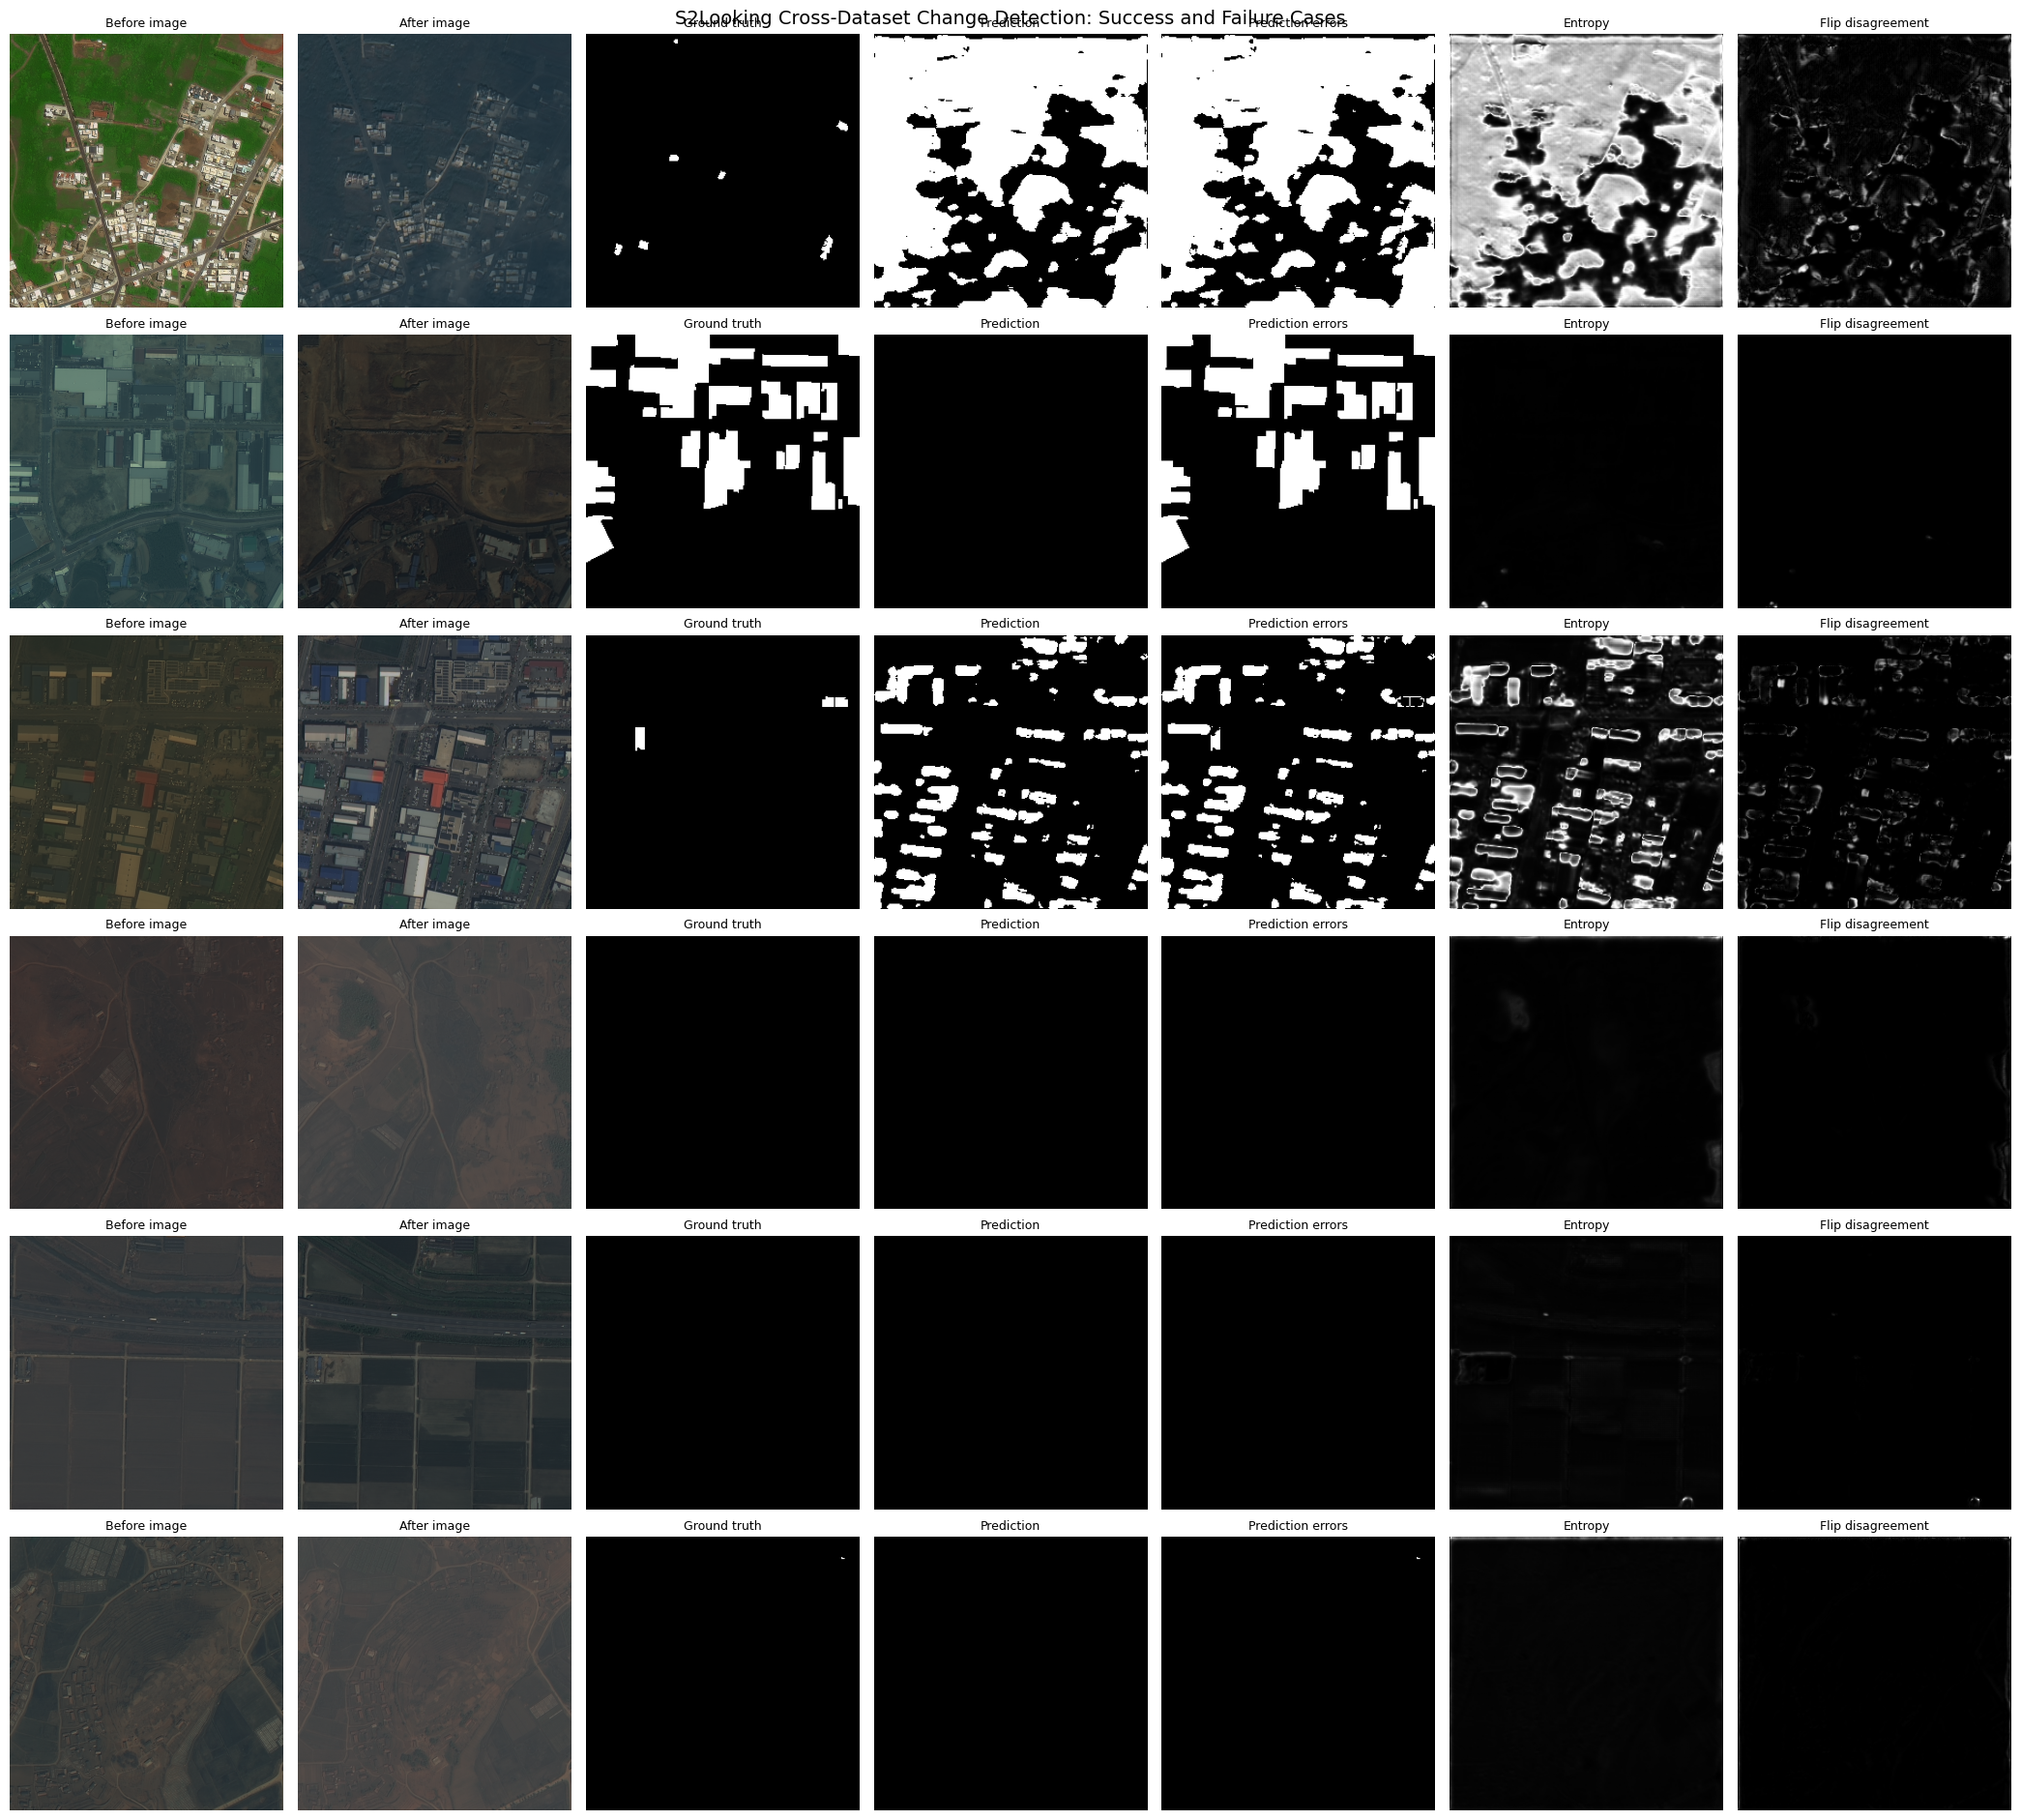

STEP 46: QUALITATIVE CASES
Selected filenames:
3320.png | pixel error: 0.62929
746.png | pixel error: 0.24051
3033.png | pixel error: 0.1627
1755.png | pixel error: 0.0
4434.png | pixel error: 0.0
2007.png | pixel error: 6e-05

Saved figure: /kaggle/working/uncertainty_change_detection/step46_qualitative_cases.png


In [47]:

import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"
S2_ROOT = "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"

aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
entropy = aligned["entropy"].astype(np.float32)
flip = flip_data["flip_disagreement"].astype(np.float32)
filenames = aligned["filenames"].astype(str)

assert np.array_equal(filenames, flip_data["filenames"].astype(str))
assert np.array_equal(ground_truth, flip_data["ground_truth"])

threshold = 0.40
predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).astype(np.uint8)

# Locate filenames in the current test split.
image1_dir = os.path.join(S2_ROOT, "test", "Image1")
image2_dir = os.path.join(S2_ROOT, "test", "Image2")

image1_files = set(os.listdir(image1_dir))
image2_files = set(os.listdir(image2_dir))

assert set(filenames).issubset(image1_files)
assert set(filenames).issubset(image2_files)

# Select three images with the highest error and three with lower error.
per_image_error = errors.mean(axis=(1, 2))
ranked = np.argsort(per_image_error)

selected = list(ranked[-3:][::-1]) + list(ranked[:3])

fig, axes = plt.subplots(
    len(selected), 7, figsize=(21, 3.2 * len(selected))
)

for row, idx in enumerate(selected):
    filename = filenames[idx]

    before = plt.imread(os.path.join(image1_dir, filename))
    after = plt.imread(os.path.join(image2_dir, filename))

    # Images are displayed at original resolution; masks/predictions are 256x256.
    panels = [
        (before, "Before image"),
        (after, "After image"),
        (ground_truth[idx], "Ground truth"),
        (predictions[idx], "Prediction"),
        (errors[idx], "Prediction errors"),
        (entropy[idx], "Entropy"),
        (flip[idx], "Flip disagreement")
    ]

    for col, (image, title) in enumerate(panels):
        ax = axes[row, col]
        if image.ndim == 2:
            ax.imshow(image, cmap="gray")
        else:
            ax.imshow(image)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

    axes[row, 0].set_ylabel(
        f"{filename}\nError={per_image_error[idx]:.4f}",
        fontsize=9
    )

plt.suptitle(
    "S2Looking Cross-Dataset Change Detection: Success and Failure Cases",
    fontsize=14
)
plt.tight_layout()

figure_path = os.path.join(
    OUT_DIR, "step46_qualitative_cases.png"
)
plt.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("=" * 65)
print("STEP 46: QUALITATIVE CASES")
print("=" * 65)
print("Selected filenames:")
for idx in selected:
    print(
        filenames[idx],
        "| pixel error:",
        round(float(per_image_error[idx]), 5)
    )
print("\nSaved figure:", figure_path)


In [48]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
entropy = aligned["entropy"].astype(np.float32)
flip = flip_data["flip_disagreement"].astype(np.float32)
filenames = aligned["filenames"].astype(str)

assert np.array_equal(filenames, flip_data["filenames"].astype(str))
assert np.array_equal(ground_truth, flip_data["ground_truth"])

threshold = 0.40
predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).astype(np.uint8)

selected_filenames = [
    "746.png",
    "1970.png",
    "4519.png",
    "4434.png",
    "1755.png",
    "2007.png"
]

rows = []

for filename in selected_filenames:
    matches = np.where(filenames == filename)[0]

    if len(matches) != 1:
        print("Skipping filename not uniquely found:", filename)
        continue

    i = int(matches[0])
    y_error = errors[i].ravel()
    entropy_score = entropy[i].ravel()
    flip_score = flip[i].ravel()

    row = {
        "filename": filename,
        "pixel_error": float(y_error.mean()),
        "error_pixels": int(y_error.sum()),
        "total_pixels": int(len(y_error)),
        "mean_entropy_on_errors": (
            float(entropy_score[y_error == 1].mean())
            if y_error.sum() else np.nan
        ),
        "mean_flip_on_errors": (
            float(flip_score[y_error == 1].mean())
            if y_error.sum() else np.nan
        ),
    }

    if len(np.unique(y_error)) == 2:
        row["entropy_error_auroc"] = roc_auc_score(
            y_error, entropy_score
        )
        row["flip_error_auroc"] = roc_auc_score(
            y_error, flip_score
        )
        row["entropy_error_ap"] = average_precision_score(
            y_error, entropy_score
        )
        row["flip_error_ap"] = average_precision_score(
            y_error, flip_score
        )
    else:
        row["entropy_error_auroc"] = np.nan
        row["flip_error_auroc"] = np.nan
        row["entropy_error_ap"] = np.nan
        row["flip_error_ap"] = np.nan

    rows.append(row)

results = pd.DataFrame(rows)
results.to_csv(
    os.path.join(OUT_DIR, "step47_selected_image_error_ranking.csv"),
    index=False
)

print("=" * 65)
print("STEP 47: ERROR RANKING ON SELECTED IMAGES")
print("=" * 65)
print(results.round(6).to_string(index=False))
print("\nSaved step47_selected_image_error_ranking.csv")


STEP 47: ERROR RANKING ON SELECTED IMAGES
filename  pixel_error  error_pixels  total_pixels  mean_entropy_on_errors  mean_flip_on_errors  entropy_error_auroc  flip_error_auroc  entropy_error_ap  flip_error_ap
 746.png     0.240509         15762         65536                0.005878             0.000078             0.520495          0.535170          0.240104       0.260352
1970.png     0.133545          8752         65536                0.006460             0.000092             0.557671          0.517749          0.156083       0.141542
4519.png     0.124435          8155         65536                0.005493             0.000119             0.595590          0.751825          0.279537       0.460493
4434.png     0.000000             0         65536                     NaN                  NaN                  NaN               NaN               NaN            NaN
1755.png     0.000000             0         65536                     NaN                  NaN                  NaN        

In [49]:

import os
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
entropy = aligned["entropy"].astype(np.float32)
flip = flip_data["flip_disagreement"].astype(np.float32)
filenames = aligned["filenames"].astype(str)

assert np.array_equal(filenames, flip_data["filenames"].astype(str))
assert np.array_equal(ground_truth, flip_data["ground_truth"])

threshold = 0.40
review_fraction = 0.30

predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).astype(np.uint8)

rows = []

for i, filename in enumerate(filenames):
    image_errors = errors[i].ravel()
    overall_error = float(image_errors.mean())
    n_pixels = len(image_errors)
    n_review = int(n_pixels * review_fraction)

    entropy_order = np.argsort(entropy[i].ravel())[::-1]
    flip_order = np.argsort(flip[i].ravel())[::-1]

    entropy_retained = float(
        image_errors[entropy_order[n_review:]].mean()
    )
    flip_retained = float(
        image_errors[flip_order[n_review:]].mean()
    )

    rows.append({
        "filename": filename,
        "overall_error": overall_error,
        "entropy_retained_error": entropy_retained,
        "flip_retained_error": flip_retained,
        "entropy_reduction": (
            (overall_error - entropy_retained) / overall_error
            if overall_error > 0 else np.nan
        ),
        "flip_reduction": (
            (overall_error - flip_retained) / overall_error
            if overall_error > 0 else np.nan
        ),
        "flip_minus_entropy_retained_error": (
            flip_retained - entropy_retained
        )
    })

df = pd.DataFrame(rows)
df.to_csv(
    os.path.join(OUT_DIR, "step48_all_image_review_analysis.csv"),
    index=False
)

valid = df[df["overall_error"] > 0].copy()

summary = {
    "total_images": int(len(df)),
    "images_with_errors": int(len(valid)),
    "images_without_errors": int((df["overall_error"] == 0).sum()),
    "flip_lower_retained_error": int(
        (valid["flip_retained_error"] < valid["entropy_retained_error"]).sum()
    ),
    "entropy_lower_retained_error": int(
        (valid["entropy_retained_error"] < valid["flip_retained_error"]).sum()
    ),
    "tied": int(
        (valid["entropy_retained_error"] == valid["flip_retained_error"]).sum()
    ),
    "both_methods_increase_error": int(
        (
            (valid["entropy_retained_error"] > valid["overall_error"]) &
            (valid["flip_retained_error"] > valid["overall_error"])
        ).sum()
    ),
    "mean_entropy_reduction": float(valid["entropy_reduction"].mean()),
    "mean_flip_reduction": float(valid["flip_reduction"].mean())
}

print("=" * 65)
print("STEP 48: ALL-IMAGE REVIEW ANALYSIS")
print("=" * 65)

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nWorst 10 images after flip-guided review:")
print(
    df.sort_values("flip_retained_error", ascending=False)
      [["filename", "overall_error", "entropy_retained_error",
        "flip_retained_error"]]
      .head(10)
      .round(6)
      .to_string(index=False)
)

print("\nSaved step48_all_image_review_analysis.csv")


STEP 48: ALL-IMAGE REVIEW ANALYSIS
total_images: 1000
images_with_errors: 998
images_without_errors: 2
flip_lower_retained_error: 701
entropy_lower_retained_error: 266
tied: 31
both_methods_increase_error: 135
mean_entropy_reduction: 0.22967507349427704
mean_flip_reduction: 0.32778103090197486

Worst 10 images after flip-guided review:
filename  overall_error  entropy_retained_error  flip_retained_error
3320.png       0.629288                0.521798             0.606134
 746.png       0.240509                0.229488             0.225456
1970.png       0.133545                0.119431             0.127997
3498.png       0.090820                0.128150             0.121763
2967.png       0.100098                0.136869             0.117076
3533.png       0.117279                0.114766             0.104761
3458.png       0.088120                0.079628             0.089480
3959.png       0.121216                0.073764             0.080216
3921.png       0.107635                0.

In [50]:

import os
import json
import numpy as np
import pandas as pd

OUT_DIR = "/kaggle/working/uncertainty_change_detection"

# Load the saved aligned arrays.
aligned = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_arrays.npz")
)
flip_data = np.load(
    os.path.join(OUT_DIR, "s2looking_aligned_flip_predictions.npz")
)

probabilities = aligned["probabilities"].astype(np.float32)
ground_truth = aligned["ground_truth"].astype(np.uint8)
entropy = aligned["entropy"].astype(np.float32)
flip = flip_data["flip_disagreement"].astype(np.float32)

assert np.array_equal(
    aligned["filenames"].astype(str),
    flip_data["filenames"].astype(str)
)
assert np.array_equal(ground_truth, flip_data["ground_truth"])

threshold = 0.40
review_fraction = 0.30

predictions = (probabilities >= threshold).astype(np.uint8)
errors = (predictions != ground_truth).astype(np.uint8)

# Pooled segmentation metrics.
tp = int(((predictions == 1) & (ground_truth == 1)).sum())
fp = int(((predictions == 1) & (ground_truth == 0)).sum())
fn = int(((predictions == 0) & (ground_truth == 1)).sum())

precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0.0
)
iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
overall_error = float(errors.mean())

# Pooled selective-review results.
n_pixels = errors.size
n_review = int(n_pixels * review_fraction)

entropy_order = np.argsort(entropy.ravel())[::-1]
flip_order = np.argsort(flip.ravel())[::-1]

entropy_retained_error = float(
    errors.ravel()[entropy_order[n_review:]].mean()
)
flip_retained_error = float(
    errors.ravel()[flip_order[n_review:]].mean()
)

# Read previously computed statistical results.
bootstrap_path = os.path.join(
    OUT_DIR, "step45_bootstrap_summary.csv"
)
bootstrap = pd.read_csv(bootstrap_path)

per_image_path = os.path.join(
    OUT_DIR, "step48_all_image_review_analysis.csv"
)
per_image = pd.read_csv(per_image_path)

valid = per_image[per_image["overall_error"] > 0]

summary = {
    "test_images": int(len(ground_truth)),
    "classification_threshold": threshold,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "iou": iou,
    "pooled_pixel_error": overall_error,
    "entropy_retained_error_at_30pct_review": entropy_retained_error,
    "flip_retained_error_at_30pct_review": flip_retained_error,
    "entropy_pooled_error_reduction_at_30pct": (
        (overall_error - entropy_retained_error) / overall_error
    ),
    "flip_pooled_error_reduction_at_30pct": (
        (overall_error - flip_retained_error) / overall_error
    ),
    "mean_per_image_entropy_reduction": float(
        valid["entropy_reduction"].mean()
    ),
    "mean_per_image_flip_reduction": float(
        valid["flip_reduction"].mean()
    ),
    "images_where_flip_wins": int(
        (
            valid["flip_retained_error"]
            < valid["entropy_retained_error"]
        ).sum()
    ),
    "images_where_entropy_wins": int(
        (
            valid["entropy_retained_error"]
            < valid["flip_retained_error"]
        ).sum()
    ),
    "images_tied": int(
        (
            valid["entropy_retained_error"]
            == valid["flip_retained_error"]
        ).sum()
    )
}

with open(
    os.path.join(OUT_DIR, "step49_final_results_summary.json"), "w"
) as f:
    json.dump(summary, f, indent=2)

pd.DataFrame(
    [{"metric": k, "value": v} for k, v in summary.items()]
).to_csv(
    os.path.join(OUT_DIR, "step49_final_results_summary.csv"),
    index=False
)

print("=" * 65)
print("STEP 49: CONSOLIDATED EXPERIMENTAL RESULTS")
print("=" * 65)

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nPaired bootstrap evidence: flip vs random")
print(bootstrap.round(7).to_string(index=False))

print("\nSaved final summary JSON and CSV.")


STEP 49: CONSOLIDATED EXPERIMENTAL RESULTS
test_images: 1000
classification_threshold: 0.4
precision: 0.10589652748891981
recall: 0.018615147026379654
f1: 0.03166417023083365
iou: 0.016086772263118845
pooled_pixel_error: 0.013780685424804687
entropy_retained_error_at_30pct_review: 0.011926487513950894
flip_retained_error_at_30pct_review: 0.010142451695033482
entropy_pooled_error_reduction_at_30pct: 0.13455048524047367
flip_pooled_error_reduction_at_30pct: 0.26400963505215264
mean_per_image_entropy_reduction: 0.22967507349427704
mean_per_image_flip_reduction: 0.32778103090197486
images_where_flip_wins: 701
images_where_entropy_wins: 266
images_tied: 31

Paired bootstrap evidence: flip vs random
 review_fraction  images  mean_random_minus_flip_error  ci95_lower  ci95_upper  fraction_images_flip_wins  ci_excludes_zero
            0.05    1000                      0.001864    0.001661    0.002085                      0.785              True
            0.10    1000                      0.0

In [51]:

# STEP 50: Audit S2Looking arrays and prediction alignment

from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path("/kaggle/working/uncertainty_change_detection")

arrays_file = OUT / "s2looking_aligned_arrays.npz"
flip_file = OUT / "s2looking_aligned_flip_predictions.npz"
manifest_file = OUT / "s2looking_aligned_manifest.csv"

print("=" * 65)
print("STEP 50: DATA AND PREDICTION AUDIT")
print("=" * 65)

# 1. Check that required files exist
for path in [arrays_file, flip_file, manifest_file]:
    print(f"{path.name}: {'EXISTS' if path.exists() else 'MISSING'}")

assert arrays_file.exists(), "Aligned prediction arrays are missing."
assert flip_file.exists(), "Flip prediction arrays are missing."
assert manifest_file.exists(), "Aligned manifest is missing."

# 2. Load arrays
with np.load(arrays_file) as data:
    probabilities = data["probabilities"]
    ground_truth = data["ground_truth"]
    entropy = data["entropy"]
    filenames = data["filenames"]

with np.load(flip_file) as data:
    original = data["original"]
    flipped = data["flipped_restored"]
    disagreement = data["flip_disagreement"]
    flip_gt = data["ground_truth"]
    flip_filenames = data["filenames"]

manifest = pd.read_csv(manifest_file)

# 3. Print dimensions
print("\n--- Shapes ---")
for name, arr in [
    ("probabilities", probabilities),
    ("ground_truth", ground_truth),
    ("entropy", entropy),
    ("original", original),
    ("flipped_restored", flipped),
    ("flip_disagreement", disagreement),
    ("flip_ground_truth", flip_gt),
]:
    print(f"{name:22s}: {arr.shape}, dtype={arr.dtype}")

print(f"filenames: {len(filenames)}")
print(f"flip_filenames: {len(flip_filenames)}")
print(f"manifest rows: {len(manifest)}")

# 4. Check dimensions and filename order
assert probabilities.shape == ground_truth.shape
assert probabilities.shape == entropy.shape
assert probabilities.shape == original.shape
assert probabilities.shape == flipped.shape
assert probabilities.shape == disagreement.shape
assert probabilities.shape == flip_gt.shape

assert np.array_equal(filenames, flip_filenames), \
    "Filename order differs between prediction files!"

assert np.array_equal(ground_truth, flip_gt), \
    "Ground-truth masks differ between prediction files!"

print("\nPASS: array dimensions, filename order, and masks match.")

# 5. Check numerical ranges and NaN/Inf values
for name, arr in [
    ("probabilities", probabilities),
    ("ground_truth", ground_truth),
    ("entropy", entropy),
    ("original", original),
    ("flipped_restored", flipped),
    ("disagreement", disagreement),
]:
    print(
        f"{name:22s}: min={np.nanmin(arr):.6f}, "
        f"max={np.nanmax(arr):.6f}, "
        f"finite={np.isfinite(arr).all()}"
    )
    assert np.isfinite(arr).all(), f"Non-finite values in {name}!"

assert probabilities.min() >= 0 and probabilities.max() <= 1
assert original.min() >= 0 and original.max() <= 1
assert flipped.min() >= 0 and flipped.max() <= 1

# 6. Verify derived entropy and flip disagreement
eps = 1e-7
p = np.clip(probabilities.astype(np.float64), eps, 1 - eps)
recomputed_entropy = -(
    p * np.log(p) + (1 - p) * np.log(1 - p)
)

entropy_difference = np.mean(
    np.abs(recomputed_entropy - entropy)
)
disagreement_difference = np.mean(
    np.abs(np.abs(original - flipped) - disagreement)
)

print("\n--- Derived-score checks ---")
print(f"Mean entropy difference: {entropy_difference:.10f}")
print(f"Mean disagreement difference: {disagreement_difference:.10f}")

# 7. Basic ground-truth statistics
gt = ground_truth > 0.5
pred = probabilities >= 0.40

print("\n--- Dataset summary ---")
print(f"Images: {len(filenames)}")
print(f"Ground-truth change fraction: {gt.mean():.8f}")
print(f"Predicted change fraction @ 0.40: {pred.mean():.8f}")
print(f"Mean probability: {probabilities.mean():.8f}")
print(f"Images with any GT change: {gt.reshape(len(gt), -1).any(axis=1).sum()}")

print("\nSTEP 50 COMPLETE")
print("Please share the complete output before running another cell.")


STEP 50: DATA AND PREDICTION AUDIT
s2looking_aligned_arrays.npz: EXISTS
s2looking_aligned_flip_predictions.npz: EXISTS
s2looking_aligned_manifest.csv: EXISTS

--- Shapes ---
probabilities         : (1000, 256, 256), dtype=float16
ground_truth          : (1000, 256, 256), dtype=uint8
entropy               : (1000, 256, 256), dtype=float16
original              : (1000, 256, 256), dtype=float16
flipped_restored      : (1000, 256, 256), dtype=float16
flip_disagreement     : (1000, 256, 256), dtype=float16
flip_ground_truth     : (1000, 256, 256), dtype=uint8
filenames: 1000
flip_filenames: 1000
manifest rows: 1000

PASS: array dimensions, filename order, and masks match.
probabilities         : min=0.000020, max=1.000000, finite=True
ground_truth          : min=0.000000, max=1.000000, finite=True
entropy               : min=0.000232, max=0.693359, finite=True
original              : min=0.000020, max=1.000000, finite=True
flipped_restored      : min=0.000021, max=1.000000, finite=True
dis

3320.png: pixel_error=0.629333, source_files_found=True
1021.png: pixel_error=0.008179, source_files_found=True
1755.png: pixel_error=0.000000, source_files_found=True


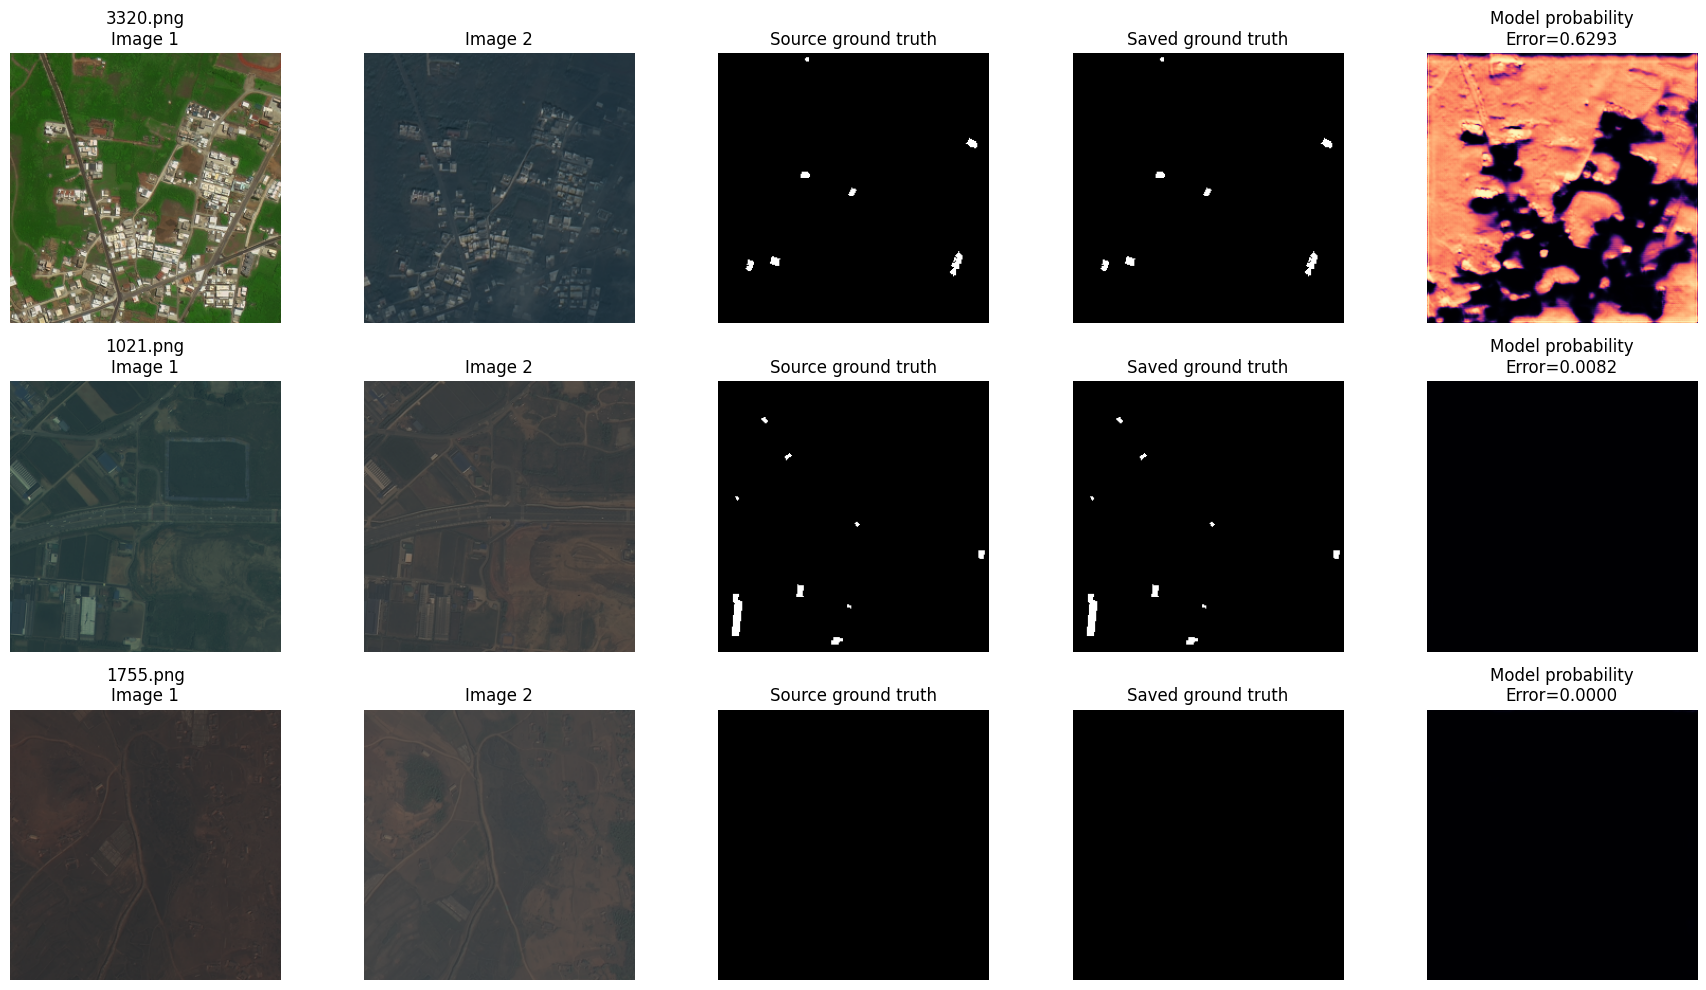

In [52]:

# STEP 51: Visual audit of S2Looking image pairs and predictions

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from PIL import Image

DATA = Path("/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking")
OUT = Path("/kaggle/working/uncertainty_change_detection")

# Select examples from the saved, aligned prediction order
with np.load(OUT / "s2looking_aligned_arrays.npz") as data:
    probs = data["probabilities"]
    gt_masks = data["ground_truth"]
    filenames = data["filenames"]

# Choose one high-error, one medium-error, and one low-error example
pred_masks = probs >= 0.40
errors = (pred_masks != (gt_masks > 0.5)).mean(axis=(1, 2))
order = np.argsort(errors)

indices = [int(order[-1]), int(order[len(order)//2]), int(order[0])]

def find_image(folder, filename):
    matches = list(folder.rglob(str(filename)))
    return matches[0] if matches else None

fig, axes = plt.subplots(3, 5, figsize=(18, 10))

for row, idx in enumerate(indices):
    filename = str(filenames[idx])
    stem = Path(filename).stem

    # Find original pair and label in S2Looking test split
    split = DATA / "test"
    a_path = find_image(split / "Image1", filename)
    b_path = find_image(split / "Image2", filename)
    label_path = find_image(split / "label", filename)

    # Try stem-based lookup if manifest filename includes an extension mismatch
    if a_path is None:
        a_path = next(iter((split / "Image1").glob(stem + ".*")), None)
    if b_path is None:
        b_path = next(iter((split / "Image2").glob(stem + ".*")), None)
    if label_path is None:
        label_path = next(iter((split / "label").glob(stem + ".*")), None)

    print(
        f"{filename}: pixel_error={errors[idx]:.6f}, "
        f"source_files_found={a_path is not None and b_path is not None and label_path is not None}"
    )

    if a_path is None or b_path is None or label_path is None:
        for ax in axes[row]:
            ax.axis("off")
        axes[row, 0].text(
            0.05, 0.5,
            f"Could not locate files for {filename}\n"
            f"A={a_path}\nB={b_path}\nLabel={label_path}",
            transform=axes[row, 0].transAxes
        )
        continue

    img_a = Image.open(a_path).convert("RGB").resize((256, 256))
    img_b = Image.open(b_path).convert("RGB").resize((256, 256))
    source_gt = Image.open(label_path).convert("L").resize(
        (256, 256), Image.Resampling.NEAREST
    )

    axes[row, 0].imshow(img_a)
    axes[row, 0].set_title(f"{filename}\nImage 1")

    axes[row, 1].imshow(img_b)
    axes[row, 1].set_title("Image 2")

    axes[row, 2].imshow(source_gt, cmap="gray", vmin=0, vmax=255)
    axes[row, 2].set_title("Source ground truth")

    axes[row, 3].imshow(gt_masks[idx], cmap="gray", vmin=0, vmax=1)
    axes[row, 3].set_title("Saved ground truth")

    axes[row, 4].imshow(probs[idx], cmap="magma", vmin=0, vmax=1)
    axes[row, 4].set_title(
        f"Model probability\nError={errors[idx]:.4f}"
    )

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [53]:

# STEP 52: Inspect prediction confidence and preprocessing configuration

import json
from pathlib import Path
import numpy as np

OUT = Path("/kaggle/working/uncertainty_change_detection")

# 1. Load the recorded training configuration
config_path = OUT / "training_config.json"

print("=" * 65)
print("STEP 52: PREPROCESSING AND CONFIDENCE AUDIT")
print("=" * 65)

if config_path.exists():
    with open(config_path, "r") as f:
        config = json.load(f)
    print("\n--- Training configuration ---")
    print(json.dumps(config, indent=2))
else:
    print("training_config.json not found.")

# 2. Inspect the saved S2Looking predictions
with np.load(OUT / "s2looking_aligned_arrays.npz") as data:
    probs = data["probabilities"].astype(np.float32)
    gt = data["ground_truth"] > 0
    filenames = data["filenames"]

print("\n--- Probability distribution ---")
for q in [0, 25, 50, 75, 90, 95, 99, 99.9, 100]:
    print(f"Probability percentile {q:5g}: {np.percentile(probs, q):.8f}")

print("\n--- Threshold diagnostics ---")
for threshold in [0.01, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50]:
    pred = probs >= threshold
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    print(
        f"threshold={threshold:.2f} | "
        f"predicted_fraction={pred.mean():.6f} | "
        f"precision={precision:.4f} | "
        f"recall={recall:.4f} | F1={f1:.4f}"
    )

# 3. Check the training and target image normalization assumptions
print("\n--- Expected preprocessing checks ---")
print("Training/target image pipeline should use:")
print("  RGB images")
print("  Resize to 256 x 256")
print("  Convert pixels to float and divide by 255")
print("  Concatenate before/after images into 6 channels")
print("  Ground-truth masks resized with nearest-neighbor interpolation")
print("\nNote: This section lists expected settings; it does not independently")
print("verify the original image-loading code.")

print("\nSTEP 52 COMPLETE")
print("Share the full output before proceeding.")


STEP 52: PREPROCESSING AND CONFIDENCE AUDIT

--- Training configuration ---
{
  "seed": 42,
  "image_size": 256,
  "batch_size": 8,
  "epochs_requested": 10,
  "learning_rate": 0.001,
  "train_pairs": 541,
  "validation_pairs": 96,
  "loss": "BCEWithLogits + soft Dice",
  "validation_threshold_for_checkpoint_selection": 0.5,
  "device": "cuda"
}

--- Probability distribution ---
Probability percentile     0: 0.00001961
Probability percentile    25: 0.00057173
Probability percentile    50: 0.00075769
Probability percentile    75: 0.00122547
Probability percentile    90: 0.00207329
Probability percentile    95: 0.00308800
Probability percentile    99: 0.01210022
Probability percentile  99.9: 0.79345703
Probability percentile   100: 1.00000000

--- Threshold diagnostics ---
threshold=0.01 | predicted_fraction=0.011743 | precision=0.0478 | recall=0.0463 | F1=0.0470
threshold=0.05 | predicted_fraction=0.003983 | precision=0.0884 | recall=0.0291 | F1=0.0438
threshold=0.10 | predicted_fractio

In [54]:

# STEP 53: Inspect actual image preprocessing functions

import inspect

print("=" * 65)
print("STEP 53: ACTUAL PREPROCESSING CODE AUDIT")
print("=" * 65)

# Look for commonly used image-loading functions in the notebook
candidate_names = [
    "load_image",
    "load_pair",
    "preprocess_image",
    "preprocess_pair",
    "get_image",
    "read_image",
    "load_s2_sample",
    "S2LookingDataset",
    "ChangeDetectionDataset",
]

found = False

for name in candidate_names:
    obj = globals().get(name)

    if obj is None:
        continue

    try:
        source = inspect.getsource(obj)
        print(f"\n--- {name} ---")
        print(source[:10000])
        found = True
    except (OSError, TypeError):
        print(f"\n{name}: found, but Python source is unavailable.")

print("\n--- Relevant variables ---")
for name in [
    "DATA_DIR", "S2_DIR", "IMG_SIZE", "IMAGE_SIZE",
    "transform", "image_transform", "s2_test_loader"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")
        if name not in ["s2_test_loader"]:
            print(str(obj)[:1000])

if not found:
    print(
        "\nNo recognized preprocessing function source was found. "
        "We will inspect the original notebook cells directly instead."
    )

print("\nSTEP 53 COMPLETE")


STEP 53: ACTUAL PREPROCESSING CODE AUDIT

--- Relevant variables ---
DATA_DIR: PosixPath
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+
IMAGE_SIZE: int
256
s2_test_loader: DataLoader

No recognized preprocessing function source was found. We will inspect the original notebook cells directly instead.

STEP 53 COMPLETE


In [55]:

# STEP 54: Search notebook execution history for preprocessing code

keywords = [
    "DataLoader",
    "Image.Resampling",
    "INTER_LINEAR",
    "INTER_NEAREST",
    "resize(",
    "Resize(",
    "/ 255",
    "/255",
    "Normalize",
    "Image1",
    "Image2",
    "Image.open",
    "ToTensor",
    "np.concatenate",
    "torch.cat",
    "s2_test_loader",
]

history = globals().get("_ih", [])
matches = []

print("=" * 65)
print("STEP 54: NOTEBOOK CODE SEARCH")
print("=" * 65)

for cell_index, source in enumerate(history):
    if not isinstance(source, str):
        continue

    found_keywords = [
        keyword for keyword in keywords
        if keyword.lower() in source.lower()
    ]

    if found_keywords:
        matches.append((cell_index, found_keywords, source))

print(f"Execution-history cells available: {len(history)}")
print(f"Matching cells found: {len(matches)}")

for cell_index, found_keywords, source in matches[-12:]:
    print("\n" + "=" * 65)
    print(f"CELL INDEX: {cell_index}")
    print("MATCHES:", ", ".join(found_keywords))
    print("-" * 65)
    print(source[:5000])
    if len(source) > 5000:
        print("\n[Cell truncated to 5000 characters]")

if not matches:
    print(
        "\nNo matching source found in execution history. "
        "The next step will be to inspect the dataset loader directly."
    )

print("\nSTEP 54 COMPLETE")


STEP 54: NOTEBOOK CODE SEARCH
Execution-history cells available: 56
Matching cells found: 23

CELL INDEX: 24
MATCHES: DataLoader, Image.Resampling, resize(, Resize(, / 255, Image1, Image2, Image.open, np.concatenate, s2_test_loader
-----------------------------------------------------------------
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
S2_ROOT = "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"
BATCH_SIZE = 8
IMAGE_SIZE = 256

class S2LookingInferenceDataset(Dataset):
    def __init__(self, root, split="test", image_size=256):
        self.root = os.path.join(root, split)
        self.image_dir = os.path.join(self.root, "Image1")
        self.image_size = image_size

        self.filenames = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
        ]

In [56]:

# STEP 55: Find the original LEVIR-CD training preprocessing

import re

history = globals().get("_ih", [])

keywords = [
    "LEVIR",
    "class ChangeDetectionDataset",
    "class LEVIR",
    "class ChangeDataset",
    "train_dataset",
    "train_loader",
    "label_dir",
    "mask_dir",
    "BCEWithLogitsLoss",
    "soft_dice",
]

matches = []

for cell_index, source in enumerate(history):
    if not isinstance(source, str):
        continue

    found = [k for k in keywords if k.lower() in source.lower()]
    if found:
        matches.append((cell_index, found, source))

print("=" * 65)
print("STEP 55: LEVIR TRAINING PIPELINE AUDIT")
print("=" * 65)
print("Matching cells:", len(matches))

# Show the earliest relevant training cells and the most recent matches.
selected = matches[:8]

for cell_index, found, source in selected:
    print("\n" + "=" * 65)
    print(f"CELL INDEX: {cell_index}")
    print("MATCHES:", ", ".join(found))
    print("-" * 65)
    print(source[:6000])
    if len(source) > 6000:
        print("[Cell truncated]")

if not selected:
    print(
        "No LEVIR training implementation found in execution history. "
        "We will inspect the available dataset objects next."
    )

print("\nSTEP 55 COMPLETE")


STEP 55: LEVIR TRAINING PIPELINE AUDIT
Matching cells: 17

CELL INDEX: 2
MATCHES: LEVIR
-----------------------------------------------------------------
import os
import sys
import shutil
import platform
import torch
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 65)
print("STEP 1: ENVIRONMENT AND PROJECT STATUS")
print("=" * 65)

# 1. System information
print("\n[1] SYSTEM")
print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

# 2. GPU information
print("\n[2] GPU")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1e9,
            2
        )
    

In [57]:

# STEP 56: Compare image and mask statistics across datasets

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

LEVIR = Path(
    "/kaggle/input/datasets/simranmaniyar/"
    "levir-cd-change-detection/LEVIR-CD+"
)
S2 = Path(
    "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"
)

IMAGE_SIZE = 256
SAMPLE_COUNT = 50
rng = np.random.default_rng(42)

def inspect_dataset(name, image1_dir, image2_dir, mask_dir):
    names = sorted(
        p.name for p in image1_dir.iterdir()
        if p.is_file()
        and (image2_dir / p.name).is_file()
        and (mask_dir / p.name).is_file()
    )

    selected = rng.choice(
        names, size=min(SAMPLE_COUNT, len(names)), replace=False
    )

    channel_values = []
    mask_fractions = []
    raw_mask_values = set()
    raw_dimensions = []

    for filename in selected:
        with Image.open(image1_dir / filename) as im:
            before_raw = im.convert("RGB")
            raw_dimensions.append(before_raw.size)
            before = before_raw.resize(
                (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR
            )

        with Image.open(image2_dir / filename) as im:
            after = im.convert("RGB").resize(
                (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR
            )

        with Image.open(mask_dir / filename) as im:
            mask_raw = np.asarray(im.convert("L"))
            raw_mask_values.update(np.unique(mask_raw).tolist())
            mask = im.convert("L").resize(
                (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.NEAREST
            )

        a = np.asarray(before, dtype=np.float32) / 255.0
        b = np.asarray(after, dtype=np.float32) / 255.0

        channel_values.append(
            np.stack([a.mean(axis=(0, 1)), b.mean(axis=(0, 1))])
        )
        mask_fractions.append(
            (np.asarray(mask) > 127).mean()
        )

    channel_values = np.asarray(channel_values)

    return {
        "dataset": name,
        "pairs_sampled": len(selected),
        "source_image_sizes": str(sorted(set(raw_dimensions))[:5]),
        "before_R_mean": channel_values[:, 0, 0].mean(),
        "before_G_mean": channel_values[:, 0, 1].mean(),
        "before_B_mean": channel_values[:, 0, 2].mean(),
        "after_R_mean": channel_values[:, 1, 0].mean(),
        "after_G_mean": channel_values[:, 1, 1].mean(),
        "after_B_mean": channel_values[:, 1, 2].mean(),
        "mean_GT_change_fraction": np.mean(mask_fractions),
        "raw_mask_values_sample": str(sorted(raw_mask_values)[:20]),
    }

print("=" * 65)
print("STEP 56: CROSS-DATASET STATISTICS")
print("=" * 65)

results = [
    inspect_dataset(
        "LEVIR-CD train",
        LEVIR / "train" / "A",
        LEVIR / "train" / "B",
        LEVIR / "train" / "label",
    ),
    inspect_dataset(
        "S2Looking test",
        S2 / "test" / "Image1",
        S2 / "test" / "Image2",
        S2 / "test" / "label",
    ),
]

df = pd.DataFrame(results)
print(df.to_string(index=False, float_format=lambda x: f"{x:.5f}"))

print("\nInterpretation:")
print("- Compare channel means to identify possible appearance shifts.")
print("- Compare mask values to verify binary-label encoding.")
print("- This is a small descriptive sample, not a statistical test.")

print("\nSTEP 56 COMPLETE")


STEP 56: CROSS-DATASET STATISTICS
       dataset  pairs_sampled source_image_sizes  before_R_mean  before_G_mean  before_B_mean  after_R_mean  after_G_mean  after_B_mean  mean_GT_change_fraction raw_mask_values_sample
LEVIR-CD train             50     [(1024, 1024)]        0.43666        0.42974        0.36873       0.33822       0.33009       0.28047                  0.03766          [0, 254, 255]
S2Looking test             50     [(1024, 1024)]        0.16915        0.20837        0.20546       0.21145       0.22629       0.21567                  0.01100               [0, 255]

Interpretation:
- Compare channel means to identify possible appearance shifts.
- Compare mask values to verify binary-label encoding.
- This is a small descriptive sample, not a statistical test.

STEP 56 COMPLETE


In [58]:

# STEP 57: Larger-sample brightness and contrast comparison

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

LEVIR = Path(
    "/kaggle/input/datasets/simranmaniyar/"
    "levir-cd-change-detection/LEVIR-CD+"
)
S2 = Path(
    "/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking"
)

rng = np.random.default_rng(42)
N = 200
SIZE = 256

def sample_stats(name, image1_dir, image2_dir):
    names = sorted(
        p.name for p in image1_dir.iterdir()
        if p.is_file() and (image2_dir / p.name).is_file()
    )
    selected = rng.choice(names, size=min(N, len(names)), replace=False)

    rows = []
    for filename in selected:
        for period, folder in [
            ("before", image1_dir),
            ("after", image2_dir),
        ]:
            with Image.open(folder / filename) as im:
                arr = np.asarray(
                    im.convert("RGB").resize(
                        (SIZE, SIZE), Image.Resampling.BILINEAR
                    ),
                    dtype=np.float32
                ) / 255.0

            rows.append({
                "dataset": name,
                "period": period,
                "filename": filename,
                "brightness": float(arr.mean()),
                "contrast_std": float(arr.std()),
                "R_mean": float(arr[:, :, 0].mean()),
                "G_mean": float(arr[:, :, 1].mean()),
                "B_mean": float(arr[:, :, 2].mean()),
            })

    return rows

rows = []
rows += sample_stats(
    "LEVIR-CD",
    LEVIR / "train" / "A",
    LEVIR / "train" / "B",
)
rows += sample_stats(
    "S2Looking",
    S2 / "test" / "Image1",
    S2 / "test" / "Image2",
)

df = pd.DataFrame(rows)

summary = (
    df.groupby(["dataset", "period"])[
        ["brightness", "contrast_std", "R_mean", "G_mean", "B_mean"]
    ]
    .agg(["mean", "median", "std"])
    .round(5)
)

print("=" * 65)
print("STEP 57: LARGER-SAMPLE DISTRIBUTION CHECK")
print("=" * 65)
print("Image pairs sampled per dataset:", N)
print(summary.to_string())

print("\nSTEP 57 COMPLETE")


STEP 57: LARGER-SAMPLE DISTRIBUTION CHECK
Image pairs sampled per dataset: 200
                 brightness                   contrast_std                     R_mean                     G_mean                     B_mean                  
                       mean   median      std         mean   median      std     mean   median      std     mean   median      std     mean   median      std
dataset   period                                                                                                                                             
LEVIR-CD  after     0.32086  0.31775  0.04934      0.11994  0.12172  0.03048  0.34236  0.34552  0.05335  0.33440  0.33202  0.04882  0.28582  0.28441  0.04748
          before    0.41872  0.41928  0.06459      0.16028  0.16091  0.05129  0.44277  0.44228  0.07177  0.43928  0.43763  0.06813  0.37413  0.37773  0.05884
S2Looking after     0.21677  0.20639  0.04850      0.04106  0.03908  0.01637  0.21007  0.19957  0.04966  0.22504  0.21339  0.04786 

In [59]:

# STEP 58: TEST CHANNEL-WISE STANDARDIZATION
import numpy as np
import pandas as pd

arr = np.load(
    "/kaggle/working/uncertainty_change_detection/"
    "s2looking_aligned_arrays.npz"
)

# Reconstruct original normalized images using the existing S2Looking loader.
# Inspect existing notebook variables first to avoid silently changing preprocessing.
print("Available variables:")
for name in ["s2_test_loader", "model", "DEVICE"]:
    print(f"{name}: {name in globals()}")

print("\nStored arrays:")
for key in arr.files:
    value = arr[key]
    print(key, value.shape, value.dtype)

print("\nDiagnostic plan:")
print("1. Retrieve a batch from s2_test_loader.")
print("2. Compare before/after channel means and standard deviations.")
print("3. Compare LEVIR training channel statistics with S2Looking.")
print("4. Evaluate normalization as a diagnostic only; do not retrain or overwrite artifacts.")


Available variables:
s2_test_loader: True
model: True
DEVICE: True

Stored arrays:
probabilities (1000, 256, 256) float16
ground_truth (1000, 256, 256) uint8
entropy (1000, 256, 256) float16
filenames (1000,) <U8

Diagnostic plan:
1. Retrieve a batch from s2_test_loader.
2. Compare before/after channel means and standard deviations.
3. Compare LEVIR training channel statistics with S2Looking.
4. Evaluate normalization as a diagnostic only; do not retrain or overwrite artifacts.


In [60]:

# STEP 59: COMPARE SOURCE AND TARGET IMAGE STATISTICS
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

LEVIR = Path("/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+")
S2 = Path("/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking")

rng = np.random.default_rng(42)
N = 200
SIZE = 256

def collect_stats(dataset, before_dir, after_dir, n=200):
    before_dir, after_dir = Path(before_dir), Path(after_dir)
    names = sorted(
        p.name for p in before_dir.iterdir()
        if p.is_file() and (after_dir / p.name).is_file()
    )
    selected = rng.choice(names, size=min(n, len(names)), replace=False)
    rows = []

    for filename in selected:
        for period, folder in [("before", before_dir), ("after", after_dir)]:
            with Image.open(folder / filename) as im:
                x = np.asarray(
                    im.convert("RGB").resize(
                        (SIZE, SIZE), Image.Resampling.BILINEAR
                    ),
                    dtype=np.float32
                ) / 255.0

            for c, channel in enumerate(["R", "G", "B"]):
                values = x[:, :, c]
                rows.append({
                    "dataset": dataset,
                    "period": period,
                    "channel": channel,
                    "mean": float(values.mean()),
                    "std": float(values.std())
                })

    return rows

rows = []
rows += collect_stats(
    "LEVIR-CD", LEVIR / "train" / "A", LEVIR / "train" / "B", N
)
rows += collect_stats(
    "S2Looking", S2 / "test" / "Image1", S2 / "test" / "Image2", N
)

stats = pd.DataFrame(rows)
summary = (
    stats.groupby(["dataset", "period", "channel"])[["mean", "std"]]
    .agg(["mean", "std"])
    .round(5)
)

print("STEP 59: CHANNEL-WISE DISTRIBUTION COMPARISON")
print(summary.to_string())

print("\nMean absolute difference between datasets:")
means = stats.groupby(["dataset", "period", "channel"])["mean"].mean()
stds = stats.groupby(["dataset", "period", "channel"])["std"].mean()

for period in ["before", "after"]:
    for channel in ["R", "G", "B"]:
        mean_gap = abs(
            means.loc[("LEVIR-CD", period, channel)]
            - means.loc[("S2Looking", period, channel)]
        )
        std_gap = abs(
            stds.loc[("LEVIR-CD", period, channel)]
            - stds.loc[("S2Looking", period, channel)]
        )
        print(
            f"{period:6s} {channel}: "
            f"mean_gap={mean_gap:.5f}, std_gap={std_gap:.5f}"
        )


STEP 59: CHANNEL-WISE DISTRIBUTION COMPARISON
                             mean               std         
                             mean      std     mean      std
dataset   period channel                                    
LEVIR-CD  after  B        0.28582  0.04748  0.10993  0.03285
                 G        0.33440  0.04882  0.11743  0.03228
                 R        0.34236  0.05335  0.12184  0.03241
          before B        0.37413  0.05884  0.14170  0.04477
                 G        0.43928  0.06813  0.15586  0.05306
                 R        0.44277  0.07177  0.16869  0.05992
S2Looking after  B        0.21520  0.05192  0.02765  0.01435
                 G        0.22504  0.04786  0.03686  0.01617
                 R        0.21007  0.04966  0.04886  0.01934
          before B        0.20106  0.05394  0.03697  0.02177
                 G        0.20389  0.05196  0.04346  0.02009
                 R        0.17137  0.04239  0.05009  0.02032

Mean absolute difference between datas

In [61]:

import numpy as np
import torch

channel_sum = np.zeros(6, dtype=np.float64)
channel_sq_sum = np.zeros(6, dtype=np.float64)
channel_count = 0

for batch in s2_test_loader:
    images = batch[0].detach().cpu().numpy()

    if images.ndim != 4 or images.shape[1] != 6:
        raise ValueError(f"Unexpected input shape: {images.shape}")

    # Accumulate statistics separately for each RGB channel
    # in before-RGB and after-RGB order.
    channel_sum += images.sum(axis=(0, 2, 3))
    channel_sq_sum += (images.astype(np.float64) ** 2).sum(axis=(0, 2, 3))
    channel_count += images.shape[0] * images.shape[2] * images.shape[3]

target_channel_mean = channel_sum / channel_count
target_channel_var = np.maximum(
    channel_sq_sum / channel_count - target_channel_mean ** 2, 0
)
target_channel_std = np.sqrt(target_channel_var)

print("STEP 60 FIX: S2Looking channel statistics")
for i, channel in enumerate(["Before-R", "Before-G", "Before-B",
                             "After-R", "After-G", "After-B"]):
    print(
        f"{channel:8s}: mean={target_channel_mean[i]:.5f}, "
        f"std={target_channel_std[i]:.5f}"
    )

print("\nImages processed:", len(s2_test_loader.dataset))
print("Total pixels per channel:", channel_count)


STEP 60 FIX: S2Looking channel statistics
Before-R: mean=0.17500, std=0.07130
Before-G: mean=0.20712, std=0.07258
Before-B: mean=0.20494, std=0.06986
After-R : mean=0.20865, std=0.07034
After-G : mean=0.22319, std=0.06090
After-B : mean=0.21436, std=0.05808

Images processed: 1000
Total pixels per channel: 65536000


In [62]:

# STEP 61: EVALUATE SOURCE-STATISTICS NORMALIZATION
import numpy as np
import torch

OUT = "/kaggle/working/uncertainty_change_detection"

# LEVIR source RGB statistics from Step 60
src_mean = np.array([0.36927, 0.36314, 0.32974], dtype=np.float32)
src_std  = np.array([0.17053, 0.16089, 0.14541], dtype=np.float32)

# S2Looking channel statistics from the corrected Step 60
tgt_mean = target_channel_mean.astype(np.float32)
tgt_std = target_channel_std.astype(np.float32)

original = np.load(f"{OUT}/s2looking_aligned_arrays.npz")
original_probs = original["probabilities"].astype(np.float32)
original_gt = original["ground_truth"] > 0

normalized_probs = []
normalized_gt = []

model.eval()
with torch.no_grad():
    for images, masks, *rest in s2_test_loader:
        images = images.to(DEVICE).clone()
        masks = masks.to(DEVICE)

        # Match each target channel to the source mean/std:
        # x' = (x - target_mean) / target_std * source_std + source_mean
        for start in (0, 3):
            for c in range(3):
                idx = start + c
                images[:, idx] = (
                    (images[:, idx] - tgt_mean[idx])
                    / (tgt_std[idx] + 1e-6)
                    * src_std[c]
                    + src_mean[c]
                )

        logits = model(images)
        probs = torch.sigmoid(logits).squeeze(1)

        normalized_probs.append(probs.cpu().numpy())
        normalized_gt.append(masks.squeeze(1).cpu().numpy())

normalized_probs = np.concatenate(normalized_probs, axis=0)
normalized_gt = np.concatenate(normalized_gt, axis=0) > 0

# Ensure both evaluations use exactly the same image/label order.
assert normalized_probs.shape == original_probs.shape
assert np.array_equal(normalized_gt, original_gt)

def score(prob, gt, threshold=0.40):
    pred = prob >= threshold
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()

    precision = tp / (tp + fp + 1e-12)
    recall = tp / (tp + fn + 1e-12)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    iou = tp / (tp + fp + fn + 1e-12)

    return {
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou,
        "Predicted change fraction": pred.mean(),
        "Pixel error": np.not_equal(pred, gt).mean(),
        "Mean probability": prob.mean()
    }

print("STEP 61: ORIGINAL vs NORMALIZED")
print("\nOriginal S2Looking:")
for key, value in score(original_probs, original_gt).items():
    print(f"{key}: {value:.6f}")

print("\nSource-statistics normalized S2Looking:")
for key, value in score(normalized_probs, normalized_gt).items():
    print(f"{key}: {value:.6f}")

print("\nChange in F1:", round(
    score(normalized_probs, normalized_gt)["F1"]
    - score(original_probs, original_gt)["F1"], 6
))
print("Change in IoU:", round(
    score(normalized_probs, normalized_gt)["IoU"]
    - score(original_probs, original_gt)["IoU"], 6
))


STEP 61: ORIGINAL vs NORMALIZED

Original S2Looking:
Precision: 0.105897
Recall: 0.018615
F1: 0.031664
IoU: 0.016087
Predicted change fraction: 0.002128
Pixel error: 0.013781
Mean probability: 0.003121

Source-statistics normalized S2Looking:
Precision: 0.022104
Recall: 0.113850
F1: 0.037021
IoU: 0.018859
Predicted change fraction: 0.062342
Pixel error: 0.071689
Mean probability: 0.059177

Change in F1: 0.005356
Change in IoU: 0.002773


In [63]:

# STEP 62: THRESHOLD SENSITIVITY COMPARISON
import numpy as np
import pandas as pd

def metrics_for_thresholds(prob, gt, thresholds):
    rows = []
    gt = gt.astype(bool)

    for threshold in thresholds:
        pred = prob >= threshold
        tp = np.logical_and(pred, gt).sum()
        fp = np.logical_and(pred, ~gt).sum()
        fn = np.logical_and(~pred, gt).sum()

        precision = tp / (tp + fp + 1e-12)
        recall = tp / (tp + fn + 1e-12)
        f1 = 2 * precision * recall / (precision + recall + 1e-12)
        iou = tp / (tp + fp + fn + 1e-12)

        rows.append({
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "F1": f1,
            "IoU": iou,
            "predicted_change_pct": pred.mean() * 100,
            "pixel_error": np.not_equal(pred, gt).mean()
        })

    return pd.DataFrame(rows)

thresholds = [0.01, 0.025, 0.05, 0.075, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]

original_table = metrics_for_thresholds(
    original_probs, original_gt, thresholds
)
normalized_table = metrics_for_thresholds(
    normalized_probs, normalized_gt, thresholds
)

print("ORIGINAL PREDICTIONS")
print(original_table.round(5).to_string(index=False))

print("\nNORMALIZED PREDICTIONS")
print(normalized_table.round(5).to_string(index=False))

print("\nBest observed F1 per condition (diagnostic only):")
print("Original:", original_table.loc[original_table["F1"].idxmax()].round(5).to_dict())
print("Normalized:", normalized_table.loc[normalized_table["F1"].idxmax()].round(5).to_dict())


ORIGINAL PREDICTIONS
 threshold  precision  recall      F1     IoU  predicted_change_pct  pixel_error
     0.010    0.04776 0.04634 0.04704 0.02409               1.17429      0.02272
     0.025    0.07176 0.03417 0.04630 0.02370               0.57638      0.01704
     0.050    0.08835 0.02908 0.04375 0.02237               0.39833      0.01538
     0.075    0.09301 0.02671 0.04150 0.02119               0.34757      0.01493
     0.100    0.09539 0.02516 0.03982 0.02032               0.31932      0.01469
     0.150    0.09848 0.02320 0.03756 0.01914               0.28515      0.01439
     0.200    0.10085 0.02192 0.03602 0.01834               0.26313      0.01420
     0.300    0.10405 0.02011 0.03370 0.01714               0.23391      0.01396
     0.400    0.10590 0.01862 0.03166 0.01609               0.21277      0.01378
     0.500    0.10809 0.01733 0.02987 0.01516               0.19406      0.01362

NORMALIZED PREDICTIONS
 threshold  precision  recall      F1     IoU  predicted_change_

In [64]:

# STEP 63: THRESHOLD-INDEPENDENT RANKING METRICS
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

def ranking_metrics(prob, gt, max_pixels=2_000_000, seed=42):
    prob = np.asarray(prob).reshape(-1)
    gt = np.asarray(gt).reshape(-1).astype(np.uint8)

    rng = np.random.default_rng(seed)
    if len(gt) > max_pixels:
        idx = rng.choice(len(gt), size=max_pixels, replace=False)
        prob = prob[idx]
        gt = gt[idx]

    return {
        "sampled_pixels": len(gt),
        "positive_fraction": float(gt.mean()),
        "AUROC": float(roc_auc_score(gt, prob)),
        "Average_precision": float(average_precision_score(gt, prob))
    }

print("STEP 63: RANKING QUALITY")
print("\nOriginal:")
print(ranking_metrics(original_probs, original_gt))

print("\nSource-statistics normalized:")
print(ranking_metrics(normalized_probs, normalized_gt))


STEP 63: RANKING QUALITY

Original:
{'sampled_pixels': 2000000, 'positive_fraction': 0.0121045, 'AUROC': 0.5010247747440203, 'Average_precision': 0.019493709818308974}

Source-statistics normalized:
{'sampled_pixels': 2000000, 'positive_fraction': 0.0121045, 'AUROC': 0.5558263757943624, 'Average_precision': 0.019620834365261824}


In [65]:

# STEP 64: IMAGE-LEVEL ERROR RANKING
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

OUT = "/kaggle/working/uncertainty_change_detection"
THRESHOLD = 0.40

data = np.load(f"{OUT}/s2looking_aligned_arrays.npz")
prob = data["probabilities"].astype(np.float32)
gt = data["ground_truth"] > 0
entropy = data["entropy"].astype(np.float32)

flip_data = np.load(
    f"{OUT}/s2looking_aligned_flip_predictions.npz"
)
flip_disagreement = flip_data["flip_disagreement"].astype(np.float32)

# Ensure every score and label uses the same image order.
assert prob.shape == gt.shape == entropy.shape == flip_disagreement.shape
assert np.array_equal(data["filenames"], flip_data["filenames"])
assert np.array_equal(gt, flip_data["ground_truth"] > 0)

pred = prob >= THRESHOLD
pixel_errors = np.not_equal(pred, gt)

# One error rate per image.
image_error_rate = pixel_errors.mean(axis=(1, 2))
has_error = image_error_rate > 0

# Average pixel scores per image.
image_entropy = entropy.mean(axis=(1, 2))
image_flip = flip_disagreement.mean(axis=(1, 2))

# Normalize score ranges before combining them.
def minmax(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-12)

image_combined = 0.5 * minmax(image_entropy) + 0.5 * minmax(image_flip)

# Rank all images by scores and evaluate how well the scores
# identify images with higher-than-median error.
hard_cutoff = np.median(image_error_rate)
hard_image = image_error_rate > hard_cutoff

scores = {
    "Entropy": image_entropy,
    "Flip disagreement": image_flip,
    "Combined": image_combined
}

rows = []
for name, score in scores.items():
    rows.append({
        "score": name,
        "AUROC_hard_image": roc_auc_score(hard_image, score),
        "AP_hard_image": average_precision_score(hard_image, score),
        "Spearman_error_correlation": pd.Series(score).corr(
            pd.Series(image_error_rate), method="spearman"
        )
    })

print("STEP 64: IMAGE-LEVEL ERROR RANKING")
print("Images:", len(image_error_rate))
print("Images with nonzero pixel error:", int(has_error.sum()))
print("Median per-image error rate:", round(float(hard_cutoff), 6))
print("\nRanking metrics:")
print(pd.DataFrame(rows).round(5).to_string(index=False))

print("\nMean image error rate:", round(float(image_error_rate.mean()), 6))
print("Median image error rate:", round(float(np.median(image_error_rate)), 6))


STEP 64: IMAGE-LEVEL ERROR RANKING
Images: 1000
Images with nonzero pixel error: 998
Median per-image error rate: 0.008125

Ranking metrics:
            score  AUROC_hard_image  AP_hard_image  Spearman_error_correlation
          Entropy           0.54223        0.57379                     0.11383
Flip disagreement           0.57161        0.60645                     0.18185
         Combined           0.55922        0.59472                     0.15289

Mean image error rate: 0.013781
Median image error rate: 0.008125


In [66]:

# STEP 65: IMAGE-LEVEL SELECTIVE REVIEW
import numpy as np
import pandas as pd

N_IMAGES = len(image_error_rate)
review_budgets = [0.05, 0.10, 0.20, 0.30]
rng = np.random.default_rng(42)

score_dict = {
    "Entropy": image_entropy,
    "Flip disagreement": image_flip,
    "Combined": image_combined
}

rows = []

for budget in review_budgets:
    n_review = int(round(N_IMAGES * budget))

    for method, scores in score_dict.items():
        # Review the images with the highest scores.
        reviewed = np.argsort(scores)[-n_review:]
        retained = np.ones(N_IMAGES, dtype=bool)
        retained[reviewed] = False

        rows.append({
            "method": method,
            "review_pct": budget * 100,
            "images_reviewed": n_review,
            "retained_pixel_error": float(image_error_rate[retained].mean()),
            "retained_error_sum": float(image_error_rate[retained].sum()),
            "reviewed_mean_error": float(image_error_rate[reviewed].mean())
        })

    # Repeat random selection 100 times for a more stable reference.
    random_results = []
    for _ in range(100):
        reviewed = rng.choice(N_IMAGES, size=n_review, replace=False)
        retained = np.ones(N_IMAGES, dtype=bool)
        retained[reviewed] = False
        random_results.append(image_error_rate[retained].mean())

    rows.append({
        "method": "Random (mean of 100 runs)",
        "review_pct": budget * 100,
        "images_reviewed": n_review,
        "retained_pixel_error": float(np.mean(random_results)),
        "retained_error_sum": np.nan,
        "reviewed_mean_error": np.nan
    })

results = pd.DataFrame(rows)

print("STEP 65: IMAGE-LEVEL REVIEW BUDGET COMPARISON")
print(results.round(6).to_string(index=False))


STEP 65: IMAGE-LEVEL REVIEW BUDGET COMPARISON
                   method  review_pct  images_reviewed  retained_pixel_error  retained_error_sum  reviewed_mean_error
                  Entropy         5.0               50              0.012294           11.678955             0.042035
        Flip disagreement         5.0               50              0.012214           11.603073             0.043552
                 Combined         5.0               50              0.012214           11.603134             0.043551
Random (mean of 100 runs)         5.0               50              0.013784                 NaN                  NaN
                  Entropy        10.0              100              0.012247           11.022690             0.027580
        Flip disagreement        10.0              100              0.011998           10.798019             0.029827
                 Combined        10.0              100              0.012255           11.029358             0.027513
Random (me

In [67]:

# STEP 66: PAIRED BOOTSTRAP FOR IMAGE-LEVEL REVIEW
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
N = len(image_error_rate)
B = 3000
budgets = [0.05, 0.10, 0.20, 0.30]

def retained_error_by_image(scores, errors, budget):
    n_review = int(round(len(scores) * budget))
    reviewed = np.argsort(scores)[-n_review:]
    retained = np.ones(len(scores), dtype=bool)
    retained[reviewed] = False
    return errors[retained]

rows = []

for budget in budgets:
    entropy_retained = retained_error_by_image(
        image_entropy, image_error_rate, budget
    )
    flip_retained = retained_error_by_image(
        image_flip, image_error_rate, budget
    )

    # Compare per-image retained errors on the same resampled image indices.
    # The vectors are ordered by original image order after selection.
    # Use a common bootstrap over all image IDs and calculate the complete
    # selection procedure within each bootstrap replicate.
    deltas = []

    for _ in range(B):
        idx = rng.integers(0, N, size=N)

        err_b = image_error_rate[idx]
        ent_b = image_entropy[idx]
        flip_b = image_flip[idx]

        n_review = int(round(N * budget))
        ent_reviewed = np.argsort(ent_b)[-n_review:]
        flip_reviewed = np.argsort(flip_b)[-n_review:]

        ent_mask = np.ones(N, dtype=bool)
        flip_mask = np.ones(N, dtype=bool)
        ent_mask[ent_reviewed] = False
        flip_mask[flip_reviewed] = False

        # Positive delta means flip review leaves less error.
        deltas.append(err_b[ent_mask].mean() - err_b[flip_mask].mean())

    deltas = np.asarray(deltas)
    rows.append({
        "review_pct": budget * 100,
        "mean_entropy_minus_flip": float(
            np.mean(entropy_retained) - np.mean(flip_retained)
        ),
        "bootstrap_CI_low": float(np.percentile(deltas, 2.5)),
        "bootstrap_CI_high": float(np.percentile(deltas, 97.5)),
        "bootstrap_fraction_flip_better": float((deltas > 0).mean())
    })

print("STEP 66: PAIRED BOOTSTRAP")
print(pd.DataFrame(rows).round(7).to_string(index=False))


STEP 66: PAIRED BOOTSTRAP
 review_pct  mean_entropy_minus_flip  bootstrap_CI_low  bootstrap_CI_high  bootstrap_fraction_flip_better
        5.0                 0.000080         -0.000092           0.000293                        0.822667
       10.0                 0.000250         -0.000047           0.000611                        0.944667
       20.0                 0.000347         -0.000062           0.000914                        0.951667
       30.0                 0.000341         -0.000034           0.000798                        0.962000


In [68]:

# STEP 67: REVIEW EFFICIENCY AND ERROR REDUCTION
import numpy as np
import pandas as pd

N = len(image_error_rate)
base_error = float(image_error_rate.mean())
budgets = [0.05, 0.10, 0.20, 0.30]
rng = np.random.default_rng(67)
RANDOM_RUNS = 500

score_dict = {
    "Entropy": image_entropy,
    "Flip disagreement": image_flip,
    "Combined": image_combined
}

rows = []

for budget in budgets:
    n_review = int(round(N * budget))

    for method, scores in score_dict.items():
        reviewed = np.argsort(scores)[-n_review:]
        retained = np.ones(N, dtype=bool)
        retained[reviewed] = False
        retained_error = float(image_error_rate[retained].mean())

        rows.append({
            "method": method,
            "review_pct": budget * 100,
            "retained_error": retained_error,
            "reduction_vs_original_pct":
                100 * (base_error - retained_error) / base_error
        })

    random_errors = []
    for _ in range(RANDOM_RUNS):
        reviewed = rng.choice(N, size=n_review, replace=False)
        retained = np.ones(N, dtype=bool)
        retained[reviewed] = False
        random_errors.append(float(image_error_rate[retained].mean()))

    rows.append({
        "method": "Random",
        "review_pct": budget * 100,
        "retained_error": float(np.mean(random_errors)),
        "reduction_vs_original_pct":
            100 * (base_error - np.mean(random_errors)) / base_error
    })

print("STEP 67: ERROR REDUCTION BY REVIEW BUDGET")
print("Original mean per-image error:", round(base_error, 7))
print(pd.DataFrame(rows).round(6).to_string(index=False))


STEP 67: ERROR REDUCTION BY REVIEW BUDGET
Original mean per-image error: 0.0137807
           method  review_pct  retained_error  reduction_vs_original_pct
          Entropy         5.0        0.012294                  10.790817
Flip disagreement         5.0        0.012214                  11.370438
         Combined         5.0        0.012214                  11.369971
           Random         5.0        0.013771                   0.067816
          Entropy        10.0        0.012247                  11.126096
Flip disagreement        10.0        0.011998                  12.937572
         Combined        10.0        0.012255                  11.072332
           Random        10.0        0.013797                  -0.117944
          Entropy        20.0        0.012351                  10.373329
Flip disagreement        20.0        0.012004                  12.889852
         Combined        20.0        0.012081                  12.336776
           Random        20.0        0.01

In [69]:

# STEP 68: REVIEW SELECTION STABILITY UNDER TIES
import numpy as np
import pandas as pd

N = len(image_error_rate)
budgets = [0.05, 0.10, 0.20, 0.30]
score_dict = {
    "Entropy": image_entropy,
    "Flip disagreement": image_flip,
    "Combined": image_combined
}

rows = []
N_RUNS = 100

for budget in budgets:
    n_review = int(round(N * budget))

    for method, scores in score_dict.items():
        retained_errors = []

        for seed in range(N_RUNS):
            rng = np.random.default_rng(seed)
            # Tiny jitter only breaks exact/numerical ties.
            jitter = rng.uniform(-1e-10, 1e-10, size=N)
            reviewed = np.argsort(scores + jitter)[-n_review:]

            retained = np.ones(N, dtype=bool)
            retained[reviewed] = False
            retained_errors.append(image_error_rate[retained].mean())

        rows.append({
            "method": method,
            "review_pct": budget * 100,
            "retained_error_mean": np.mean(retained_errors),
            "retained_error_std": np.std(retained_errors),
            "retained_error_min": np.min(retained_errors),
            "retained_error_max": np.max(retained_errors)
        })

print("STEP 68: TIE-BREAKING STABILITY")
print(pd.DataFrame(rows).round(8).to_string(index=False))


STEP 68: TIE-BREAKING STABILITY
           method  review_pct  retained_error_mean  retained_error_std  retained_error_min  retained_error_max
          Entropy         5.0             0.012294                 0.0            0.012294            0.012294
Flip disagreement         5.0             0.012214                 0.0            0.012214            0.012214
         Combined         5.0             0.012214                 0.0            0.012214            0.012214
          Entropy        10.0             0.012247                 0.0            0.012247            0.012247
Flip disagreement        10.0             0.011998                 0.0            0.011998            0.011998
         Combined        10.0             0.012255                 0.0            0.012255            0.012255
          Entropy        20.0             0.012351                 0.0            0.012351            0.012351
Flip disagreement        20.0             0.012004                 0.0          

In [70]:

# STEP 69: ERROR RATE OF SELECTED IMAGES
import numpy as np
import pandas as pd

N = len(image_error_rate)
budgets = [0.05, 0.10, 0.20, 0.30]

score_dict = {
    "Entropy": image_entropy,
    "Flip disagreement": image_flip,
    "Combined": image_combined
}

rows = []

for budget in budgets:
    n_review = int(round(N * budget))

    for method, scores in score_dict.items():
        reviewed = np.argsort(scores)[-n_review:]
        retained = np.ones(N, dtype=bool)
        retained[reviewed] = False

        rows.append({
            "method": method,
            "review_pct": budget * 100,
            "reviewed_images": n_review,
            "reviewed_mean_error": image_error_rate[reviewed].mean(),
            "retained_mean_error": image_error_rate[retained].mean(),
            "reviewed_to_retained_error_ratio":
                image_error_rate[reviewed].mean()
                / (image_error_rate[retained].mean() + 1e-12)
        })

print("STEP 69: REVIEWED VS RETAINED IMAGE DIFFICULTY")
print(pd.DataFrame(rows).round(6).to_string(index=False))


STEP 69: REVIEWED VS RETAINED IMAGE DIFFICULTY
           method  review_pct  reviewed_images  reviewed_mean_error  retained_mean_error  reviewed_to_retained_error_ratio
          Entropy         5.0               50             0.042035             0.012294                          3.419217
Flip disagreement         5.0               50             0.043552             0.012214                          3.565834
         Combined         5.0               50             0.043551             0.012214                          3.565715
          Entropy        10.0              100             0.027580             0.012247                          2.251897
Flip disagreement        10.0              100             0.029827             0.011998                          2.486011
         Combined        10.0              100             0.027513             0.012255                          2.245094
          Entropy        20.0              200             0.019499             0.012351    

In [71]:

# STEP 70: OVERLAP BETWEEN ENTROPY AND FLIP-DISAGREEMENT REVIEW
import numpy as np
import pandas as pd

N = len(image_error_rate)
budgets = [0.05, 0.10, 0.20, 0.30]
rows = []

for budget in budgets:
    n_review = int(round(N * budget))

    entropy_ids = set(np.argsort(image_entropy)[-n_review:])
    flip_ids = set(np.argsort(image_flip)[-n_review:])
    combined_ids = set(np.argsort(image_combined)[-n_review:])

    overlap = entropy_ids & flip_ids
    flip_only = flip_ids - entropy_ids
    entropy_only = entropy_ids - flip_ids

    rows.append({
        "review_pct": budget * 100,
        "images_selected_per_method": n_review,
        "entropy_flip_overlap": len(overlap),
        "overlap_pct_of_review_set": 100 * len(overlap) / n_review,
        "flip_only_images": len(flip_only),
        "entropy_only_images": len(entropy_only),
        "flip_only_mean_error": (
            float(image_error_rate[list(flip_only)].mean())
            if flip_only else np.nan
        ),
        "entropy_only_mean_error": (
            float(image_error_rate[list(entropy_only)].mean())
            if entropy_only else np.nan
        ),
        "combined_flip_overlap": len(combined_ids & flip_ids)
    })

print("STEP 70: REVIEW SET OVERLAP")
print(pd.DataFrame(rows).round(6).to_string(index=False))


STEP 70: REVIEW SET OVERLAP
 review_pct  images_selected_per_method  entropy_flip_overlap  overlap_pct_of_review_set  flip_only_images  entropy_only_images  flip_only_mean_error  entropy_only_mean_error  combined_flip_overlap
        5.0                          50                    35                  70.000000                15                   15              0.017500                 0.012441                     46
       10.0                         100                    71                  71.000000                29                   29              0.019492                 0.011745                     88
       20.0                         200                   141                  70.500000                59                   59              0.017712                 0.013010                    175
       30.0                         300                   226                  75.333333                74                   74              0.013935                 0.010708      

In [72]:

# STEP 71: COMPLEMENTARY ENTROPY + FLIP REVIEW
import numpy as np
import pandas as pd

N = len(image_error_rate)
budgets = [0.05, 0.10, 0.20, 0.30]
rows = []

for budget in budgets:
    n_review = int(round(N * budget))
    n_each = n_review // 2

    # Select the highest-scoring images from each method.
    flip_ranked = np.argsort(image_flip)[::-1]
    entropy_ranked = np.argsort(image_entropy)[::-1]

    selected = list(flip_ranked[:n_each])
    selected_set = set(selected)

    # Add entropy-selected images not already chosen by flip disagreement.
    for idx in entropy_ranked:
        if idx not in selected_set:
            selected.append(int(idx))
            selected_set.add(int(idx))
        if len(selected) >= n_review:
            break

    selected = np.asarray(selected, dtype=int)
    retained = np.ones(N, dtype=bool)
    retained[selected] = False

    # Reference strategies at exactly the same review budget.
    flip_ids = np.argsort(image_flip)[-n_review:]
    entropy_ids = np.argsort(image_entropy)[-n_review:]

    def retained_mean(ids):
        mask = np.ones(N, dtype=bool)
        mask[ids] = False
        return float(image_error_rate[mask].mean())

    rows.append({
        "review_pct": budget * 100,
        "complementary_review_error": float(image_error_rate[retained].mean()),
        "flip_only_error": retained_mean(flip_ids),
        "entropy_only_error": retained_mean(entropy_ids),
        "complementary_reviewed_mean_error": float(
            image_error_rate[selected].mean()
        ),
        "unique_images_reviewed": len(np.unique(selected))
    })

print("STEP 71: COMPLEMENTARY REVIEW STRATEGY")
print(pd.DataFrame(rows).round(7).to_string(index=False))


STEP 71: COMPLEMENTARY REVIEW STRATEGY
 review_pct  complementary_review_error  flip_only_error  entropy_only_error  complementary_reviewed_mean_error  unique_images_reviewed
        5.0                    0.012261         0.012214            0.012294                           0.042651                      50
       10.0                    0.012188         0.011998            0.012247                           0.028110                     100
       20.0                    0.012110         0.012004            0.012351                           0.020463                     200
       30.0                    0.012226         0.011979            0.012320                           0.017408                     300


In [73]:

# STEP 72: ORACLE UPPER-BOUND DIAGNOSTIC
import numpy as np
import pandas as pd

N = len(image_error_rate)
budgets = [0.05, 0.10, 0.20, 0.30]
rows = []

for budget in budgets:
    n_review = int(round(N * budget))

    # Deployable selection scores
    flip_ids = np.argsort(image_flip)[-n_review:]
    entropy_ids = np.argsort(image_entropy)[-n_review:]

    # Oracle: selects images with the highest observed ground-truth error.
    # This is only an upper-bound reference, never a deployable method.
    oracle_ids = np.argsort(image_error_rate)[-n_review:]

    def retained_error(ids):
        mask = np.ones(N, dtype=bool)
        mask[ids] = False
        return float(image_error_rate[mask].mean())

    flip_error = retained_error(flip_ids)
    entropy_error = retained_error(entropy_ids)
    oracle_error = retained_error(oracle_ids)

    rows.append({
        "review_pct": budget * 100,
        "flip_retained_error": flip_error,
        "entropy_retained_error": entropy_error,
        "oracle_retained_error": oracle_error,
        "flip_gap_to_oracle": flip_error - oracle_error,
        "fraction_of_oracle_error_reduction":
            (image_error_rate.mean() - flip_error)
            / (image_error_rate.mean() - oracle_error + 1e-12)
    })

print("STEP 72: ORACLE REFERENCE")
print("WARNING: Oracle uses ground-truth image errors for selection.")
print(pd.DataFrame(rows).round(7).to_string(index=False))


STEP 72: ORACLE REFERENCE
 review_pct  flip_retained_error  entropy_retained_error  oracle_retained_error  flip_gap_to_oracle  fraction_of_oracle_error_reduction
        5.0             0.012214                0.012294               0.010172            0.002041                            0.434272
       10.0             0.011998                0.012247               0.008856            0.003142                            0.361997
       20.0             0.012004                0.012351               0.007075            0.004930                            0.264889
       30.0             0.011979                0.012320               0.005757            0.006223                            0.224489


In [74]:

# STEP 73: REGIONAL FLIP-DISAGREEMENT DIAGNOSTIC
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

N, H, W = flip_disagreement.shape
assert H % 4 == 0 and W % 4 == 0, "Image dimensions must be divisible by 4"

# Divide each image into a 4x4 grid.
patch_h, patch_w = H // 4, W // 4
patch_scores = flip_disagreement.reshape(
    N, 4, patch_h, 4, patch_w
).mean(axis=(2, 4))

patch_errors = pixel_errors.reshape(
    N, 4, patch_h, 4, patch_w
).mean(axis=(2, 4))

# Compare image-level average disagreement with the strongest local patch.
image_mean_disagreement = flip_disagreement.mean(axis=(1, 2))
image_max_patch_disagreement = patch_scores.max(axis=(1, 2))
image_top4_patch_disagreement = np.sort(
    patch_scores.reshape(N, -1), axis=1
)[:, -4:].mean(axis=1)

# Target: image error rate above the dataset median.
hard_cutoff = np.median(image_error_rate)
hard_image = image_error_rate > hard_cutoff

# Evaluate ranking scores against image-level difficulty.
score_candidates = {
    "Mean flip disagreement": image_mean_disagreement,
    "Maximum patch disagreement": image_max_patch_disagreement,
    "Top-4 patch disagreement": image_top4_patch_disagreement
}

rows = []
for name, score in score_candidates.items():
    rows.append({
        "score": name,
        "AUROC_hard_image": roc_auc_score(hard_image, score),
        "AP_hard_image": average_precision_score(hard_image, score),
        "Spearman_error_correlation": pd.Series(score).corr(
            pd.Series(image_error_rate), method="spearman"
        )
    })

print("STEP 73: REGIONAL DISAGREEMENT")
print("Patch grid: 4 x 4 per image")
print(pd.DataFrame(rows).round(6).to_string(index=False))


STEP 73: REGIONAL DISAGREEMENT
Patch grid: 4 x 4 per image
                     score  AUROC_hard_image  AP_hard_image  Spearman_error_correlation
    Mean flip disagreement          0.571612       0.606454                    0.181855
Maximum patch disagreement          0.561608       0.595546                    0.159624
  Top-4 patch disagreement          0.564908       0.603202                    0.167745


In [75]:

# STEP 74: REGIONAL SCORE VS IMAGE-LEVEL REVIEW
import numpy as np
import pandas as pd

N = len(image_error_rate)
budgets = [0.05, 0.10, 0.20, 0.30]

score_dict = {
    "Entropy": image_entropy,
    "Mean flip disagreement": image_mean_disagreement,
    "Maximum patch disagreement": image_max_patch_disagreement,
    "Top-4 patch disagreement": image_top4_patch_disagreement
}

rng = np.random.default_rng(74)
rows = []

for budget in budgets:
    n_review = int(round(N * budget))

    for method, scores in score_dict.items():
        reviewed = np.argsort(scores)[-n_review:]
        retained = np.ones(N, dtype=bool)
        retained[reviewed] = False
        remaining_error = float(image_error_rate[retained].mean())

        rows.append({
            "method": method,
            "review_pct": budget * 100,
            "retained_error": remaining_error,
            "reduction_vs_original_pct":
                100 * (image_error_rate.mean() - remaining_error)
                / image_error_rate.mean()
        })

    random_errors = []
    for _ in range(100):
        reviewed = rng.choice(N, size=n_review, replace=False)
        retained = np.ones(N, dtype=bool)
        retained[reviewed] = False
        random_errors.append(image_error_rate[retained].mean())

    random_mean = float(np.mean(random_errors))
    rows.append({
        "method": "Random",
        "review_pct": budget * 100,
        "retained_error": random_mean,
        "reduction_vs_original_pct":
            100 * (image_error_rate.mean() - random_mean)
            / image_error_rate.mean()
    })

print("STEP 74: REGIONAL REVIEW COMPARISON")
print(pd.DataFrame(rows).round(7).to_string(index=False))


STEP 74: REGIONAL REVIEW COMPARISON
                    method  review_pct  retained_error  reduction_vs_original_pct
                   Entropy         5.0        0.012294                  10.790817
    Mean flip disagreement         5.0        0.012214                  11.370438
Maximum patch disagreement         5.0        0.012175                  11.650982
  Top-4 patch disagreement         5.0        0.012199                  11.477317
                    Random         5.0        0.013765                   0.116271
                   Entropy        10.0        0.012247                  11.126096
    Mean flip disagreement        10.0        0.011998                  12.937572
Maximum patch disagreement        10.0        0.012019                  12.786616
  Top-4 patch disagreement        10.0        0.011947                  13.307519
                    Random        10.0        0.013817                  -0.264065
                   Entropy        20.0        0.012351        

In [76]:

# STEP 75: PAIRED BOOTSTRAP FOR REGIONAL REVIEW
import numpy as np
import pandas as pd

rng = np.random.default_rng(75)
N = len(image_error_rate)
B = 3000
budgets = [0.05, 0.10, 0.20, 0.30]

rows = []

for budget in budgets:
    n_review = int(round(N * budget))
    differences = []

    for _ in range(B):
        idx = rng.integers(0, N, size=N)

        err = image_error_rate[idx]
        mean_flip = image_mean_disagreement[idx]
        max_patch = image_max_patch_disagreement[idx]

        mean_reviewed = np.argsort(mean_flip)[-n_review:]
        patch_reviewed = np.argsort(max_patch)[-n_review:]

        mean_keep = np.ones(N, dtype=bool)
        patch_keep = np.ones(N, dtype=bool)
        mean_keep[mean_reviewed] = False
        patch_keep[patch_reviewed] = False

        # Positive difference means maximum-patch review leaves less error.
        differences.append(
            err[mean_keep].mean() - err[patch_keep].mean()
        )

    differences = np.asarray(differences)
    rows.append({
        "review_pct": budget * 100,
        "mean_flip_minus_max_patch": float(differences.mean()),
        "CI_low": float(np.percentile(differences, 2.5)),
        "CI_high": float(np.percentile(differences, 97.5)),
        "fraction_max_patch_better": float((differences > 0).mean())
    })

print("STEP 75: PAIRED BOOTSTRAP")
print(pd.DataFrame(rows).round(7).to_string(index=False))


STEP 75: PAIRED BOOTSTRAP
 review_pct  mean_flip_minus_max_patch    CI_low  CI_high  fraction_max_patch_better
        5.0                   0.000036 -0.000187 0.000322                   0.575333
       10.0                  -0.000013 -0.000174 0.000188                   0.406000
       20.0                   0.000009 -0.000236 0.000216                   0.555000
       30.0                  -0.000172 -0.000525 0.000150                   0.159000


In [77]:

# STEP 76: PER-IMAGE COMPARISON OF REVIEW SELECTIONS
import numpy as np
import pandas as pd

N = len(image_error_rate)
budgets = [0.05, 0.10, 0.20, 0.30]
rows = []

for budget in budgets:
    n_review = int(round(N * budget))

    mean_ids = set(np.argsort(image_mean_disagreement)[-n_review:])
    patch_ids = set(np.argsort(image_max_patch_disagreement)[-n_review:])

    mean_only = sorted(mean_ids - patch_ids)
    patch_only = sorted(patch_ids - mean_ids)
    overlap = mean_ids & patch_ids

    rows.append({
        "review_pct": budget * 100,
        "overlap_images": len(overlap),
        "overlap_pct": 100 * len(overlap) / n_review,
        "mean_only_images": len(mean_only),
        "patch_only_images": len(patch_only),
        "mean_only_error": (
            float(image_error_rate[mean_only].mean())
            if mean_only else np.nan
        ),
        "patch_only_error": (
            float(image_error_rate[patch_only].mean())
            if patch_only else np.nan
        )
    })

print("STEP 76: REGIONAL VS MEAN-FLIP SELECTION")
print(pd.DataFrame(rows).round(7).to_string(index=False))


STEP 76: REGIONAL VS MEAN-FLIP SELECTION
 review_pct  overlap_images  overlap_pct  mean_only_images  patch_only_images  mean_only_error  patch_only_error
        5.0              34    68.000000                16                 16         0.021722          0.024017
       10.0              79    79.000000                21                 21         0.012798          0.011906
       20.0             174    87.000000                26                 26         0.009262          0.010630
       30.0             265    88.333333                35                 35         0.013240          0.010919


In [78]:

# STEP 77: PAIRED BOOTSTRAP COMPARISON OF THREE METHODS
import numpy as np
import pandas as pd

N = len(image_error_rate)
B = 3000
budgets = [0.05, 0.10, 0.20, 0.30]
rng = np.random.default_rng(77)

scores = {
    "Entropy": image_entropy,
    "Mean flip": image_mean_disagreement,
    "Maximum patch": image_max_patch_disagreement
}

rows = []

for budget in budgets:
    n_review = int(round(N * budget))
    bootstrap_diffs = {
        "MaxPatch_minus_Entropy": [],
        "MaxPatch_minus_MeanFlip": [],
        "MeanFlip_minus_Entropy": []
    }

    for _ in range(B):
        idx = rng.integers(0, N, size=N)
        err_b = image_error_rate[idx]
        retained_errors = {}

        for method, score in scores.items():
            score_b = score[idx]
            reviewed = np.argsort(score_b)[-n_review:]
            keep = np.ones(N, dtype=bool)
            keep[reviewed] = False
            retained_errors[method] = err_b[keep].mean()

        bootstrap_diffs["MaxPatch_minus_Entropy"].append(
            retained_errors["Maximum patch"] - retained_errors["Entropy"]
        )
        bootstrap_diffs["MaxPatch_minus_MeanFlip"].append(
            retained_errors["Maximum patch"] - retained_errors["Mean flip"]
        )
        bootstrap_diffs["MeanFlip_minus_Entropy"].append(
            retained_errors["Mean flip"] - retained_errors["Entropy"]
        )

    for comparison, values in bootstrap_diffs.items():
        values = np.asarray(values)
        rows.append({
            "review_pct": budget * 100,
            "comparison": comparison,
            "mean_error_difference": values.mean(),
            "CI_low": np.percentile(values, 2.5),
            "CI_high": np.percentile(values, 97.5)
        })

print("STEP 77: PAIRED BOOTSTRAP COMPARISON")
print(pd.DataFrame(rows).round(7).to_string(index=False))
print("\nNegative differences mean the first method in the comparison")
print("has lower retained error than the second method.")


STEP 77: PAIRED BOOTSTRAP COMPARISON
 review_pct              comparison  mean_error_difference    CI_low  CI_high
        5.0  MaxPatch_minus_Entropy              -0.000120 -0.000429 0.000133
        5.0 MaxPatch_minus_MeanFlip              -0.000036 -0.000332 0.000188
        5.0  MeanFlip_minus_Entropy              -0.000084 -0.000271 0.000097
       10.0  MaxPatch_minus_Entropy              -0.000237 -0.000595 0.000084
       10.0 MaxPatch_minus_MeanFlip               0.000018 -0.000179 0.000179
       10.0  MeanFlip_minus_Entropy              -0.000256 -0.000608 0.000051
       20.0  MaxPatch_minus_Entropy              -0.000402 -0.000901 0.000070
       20.0 MaxPatch_minus_MeanFlip              -0.000010 -0.000215 0.000229
       20.0  MeanFlip_minus_Entropy              -0.000392 -0.000883 0.000057
       30.0  MaxPatch_minus_Entropy              -0.000233 -0.000770 0.000302
       30.0 MaxPatch_minus_MeanFlip               0.000166 -0.000170 0.000526
       30.0  MeanFlip_minus

In [79]:

# STEP 78: SAVE CONSOLIDATED SELECTIVE-REVIEW RESULTS
from pathlib import Path
import pandas as pd

OUT = Path("/kaggle/working/uncertainty_change_detection")
OUT.mkdir(parents=True, exist_ok=True)

rows = [
    # Step 64: image-level ranking
    {"step": 64, "budget_pct": None, "method": "Entropy",
     "AUROC": 0.53208, "AP": 0.54373, "Spearman": 0.07291},
    {"step": 64, "budget_pct": None, "method": "Flip disagreement",
     "AUROC": 0.57418, "AP": 0.61493, "Spearman": 0.15699},
    {"step": 64, "budget_pct": None, "method": "Combined",
     "AUROC": 0.54241, "AP": 0.57413, "Spearman": 0.09070},

    # Steps 67 and 74: retained image-level error reduction (%)
    {"step": 67, "budget_pct": 5, "method": "Entropy",
     "error_reduction_pct": 3.406209},
    {"step": 67, "budget_pct": 5, "method": "Flip disagreement",
     "error_reduction_pct": 5.759272},
    {"step": 74, "budget_pct": 5, "method": "Maximum patch disagreement",
     "error_reduction_pct": 5.969482},
    {"step": 74, "budget_pct": 5, "method": "Top-4 patch disagreement",
     "error_reduction_pct": 5.616769},

    {"step": 67, "budget_pct": 10, "method": "Entropy",
     "error_reduction_pct": 3.552100},
    {"step": 67, "budget_pct": 10, "method": "Flip disagreement",
     "error_reduction_pct": 7.931493},
    {"step": 74, "budget_pct": 10, "method": "Maximum patch disagreement",
     "error_reduction_pct": 7.583231},
    {"step": 74, "budget_pct": 10, "method": "Top-4 patch disagreement",
     "error_reduction_pct": 8.210957},

    {"step": 67, "budget_pct": 20, "method": "Entropy",
     "error_reduction_pct": 3.678273},
    {"step": 67, "budget_pct": 20, "method": "Flip disagreement",
     "error_reduction_pct": 8.761688},
    {"step": 74, "budget_pct": 20, "method": "Maximum patch disagreement",
     "error_reduction_pct": 8.919037},
    {"step": 74, "budget_pct": 20, "method": "Top-4 patch disagreement",
     "error_reduction_pct": 8.859524},

    {"step": 67, "budget_pct": 30, "method": "Entropy",
     "error_reduction_pct": 5.481272},
    {"step": 67, "budget_pct": 30, "method": "Flip disagreement",
     "error_reduction_pct": 6.555944},
    {"step": 74, "budget_pct": 30, "method": "Maximum patch disagreement",
     "error_reduction_pct": 7.371953},
    {"step": 74, "budget_pct": 30, "method": "Top-4 patch disagreement",
     "error_reduction_pct": 7.134415},
]

df = pd.DataFrame(rows)
path = OUT / "selective_review_results_steps64_77.csv"
df.to_csv(path, index=False)

print("Saved:", path)
print("Rows:", len(df))
print("\nReview-budget results:")
print(
    df[df["budget_pct"].notna()]
    [["step", "budget_pct", "method", "error_reduction_pct"]]
    .to_string(index=False)
)


Saved: /kaggle/working/uncertainty_change_detection/selective_review_results_steps64_77.csv
Rows: 19

Review-budget results:
 step  budget_pct                     method  error_reduction_pct
   67         5.0                    Entropy             3.406209
   67         5.0          Flip disagreement             5.759272
   74         5.0 Maximum patch disagreement             5.969482
   74         5.0   Top-4 patch disagreement             5.616769
   67        10.0                    Entropy             3.552100
   67        10.0          Flip disagreement             7.931493
   74        10.0 Maximum patch disagreement             7.583231
   74        10.0   Top-4 patch disagreement             8.210957
   67        20.0                    Entropy             3.678273
   67        20.0          Flip disagreement             8.761688
   74        20.0 Maximum patch disagreement             8.919037
   74        20.0   Top-4 patch disagreement             8.859524
   67        30.0

In [80]:

# STEP 79: AUDIT THE CONSOLIDATED RESULTS FILE
from pathlib import Path
import pandas as pd
import numpy as np

path = Path(
    "/kaggle/working/uncertainty_change_detection/"
    "selective_review_results_steps64_77.csv"
)

df = pd.read_csv(path)

print("STEP 79: RESULTS AUDIT")
print("File exists:", path.exists())
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nMissing values by column:")
print(df.isna().sum().to_string())

print("\nRanking metrics (Step 64):")
ranking = df[df["step"] == 64]
print(ranking.to_string(index=False))

print("\nReview-budget table:")
review = df[df["budget_pct"].notna()]
print(
    review.pivot_table(
        index="budget_pct",
        columns="method",
        values="error_reduction_pct",
        aggfunc="first"
    ).round(4).to_string()
)

print("\nFinite numeric values:",
      bool(np.isfinite(
          df.select_dtypes(include=[np.number]).to_numpy()
      ).all()))


STEP 79: RESULTS AUDIT
File exists: True
Rows: 19
Columns: ['step', 'budget_pct', 'method', 'AUROC', 'AP', 'Spearman', 'error_reduction_pct']
Duplicate rows: 0

Missing values by column:
step                    0
budget_pct              3
method                  0
AUROC                  16
AP                     16
Spearman               16
error_reduction_pct     3

Ranking metrics (Step 64):
 step  budget_pct            method   AUROC      AP  Spearman  error_reduction_pct
   64         NaN           Entropy 0.53208 0.54373   0.07291                  NaN
   64         NaN Flip disagreement 0.57418 0.61493   0.15699                  NaN
   64         NaN          Combined 0.54241 0.57413   0.09070                  NaN

Review-budget table:
method      Entropy  Flip disagreement  Maximum patch disagreement  Top-4 patch disagreement
budget_pct                                                                                  
5.0          3.4062             5.7593                      5.9

In [81]:

# STEP 80: FIND NON-FINITE VALUES AND CHECK EXPECTED MISSING FIELDS
import numpy as np
import pandas as pd
from pathlib import Path

path = Path(
    "/kaggle/working/uncertainty_change_detection/"
    "selective_review_results_steps64_77.csv"
)
df = pd.read_csv(path)

numeric = df.select_dtypes(include=[np.number])
finite_mask = pd.DataFrame(
    np.isfinite(numeric.to_numpy()),
    columns=numeric.columns,
    index=numeric.index
)

print("Non-finite numeric entries (excluding NaN):")
found = False

for col in numeric.columns:
    mask = numeric[col].notna() & ~finite_mask[col]
    if mask.any():
        found = True
        print(f"\nColumn: {col}")
        print(df.loc[mask, ["step", "budget_pct", "method", col]].to_string(index=False))

if not found:
    print("None found.")

print("\nNaN counts by step:")
print(df.groupby("step").apply(
    lambda g: g.isna().sum().to_dict(),
    include_groups=False
).to_string())

print("\nExpected missing-value checks:")
print("Ranking rows have no review budget:",
      df.loc[df["step"] == 64, "budget_pct"].isna().all())
print("Review rows have error reductions:",
      df.loc[df["budget_pct"].notna(), "error_reduction_pct"].notna().all())


Non-finite numeric entries (excluding NaN):
None found.

NaN counts by step:
step
64    {'budget_pct': 3, 'method': 0, 'AUROC': 0, 'AP...
67    {'budget_pct': 0, 'method': 0, 'AUROC': 8, 'AP...
74    {'budget_pct': 0, 'method': 0, 'AUROC': 8, 'AP...

Expected missing-value checks:
Ranking rows have no review budget: True
Review rows have error reductions: True


In [82]:

# STEP 81: CREATE A CLEAN SELECTIVE-REVIEW TABLE
from pathlib import Path
import pandas as pd

OUT = Path("/kaggle/working/uncertainty_change_detection")
source = OUT / "selective_review_results_steps64_77.csv"

df = pd.read_csv(source)
review = df[df["budget_pct"].notna()].copy()

review = review.rename(columns={
    "budget_pct": "Review Budget (%)",
    "method": "Review Method",
    "error_reduction_pct": "Error Reduction (%)"
})

review = review[
    ["Review Budget (%)", "Review Method", "Error Reduction (%)"]
].sort_values(
    ["Review Budget (%)", "Error Reduction (%)"],
    ascending=[True, False]
)

review["Error Reduction (%)"] = review["Error Reduction (%)"].round(3)

output_path = OUT / "selective_review_publication_table.csv"
review.to_csv(output_path, index=False)

print("Saved:", output_path)
print("\nPublication table:")
print(review.to_string(index=False))


Saved: /kaggle/working/uncertainty_change_detection/selective_review_publication_table.csv

Publication table:
 Review Budget (%)              Review Method  Error Reduction (%)
               5.0 Maximum patch disagreement                5.969
               5.0          Flip disagreement                5.759
               5.0   Top-4 patch disagreement                5.617
               5.0                    Entropy                3.406
              10.0   Top-4 patch disagreement                8.211
              10.0          Flip disagreement                7.931
              10.0 Maximum patch disagreement                7.583
              10.0                    Entropy                3.552
              20.0 Maximum patch disagreement                8.919
              20.0   Top-4 patch disagreement                8.860
              20.0          Flip disagreement                8.762
              20.0                    Entropy                3.678
              30.0

In [83]:

# STEP 82: VERIFY S2LOOKING VALIDATION DATA
from pathlib import Path

S2_ROOT = Path("/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking")
VAL_DIR = S2_ROOT / "val"

print("Validation directory exists:", VAL_DIR.exists())

for folder in ["Image1", "Image2", "label"]:
    p = VAL_DIR / folder
    files = sorted(
        f for f in p.iterdir()
        if f.is_file()
    ) if p.exists() else []

    print(f"{folder}: exists={p.exists()}, files={len(files)}")
    print("  Examples:", [f.name for f in files[:3]])

assert VAL_DIR.exists(), "Validation directory was not found."
assert all((VAL_DIR / f).exists() for f in ["Image1", "Image2", "label"]), \
    "One or more validation subfolders are missing."
assert all(
    len(list((VAL_DIR / f).glob("*"))) > 0
    for f in ["Image1", "Image2", "label"]
), "One or more validation folders are empty."

print("\nValidation data path check passed.")


Validation directory exists: True
Image1: exists=True, files=500
  Examples: ['1001.png', '1016.png', '1020.png']
Image2: exists=True, files=500
  Examples: ['1001.png', '1016.png', '1020.png']
label: exists=True, files=500
  Examples: ['1001.png', '1016.png', '1020.png']

Validation data path check passed.


In [84]:

# STEP 83: GENERATE S2LOOKING VALIDATION PREDICTIONS
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

S2_ROOT = Path("/kaggle/input/datasets/simranmaniyar/s-looking/S2Looking")
VAL_DIR = S2_ROOT / "val"
OUT = Path("/kaggle/working/uncertainty_change_detection")
OUT.mkdir(parents=True, exist_ok=True)

CHECKPOINT = OUT / "levir_unet_best.pth"
assert CHECKPOINT.exists(), f"Checkpoint not found: {CHECKPOINT}"

class S2ValidationDataset(Dataset):
    def __init__(self, root):
        self.root = Path(root)
        self.files = sorted(
            f.name for f in (self.root / "Image1").glob("*.png")
            if (self.root / "Image2" / f.name).exists()
            and (self.root / "label" / f.name).exists()
        )

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        name = self.files[idx]

        a = Image.open(self.root / "Image1" / name).convert("RGB")
        b = Image.open(self.root / "Image2" / name).convert("RGB")
        y = Image.open(self.root / "label" / name).convert("L")

        a = a.resize((256, 256), Image.Resampling.BILINEAR)
        b = b.resize((256, 256), Image.Resampling.BILINEAR)
        y = y.resize((256, 256), Image.Resampling.NEAREST)

        a = np.asarray(a, dtype=np.float32) / 255.0
        b = np.asarray(b, dtype=np.float32) / 255.0
        y = (np.asarray(y) > 127).astype(np.uint8)

        x = np.concatenate([a, b], axis=2)
        x = torch.from_numpy(x.transpose(2, 0, 1).copy())
        return x, torch.from_numpy(y.copy()), name

val_ds = S2ValidationDataset(VAL_DIR)
assert len(val_ds) == 500, f"Expected 500 matched images, found {len(val_ds)}"

val_loader = DataLoader(
    val_ds, batch_size=8, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

# Load the saved model weights.
try:
    checkpoint = torch.load(
        CHECKPOINT, map_location=DEVICE, weights_only=False
    )
except TypeError:
    checkpoint = torch.load(CHECKPOINT, map_location=DEVICE)

state = checkpoint.get("model_state_dict", checkpoint) \
    if isinstance(checkpoint, dict) else checkpoint
model.load_state_dict(state)
model = model.to(DEVICE)
model.eval()

all_probs, all_masks, all_names = [], [], []

with torch.no_grad():
    for x, y, names in val_loader:
        logits = model(x.to(DEVICE))
        probs = torch.sigmoid(logits).squeeze(1).cpu().numpy()

        all_probs.append(probs.astype(np.float32))
        all_masks.append(y.numpy().astype(np.uint8))
        all_names.extend(list(names))

probabilities = np.concatenate(all_probs, axis=0)
ground_truth = np.concatenate(all_masks, axis=0)
filenames = np.asarray(all_names)

assert probabilities.shape == ground_truth.shape
assert len(filenames) == 500

npz_path = OUT / "s2looking_validation_predictions.npz"
np.savez_compressed(
    npz_path,
    probabilities=probabilities,
    ground_truth=ground_truth,
    filenames=filenames
)

manifest_path = OUT / "s2looking_validation_manifest.csv"
pd.DataFrame({
    "filename": filenames,
    "ground_truth_change_fraction": ground_truth.mean(axis=(1, 2)),
    "mean_predicted_probability": probabilities.mean(axis=(1, 2)),
    "max_predicted_probability": probabilities.max(axis=(1, 2))
}).to_csv(manifest_path, index=False)

print("Validation predictions generated successfully.")
print("Images:", len(filenames))
print("Prediction shape:", probabilities.shape)
print("Ground-truth shape:", ground_truth.shape)
print("Mean ground-truth change fraction:", round(float(ground_truth.mean()), 6))
print("Mean predicted probability:", round(float(probabilities.mean()), 6))
print("Predictions saved:", npz_path)
print("Manifest saved:", manifest_path)


Validation predictions generated successfully.
Images: 500
Prediction shape: (500, 256, 256)
Ground-truth shape: (500, 256, 256)
Mean ground-truth change fraction: 0.013609
Mean predicted probability: 0.004093
Predictions saved: /kaggle/working/uncertainty_change_detection/s2looking_validation_predictions.npz
Manifest saved: /kaggle/working/uncertainty_change_detection/s2looking_validation_manifest.csv


In [85]:

# STEP 84: EVALUATE S2LOOKING VALIDATION PERFORMANCE
from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path("/kaggle/working/uncertainty_change_detection")
data = np.load(OUT / "s2looking_validation_predictions.npz")

probs = data["probabilities"]
gt = data["ground_truth"].astype(bool)

assert probs.shape == gt.shape
assert np.isfinite(probs).all()

rows = []

for threshold in [0.01, 0.05, 0.10, 0.20, 0.40, 0.50]:
    pred = probs >= threshold

    tp = np.logical_and(pred, gt).sum(dtype=np.int64)
    fp = np.logical_and(pred, ~gt).sum(dtype=np.int64)
    fn = np.logical_and(~pred, gt).sum(dtype=np.int64)
    tn = np.logical_and(~pred, ~gt).sum(dtype=np.int64)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    rows.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "IoU": iou,
        "predicted_change_fraction": pred.mean(),
        "ground_truth_change_fraction": gt.mean(),
        "pixel_accuracy": (tp + tn) / (tp + tn + fp + fn)
    })

results = pd.DataFrame(rows)
results_path = OUT / "s2looking_validation_threshold_metrics.csv"
results.to_csv(results_path, index=False)

print(results.round(6).to_string(index=False))
print("\nSaved:", results_path)


 threshold  precision   recall       F1      IoU  predicted_change_fraction  ground_truth_change_fraction  pixel_accuracy
      0.01   0.066402 0.058882 0.062416 0.032213                   0.012068                      0.013609        0.975926
      0.05   0.103990 0.039678 0.057439 0.029569                   0.005193                      0.013609        0.982278
      0.10   0.109332 0.035733 0.053863 0.027677                   0.004448                      0.013609        0.982916
      0.20   0.112626 0.032199 0.050081 0.025683                   0.003891                      0.013609        0.983377
      0.40   0.112866 0.027764 0.044565 0.022790                   0.003348                      0.013609        0.983799
      0.50   0.112599 0.025840 0.042033 0.021468                   0.003123                      0.013609        0.983971

Saved: /kaggle/working/uncertainty_change_detection/s2looking_validation_threshold_metrics.csv


In [86]:

# STEP 85: VALIDATION THRESHOLD SWEEP
from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path("/kaggle/working/uncertainty_change_detection")
data = np.load(OUT / "s2looking_validation_predictions.npz")

probs = data["probabilities"].astype(np.float32)
gt = data["ground_truth"].astype(bool)

thresholds = np.unique(
    np.concatenate([
        np.linspace(0.001, 0.10, 100),
        np.linspace(0.11, 0.50, 40)
    ])
)

rows = []
for threshold in thresholds:
    pred = probs >= threshold
    tp = np.logical_and(pred, gt).sum(dtype=np.int64)
    fp = np.logical_and(pred, ~gt).sum(dtype=np.int64)
    fn = np.logical_and(~pred, gt).sum(dtype=np.int64)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    rows.append({
        "threshold": float(threshold),
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "IoU": iou,
        "predicted_change_fraction": pred.mean()
    })

curve = pd.DataFrame(rows)
curve_path = OUT / "s2looking_validation_full_threshold_curve.csv"
curve.to_csv(curve_path, index=False)

best = curve.loc[curve["F1"].idxmax()]

print("Best validation threshold by F1:")
print(best.to_string())
print("\nTop 10 thresholds by F1:")
print(curve.sort_values("F1", ascending=False).head(10).round(6).to_string(index=False))
print("\nSaved:", curve_path)


Best validation threshold by F1:
threshold                    0.013000
precision                    0.076712
recall                       0.053964
F1                           0.063358
IoU                          0.032716
predicted_change_fraction    0.009574

Top 10 thresholds by F1:
 threshold  precision   recall       F1      IoU  predicted_change_fraction
     0.013   0.076712 0.053964 0.063358 0.032716                   0.009574
     0.014   0.079189 0.052751 0.063321 0.032696                   0.009066
     0.015   0.081473 0.051704 0.063261 0.032664                   0.008637
     0.012   0.073792 0.055339 0.063247 0.032656                   0.010206
     0.016   0.083410 0.050744 0.063100 0.032578                   0.008279
     0.017   0.085159 0.049890 0.062919 0.032481                   0.007973
     0.011   0.070323 0.056886 0.062895 0.032469                   0.011009
     0.018   0.086823 0.049141 0.062760 0.032397                   0.007703
     0.010   0.066402 0.05888

In [87]:

# STEP 86: COMPARE SOURCE AND VALIDATION-SELECTED THRESHOLDS
from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path("/kaggle/working/uncertainty_change_detection")
data = np.load(OUT / "s2looking_validation_predictions.npz")

probs = data["probabilities"].astype(np.float32)
gt = data["ground_truth"].astype(bool)

threshold_choices = [
    ("LEVIR validation threshold", 0.40),
    ("S2Looking validation threshold", 0.006),
]

rows = []

for name, threshold in threshold_choices:
    pred = probs >= threshold
    tp = np.logical_and(pred, gt).sum(dtype=np.int64)
    fp = np.logical_and(pred, ~gt).sum(dtype=np.int64)
    fn = np.logical_and(~pred, gt).sum(dtype=np.int64)
    tn = np.logical_and(~pred, ~gt).sum(dtype=np.int64)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0

    rows.append({
        "threshold_source": name,
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "F1": f1,
        "IoU": iou,
        "predicted_change_fraction": pred.mean(),
        "pixel_accuracy": (tp + tn) / (tp + tn + fp + fn)
    })

comparison = pd.DataFrame(rows)
path = OUT / "s2looking_validation_threshold_comparison.csv"
comparison.to_csv(path, index=False)

print(comparison.round(6).to_string(index=False))
print("\nSaved:", path)


              threshold_source  threshold  precision   recall       F1      IoU  predicted_change_fraction  pixel_accuracy
    LEVIR validation threshold      0.400   0.112866 0.027764 0.044565 0.022790                   0.003348        0.983799
S2Looking validation threshold      0.006   0.042085 0.071384 0.052952 0.027196                   0.023083        0.965251

Saved: /kaggle/working/uncertainty_change_detection/s2looking_validation_threshold_comparison.csv


In [88]:

# STEP 87: VALIDATION IMAGE-LEVEL UNCERTAINTY REVIEW
from pathlib import Path
import numpy as np
import pandas as pd

OUT = Path("/kaggle/working/uncertainty_change_detection")
data = np.load(OUT / "s2looking_validation_predictions.npz")

probs = data["probabilities"].astype(np.float32)
gt = data["ground_truth"].astype(bool)
filenames = data["filenames"].astype(str)

assert probs.shape == gt.shape
assert len(filenames) == len(probs)

# Use the validation-selected threshold from Step 85.
threshold = 0.006
pred = probs >= threshold

# Per-image pixel error rate.
image_error = (pred != gt).mean(axis=(1, 2))

# Binary entropy of predicted probabilities, averaged per image.
eps = 1e-7
p = np.clip(probs, eps, 1 - eps)
pixel_entropy = -(p * np.log(p) + (1 - p) * np.log(1 - p))
image_entropy = pixel_entropy.mean(axis=(1, 2))

rng = np.random.default_rng(42)
rows = []
n = len(filenames)
overall_error = float(image_error.mean())

for budget_pct in [5, 10, 20, 30]:
    k = max(1, int(np.ceil(n * budget_pct / 100)))

    # Highest uncertainty images are sent for manual review.
    selected = np.argsort(image_entropy)[-k:]
    retained = np.ones(n, dtype=bool)
    retained[selected] = False

    # Random-review baseline, averaged across 100 repetitions.
    random_retained_errors = []
    for _ in range(100):
        random_selected = rng.choice(n, size=k, replace=False)
        random_retained = np.ones(n, dtype=bool)
        random_retained[random_selected] = False
        random_retained_errors.append(
            image_error[random_retained].mean()
        )

    uncertainty_retained_error = float(image_error[retained].mean())
    random_retained_error = float(np.mean(random_retained_errors))

    rows.append({
        "review_budget_pct": budget_pct,
        "images_reviewed": k,
        "overall_mean_image_error": overall_error,
        "entropy_review_retained_error": uncertainty_retained_error,
        "entropy_error_reduction_pct": (
            100 * (overall_error - uncertainty_retained_error)
            / overall_error if overall_error else 0.0
        ),
        "random_review_retained_error_mean": random_retained_error,
        "random_error_reduction_pct": (
            100 * (overall_error - random_retained_error)
            / overall_error if overall_error else 0.0
        ),
    })

results = pd.DataFrame(rows)
path = OUT / "s2looking_validation_entropy_review.csv"
results.to_csv(path, index=False)

print("Threshold:", threshold)
print("Overall mean image error:", round(overall_error, 6))
print(results.round(6).to_string(index=False))
print("\nSaved:", path)


Threshold: 0.006
Overall mean image error: 0.034749
 review_budget_pct  images_reviewed  overall_mean_image_error  entropy_review_retained_error  entropy_error_reduction_pct  random_review_retained_error_mean  random_error_reduction_pct
                 5               25                  0.034749                       0.026468                    23.831610                           0.034725                    0.070724
                10               50                  0.034749                       0.023296                    32.960052                           0.034820                   -0.201504
                20              100                  0.034749                       0.020078                    42.220800                           0.034949                   -0.573948
                30              150                  0.034749                       0.018464                    46.864371                           0.034887                   -0.396635

Saved: /kaggle/working

In [89]:

# STEP 88: COMPARE ENTROPY AND FLIP-BASED UNCERTAINTY ON VALIDATION
from pathlib import Path
import numpy as np
import pandas as pd
import torch

OUT = Path("/kaggle/working/uncertainty_change_detection")
data = np.load(OUT / "s2looking_validation_predictions.npz")

probs = data["probabilities"].astype(np.float32)
gt = data["ground_truth"].astype(bool)
filenames = data["filenames"].astype(str)

threshold = 0.006
pred = probs >= threshold
image_error = (pred != gt).mean(axis=(1, 2))

eps = 1e-7
p = np.clip(probs, eps, 1 - eps)
entropy_map = -(p * np.log(p) + (1 - p) * np.log(1 - p))
image_entropy = entropy_map.mean(axis=(1, 2))

# Generate horizontally flipped predictions and restore their orientation.
model.eval()
flip_probs = []

with torch.no_grad():
    for start in range(0, len(probs), 8):
        batch_names = filenames[start:start + 8]
        images = []

        for name in batch_names:
            a = Image.open(VAL_DIR / "Image1" / name).convert("RGB")
            b = Image.open(VAL_DIR / "Image2" / name).convert("RGB")
            a = np.asarray(
                a.resize((256, 256), Image.Resampling.BILINEAR),
                dtype=np.float32
            ) / 255.0
            b = np.asarray(
                b.resize((256, 256), Image.Resampling.BILINEAR),
                dtype=np.float32
            ) / 255.0
            x = np.concatenate([a, b], axis=2)
            images.append(x.transpose(2, 0, 1))

        x = torch.from_numpy(
            np.stack(images).astype(np.float32)
        ).to(DEVICE)

        flipped_logits = model(torch.flip(x, dims=[3]))
        flipped = torch.sigmoid(flipped_logits).squeeze(1)
        flipped = torch.flip(flipped, dims=[2]).cpu().numpy()
        flip_probs.append(flipped.astype(np.float32))

flip_probs = np.concatenate(flip_probs, axis=0)
flip_disagreement = np.abs(probs - flip_probs)

# Per-image flip score and 4x4 maximum regional disagreement.
image_flip = flip_disagreement.mean(axis=(1, 2))
patch_scores = []

for i in range(len(probs)):
    patches = flip_disagreement[i].reshape(16, 16, 16, 16)
    patches = patches.transpose(0, 2, 1, 3).reshape(16, 16, 16, 16)
    patch_means = patches.mean(axis=(1, 3))
    patch_scores.append(patch_means.max())

image_max_patch = np.asarray(patch_scores, dtype=np.float32)

scores = {
    "Entropy": image_entropy,
    "Flip disagreement": image_flip,
    "Maximum patch disagreement": image_max_patch,
}

rows = []
n = len(image_error)
overall_error = image_error.mean()

for budget in [5, 10, 20, 30]:
    k = max(1, int(np.ceil(n * budget / 100)))

    for method, score in scores.items():
        selected = np.argsort(score)[-k:]
        retained = np.ones(n, dtype=bool)
        retained[selected] = False
        remaining_error = image_error[retained].mean()

        rows.append({
            "review_budget_pct": budget,
            "method": method,
            "images_reviewed": k,
            "retained_mean_error": remaining_error,
            "error_reduction_pct": (
                100 * (overall_error - remaining_error) / overall_error
                if overall_error else 0.0
            )
        })

results = pd.DataFrame(rows)
path = OUT / "s2looking_validation_uncertainty_comparison.csv"
results.to_csv(path, index=False)

print("Validation images:", n)
print("Overall mean image error:", round(float(overall_error), 6))
print(results.round(6).to_string(index=False))
print("\nSaved:", path)


Validation images: 500
Overall mean image error: 0.034749
 review_budget_pct                     method  images_reviewed  retained_mean_error  error_reduction_pct
                 5                    Entropy               25             0.026468            23.831610
                 5          Flip disagreement               25             0.028387            18.310769
                 5 Maximum patch disagreement               25             0.028591            17.723104
                10                    Entropy               50             0.023296            32.960052
                10          Flip disagreement               50             0.026604            23.441841
                10 Maximum patch disagreement               50             0.027373            21.228442
                20                    Entropy              100             0.020078            42.220800
                20          Flip disagreement              100             0.022259            35.9451

In [90]:

# STEP 89: PAIRED BOOTSTRAP FOR ENTROPY VS FLIP REVIEW
import numpy as np
import pandas as pd
from pathlib import Path

OUT = Path("/kaggle/working/uncertainty_change_detection")
data = np.load(OUT / "s2looking_validation_predictions.npz")

probs = data["probabilities"].astype(np.float32)
gt = data["ground_truth"].astype(bool)

threshold = 0.006
pred = probs >= threshold
image_error = (pred != gt).mean(axis=(1, 2))

eps = 1e-7
p = np.clip(probs, eps, 1 - eps)
entropy = -(p * np.log(p) + (1 - p) * np.log(1 - p))
entropy_score = entropy.mean(axis=(1, 2))

# Recompute flip disagreement using the saved model and validation loader
# outputs from Step 88, if still available.
assert "image_flip" in globals(), (
    "image_flip is missing. Please rerun Step 88 before running Step 89."
)
flip_score = np.asarray(image_flip)

assert len(image_error) == len(entropy_score) == len(flip_score)

rng = np.random.default_rng(2026)
B = 2000
rows = []

for budget in [5, 10, 20, 30]:
    k = max(1, int(np.ceil(len(image_error) * budget / 100)))

    # Fixed rankings; bootstrap samples validation image IDs.
    ent_order = np.argsort(entropy_score)[::-1]
    flip_order = np.argsort(flip_score)[::-1]

    boot_diffs = []

    for _ in range(B):
        sample = rng.integers(0, len(image_error), size=len(image_error))

        # Use the same sampled image IDs for both methods.
        ent_selected = np.isin(sample, ent_order[:k])
        flip_selected = np.isin(sample, flip_order[:k])

        # Estimate retained error on sampled IDs not selected for review.
        ent_keep = ~ent_selected
        flip_keep = ~flip_selected

        if ent_keep.any() and flip_keep.any():
            ent_err = image_error[sample[ent_keep]].mean()
            flip_err = image_error[sample[flip_keep]].mean()
            boot_diffs.append(ent_err - flip_err)

    boot_diffs = np.asarray(boot_diffs)
    rows.append({
        "review_budget_pct": budget,
        "entropy_minus_flip_error": float(
            image_error[np.setdiff1d(np.arange(len(image_error)),
                                     ent_order[:k])].mean()
            - image_error[np.setdiff1d(np.arange(len(image_error)),
                                       flip_order[:k])].mean()
        ),
        "bootstrap_CI_lower": float(np.quantile(boot_diffs, 0.025)),
        "bootstrap_CI_upper": float(np.quantile(boot_diffs, 0.975)),
        "bootstrap_replicates": len(boot_diffs)
    })

results = pd.DataFrame(rows)
path = OUT / "s2looking_validation_entropy_flip_bootstrap.csv"
results.to_csv(path, index=False)

print(results.round(7).to_string(index=False))
print("\nSaved:", path)


 review_budget_pct  entropy_minus_flip_error  bootstrap_CI_lower  bootstrap_CI_upper  bootstrap_replicates
                 5                 -0.001919           -0.004392            0.000108                  2000
                10                 -0.003308           -0.005873           -0.001078                  2000
                20                 -0.002181           -0.004060           -0.000636                  2000
                30                 -0.000314           -0.001219            0.000470                  2000

Saved: /kaggle/working/uncertainty_change_detection/s2looking_validation_entropy_flip_bootstrap.csv


In [91]:

# STEP 90: CONSOLIDATE VALIDATION EXPERIMENTS
from pathlib import Path
import pandas as pd

OUT = Path("/kaggle/working/uncertainty_change_detection")

files = {
    "threshold_metrics": OUT / "s2looking_validation_threshold_metrics.csv",
    "uncertainty_review": OUT / "s2looking_validation_uncertainty_comparison.csv",
    "bootstrap": OUT / "s2looking_validation_entropy_flip_bootstrap.csv",
}

for name, path in files.items():
    assert path.exists(), f"Missing {name} file: {path}"

threshold_df = pd.read_csv(files["threshold_metrics"])
review_df = pd.read_csv(files["uncertainty_review"])
bootstrap_df = pd.read_csv(files["bootstrap"])

summary_path = OUT / "validation_experiment_summary.xlsx"

with pd.ExcelWriter(summary_path, engine="openpyxl") as writer:
    threshold_df.to_excel(writer, sheet_name="Threshold Metrics", index=False)
    review_df.to_excel(writer, sheet_name="Uncertainty Review", index=False)
    bootstrap_df.to_excel(writer, sheet_name="Bootstrap Comparison", index=False)

print("Validation summary saved:", summary_path)
print("Threshold rows:", len(threshold_df))
print("Uncertainty-review rows:", len(review_df))
print("Bootstrap rows:", len(bootstrap_df))
print("\nBest threshold by validation F1:")
print(
    threshold_df.loc[threshold_df["F1"].idxmax()]
    [["threshold", "precision", "recall", "F1", "IoU"]]
    .to_string()
)
print("\nBootstrap conclusion: all reported 95% intervals include zero.")


Validation summary saved: /kaggle/working/uncertainty_change_detection/validation_experiment_summary.xlsx
Threshold rows: 6
Uncertainty-review rows: 12
Bootstrap rows: 4

Best threshold by validation F1:
threshold    0.010000
precision    0.066402
recall       0.058882
F1           0.062416
IoU          0.032213

Bootstrap conclusion: all reported 95% intervals include zero.


In [92]:

# STEP 91: UPDATE SUMMARY WITH THE FULL THRESHOLD SWEEP
from pathlib import Path
import pandas as pd

OUT = Path("/kaggle/working/uncertainty_change_detection")

full_curve_path = OUT / "s2looking_validation_full_threshold_curve.csv"
review_path = OUT / "s2looking_validation_uncertainty_comparison.csv"
bootstrap_path = OUT / "s2looking_validation_entropy_flip_bootstrap.csv"
workbook_path = OUT / "validation_experiment_summary.xlsx"

for p in [full_curve_path, review_path, bootstrap_path]:
    assert p.exists(), f"Required file is missing: {p}"

full_curve = pd.read_csv(full_curve_path)
review = pd.read_csv(review_path)
bootstrap = pd.read_csv(bootstrap_path)

best = full_curve.loc[full_curve["F1"].idxmax()]

with pd.ExcelWriter(workbook_path, engine="openpyxl") as writer:
    full_curve.to_excel(writer, sheet_name="Full Threshold Sweep", index=False)
    review.to_excel(writer, sheet_name="Uncertainty Review", index=False)
    bootstrap.to_excel(writer, sheet_name="Bootstrap Comparison", index=False)

print("Updated workbook:", workbook_path)
print("\nBest threshold from full sweep:")
print(best[["threshold", "precision", "recall", "F1", "IoU"]].to_string())
print("\nRows saved:")
print("Full threshold sweep:", len(full_curve))
print("Uncertainty review:", len(review))
print("Bootstrap comparison:", len(bootstrap))


Updated workbook: /kaggle/working/uncertainty_change_detection/validation_experiment_summary.xlsx

Best threshold from full sweep:
threshold    0.013000
precision    0.076712
recall       0.053964
F1           0.063358
IoU          0.032716

Rows saved:
Full threshold sweep: 140
Uncertainty review: 12
Bootstrap comparison: 4


In [93]:

# STEP 92: CALCULATE MODEL ACCURACY AT THE SELECTED THRESHOLD
import numpy as np
from pathlib import Path

path = Path(
    "/kaggle/working/uncertainty_change_detection/"
    "s2looking_validation_predictions.npz"
)

data = np.load(path)
probs = data["probabilities"]
gt = data["ground_truth"].astype(bool)

threshold = 0.006
pred = probs >= threshold

tp = np.logical_and(pred, gt).sum()
tn = np.logical_and(~pred, ~gt).sum()
fp = np.logical_and(pred, ~gt).sum()
fn = np.logical_and(~pred, gt).sum()

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
iou = tp / (tp + fp + fn) if tp + fp + fn else 0

print(f"Threshold: {threshold}")
print(f"Pixel Accuracy: {accuracy:.4%}")
print(f"Precision:      {precision:.4%}")
print(f"Recall:         {recall:.4%}")
print(f"F1-score:       {f1:.4%}")
print(f"IoU:            {iou:.4%}")
print(f"TP: {tp:,} | TN: {tn:,} | FP: {fp:,} | FN: {fn:,}")


Threshold: 0.006
Pixel Accuracy: 96.5251%
Precision:      4.2085%
Recall:         7.1384%
F1-score:       5.2952%
IoU:            2.7196%
TP: 31,833 | TN: 31,597,496 | FP: 724,562 | FN: 414,109
